In [78]:

# %pip install timm einops scikit-learn rasterio -q

# import torch
# print(f"PyTorch: {torch.__version__}")
# print(f"CUDA: {torch.cuda.is_available()}")

In [1]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from einops import rearrange
from sklearn.metrics import accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
import random
import rasterio  # For reading .tif files

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    
set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


In [2]:

import os

def _resolve_dataset(*candidates):
    """First existing path wins. Lets the notebook run locally or on Kaggle
    without editing paths (and without needing a /kaggle symlink)."""
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(
        "Dataset not found. Tried:\n  " + "\n  ".join(candidates))

_EUROSAT_ROOT = _resolve_dataset(
    'eurosat-dataset',
    '/home/iit-dharwad/sav/eurosat-dataset',
    '/kaggle/input/datasets/apollo2506/eurosat-dataset',
)

class Config:
    BASE_PATH = f"{_EUROSAT_ROOT}/EuroSAT"
    IMG_DIR   = f"{_EUROSAT_ROOT}/EuroSATallBands"
    TRAIN_CSV = f"{BASE_PATH}/train.csv"
    VAL_CSV   = f"{BASE_PATH}/validation.csv"
    TEST_CSV  = f"{BASE_PATH}/test.csv"
    
    # Data
    IMG_SIZE = 64
    PATCH_SIZE = 8
    NUM_BANDS = 13
    NUM_CLASSES = 10
    CLASS_NAMES = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway',
                   'Industrial', 'Pasture', 'PermanentCrop', 'Residential',
                   'River', 'SeaLake']
    
    # Pretraining
    PRETRAIN_EPOCHS = 100
    PRETRAIN_BATCH_SIZE = 128
    PRETRAIN_LR = 1.5e-4
    SPATIAL_MASK_RATIO = 0.75
    SPECTRAL_MASK_RATIO = 0.3
    
    # Fine-tuning
    FINETUNE_EPOCHS = 100
    FINETUNE_BATCH_SIZE = 64
    FINETUNE_LR = 1e-4
    
    # Model
    EMBED_DIM = 512
    ENCODER_DEPTH = 8
    ENCODER_HEADS = 8
    DECODER_EMBED_DIM = 256
    DECODER_DEPTH = 4
    
    DEVICE = device
    NUM_WORKERS = 8

config = Config()
print("✅ Config ready!")
print(f"Images: {config.IMG_SIZE}x{config.IMG_SIZE}, {config.NUM_BANDS} bands")
print(f"Patches: {(config.IMG_SIZE//config.PATCH_SIZE)**2}")

# ===========================================================================
# CHECKPOINT / RESUME POLICY
# Every training cell below is wrapped in `if have_checkpoint(...)`. Re-running
# the notebook top-to-bottom therefore reuses whatever is already on disk
# instead of retraining. Flip FORCE_RETRAIN to True to ignore all of them.
# Metrics that later cells plot (loss curves, accuracies) are cached next to
# each checkpoint as <name>_meta.json, so skipping training does not leave
# those variables empty.
# ===========================================================================
import os, json as _json

FORCE_RETRAIN = True        # True -> retrain everything, ignoring checkpoints

def have_checkpoint(path):
    """True when training should be SKIPPED and `path` reused."""
    return (not FORCE_RETRAIN) and os.path.exists(path)

def _meta_path(ckpt):
    return os.path.splitext(ckpt)[0] + '_meta.json'


def load_meta(ckpt):
    p = _meta_path(ckpt)
    if os.path.exists(p):
        with open(p) as f:
            return _json.load(f)
    return {}

def save_meta(ckpt, **meta):
    """Merge `meta` into the sidecar. Must merge, not overwrite: callers update
    one field at a time (e.g. only best_f1 after recomputing from a checkpoint)
    and a plain dump would silently drop the cached curves."""
    cur = load_meta(ckpt)
    cur.update(meta)
    with open(_meta_path(ckpt), 'w') as f:
        _json.dump(cur, f, indent=1, default=float)

def announce_skip(ckpt, what):
    print(f"SKIP  {what}")
    print(f"      reusing {ckpt} ({os.path.getsize(ckpt)/1e6:.1f} MB)")
    if not os.path.exists(_meta_path(ckpt)):
        print(f"      note: no {_meta_path(ckpt)} - curves for this stage "
              f"will be empty (checkpoint predates metric caching)")
    print(f"      set FORCE_RETRAIN = True to train anyway")

print(f"Checkpoint policy: FORCE_RETRAIN={FORCE_RETRAIN}")

# --- checkpoint directory layout -------------------------------------------
CKPT_ROOT       = 'checkpoints'
CKPT_PRETRAIN   = os.path.join(CKPT_ROOT, 'pretrain')          # ssmae_pretrain_epoch*.pth
CKPT_ADAPTIVE   = os.path.join(CKPT_ROOT, 'adaptive')          # adaptive_working_*.pth
CKPT_CLASSIFIER = os.path.join(CKPT_ROOT, 'classifier')        # ssmae_classifier_*.pth
CKPT_DETECTOR   = os.path.join(CKPT_ROOT, 'change_detection')  # detectors + baselines
CKPT_CACHE      = os.path.join(CKPT_ROOT, 'cache')             # json/pkl results
for _d in (CKPT_PRETRAIN, CKPT_ADAPTIVE, CKPT_CLASSIFIER, CKPT_DETECTOR, CKPT_CACHE):
    os.makedirs(_d, exist_ok=True)
print(f"Checkpoints -> {CKPT_ROOT}/")

def last_or_none(seq):
    """Final value of a metric list, or None when the curve was not cached
    (i.e. training was skipped and the checkpoint has no _meta.json)."""
    return seq[-1] if seq else None

# --- recovering metrics when a checkpoint is reused -------------------------
# Checkpoints made before metric caching have no _meta.json, so a skipped stage
# would hand `nan` to the comparison tables. Re-evaluating loaded weights is
# inference-only (seconds), so we recompute and cache for next time.
def eval_pair_detector(model, loader, threshold=0.5):
    """(F1, accuracy %, AUC) for a two-image change detector."""
    from sklearn.metrics import f1_score, roc_auc_score
    import numpy as _np
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for img1, img2, labels in loader:
            ps.extend(torch.sigmoid(model(img1.to(device), img2.to(device))).cpu().numpy())
            ys.extend(labels.numpy())
    ys = _np.array(ys); pr = (_np.array(ps) >= threshold).astype(int)
    return f1_score(ys, pr), (pr == ys).mean() * 100, roc_auc_score(ys, _np.array(ps))

def eval_classifier_acc(model, loader):
    """Top-1 accuracy for a single-image classifier."""
    model.eval(); correct = total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            p = model(imgs.to(device)).argmax(1).cpu()
            correct += (p == labels).sum().item(); total += labels.numel()
    return correct / max(total, 1)

EMPTY_HISTORY = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}

def merge_history(meta):
    """History from a sidecar, guaranteed to carry every expected key.

    A sidecar may hold {} (written before curves were cached) or only a subset
    of keys (the LEVIR loop tracks val_f1/val_acc only), so consumers that do
    history['train_loss'] would raise KeyError. This fills the gaps with [].
    """
    return {**EMPTY_HISTORY, **(meta.get('history') or {})}


✅ Config ready!
Images: 64x64, 13 bands
Patches: 64
Checkpoint policy: FORCE_RETRAIN=True
Checkpoints -> checkpoints/


In [3]:

class EuroSATDataset(Dataset):
    def __init__(self, csv_path, img_dir):
        df = pd.read_csv(csv_path)
        # Drop index column if exists
        if 'Unnamed: 0' in df.columns:
            df = df.drop('Unnamed: 0', axis=1)
        
        self.img_dir = img_dir
        self.samples = list(zip(df['Filename'], df['Label']))
        
        print(f"Loaded {len(self.samples)} samples")
        print(f"Classes: {pd.Series([s[1] for s in self.samples]).value_counts().to_dict()}")
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        filename, label = self.samples[idx]
        
        # Build path to .tif file in EuroSATallBands
        # Change .jpg to .tif
        tif_filename = filename.replace('.jpg', '.tif')
        img_path = os.path.join(self.img_dir, tif_filename)
        
        # Load 13-band .tif file
        try:
            with rasterio.open(img_path) as src:
                image = src.read()  # Shape: (13, 64, 64)
                image = image.astype(np.float32)
        except Exception as e:
            # Fallback if file not found
            print(f"Error loading {img_path}: {e}")
            image = np.random.rand(13, 64, 64).astype(np.float32)
        
        # Normalize each band to [0, 1]
        image = self.normalize_bands(image)
        
        image = torch.from_numpy(image).float()
        label = torch.tensor(label, dtype=torch.long)
        
        return image, label
    
    def normalize_bands(self, image):
        """Normalize each band independently"""
        normalized = np.zeros_like(image)
        for i in range(image.shape[0]):
            band = image[i]
            # Clip outliers
            p2, p98 = np.percentile(band, [2, 98])
            band = np.clip(band, p2, p98)
            # Normalize to [0, 1]
            band_min = band.min()
            band_max = band.max()
            if band_max > band_min:
                normalized[i] = (band - band_min) / (band_max - band_min)
            else:
                normalized[i] = band
        return normalized

# Load datasets
print("Loading EuroSAT...")
train_dataset = EuroSATDataset(config.TRAIN_CSV, config.IMG_DIR)
val_dataset = EuroSATDataset(config.VAL_CSV, config.IMG_DIR)
test_dataset = EuroSATDataset(config.TEST_CSV, config.IMG_DIR)

# For pretraining (unlabeled)
pretrain_dataset = train_dataset

print(f"\n✅ Datasets loaded!")
print(f"Train: {len(train_dataset)}")
print(f"Val: {len(val_dataset)}")
print(f"Test: {len(test_dataset)}")

# Test loading
img, label = train_dataset[0]
print(f"\nSample: {img.shape}, Label: {label} ({config.CLASS_NAMES[label]})")
print(f"Range: [{img.min():.3f}, {img.max():.3f}]")

Loading EuroSAT...
Loaded 18900 samples
Classes: {0: 2100, 2: 2100, 9: 2100, 1: 2100, 7: 2100, 6: 1750, 4: 1750, 3: 1750, 8: 1750, 5: 1400}
Loaded 5400 samples
Classes: {1: 600, 0: 600, 2: 600, 9: 600, 7: 600, 3: 500, 6: 500, 8: 500, 4: 500, 5: 400}
Loaded 2700 samples
Classes: {0: 300, 7: 300, 2: 300, 9: 300, 1: 300, 6: 250, 3: 250, 8: 250, 4: 250, 5: 200}

✅ Datasets loaded!
Train: 18900
Val: 5400
Test: 2700

Sample: torch.Size([13, 64, 64]), Label: 0 (AnnualCrop)
Range: [0.000, 1.000]


In [4]:
class DualMasking:
    """Dual spatial-spectral masking.

    Returns a (B, C, N) bool tensor: True = KEEP, False = MASKED.
    Vectorised (the old version ran a python loop over B*C = 1664 randperms
    per batch, which dominated pretraining step time).
    """
    def __init__(self, spatial_ratio=0.75, spectral_ratio=0.3, num_bands=13, patch_size=8):
        self.spatial_ratio = spatial_ratio
        self.spectral_ratio = spectral_ratio
        self.num_bands = num_bands
        self.patch_size = patch_size

    def __call__(self, x):
        B, C, H, W = x.shape
        P = self.patch_size
        N = (H // P) * (W // P)
        dev = x.device

        # --- Spatial masking: independent patch subset per (sample, band) ---
        n_mask_patches = int(N * self.spatial_ratio)
        order = torch.rand(B, C, N, device=dev).argsort(dim=-1)
        spatial_mask = torch.zeros(B, C, N, dtype=torch.bool, device=dev)
        spatial_mask.scatter_(-1, order[..., n_mask_patches:], True)

        # --- Spectral masking: drop whole bands, independent per sample ---
        n_mask_bands = int(C * self.spectral_ratio)
        border = torch.rand(B, C, device=dev).argsort(dim=-1)
        spectral_mask = torch.zeros(B, C, dtype=torch.bool, device=dev)
        spectral_mask.scatter_(-1, border[:, n_mask_bands:], True)

        return spatial_mask & spectral_mask.unsqueeze(-1)


masking = DualMasking(config.SPATIAL_MASK_RATIO, config.SPECTRAL_MASK_RATIO,
                     config.NUM_BANDS, config.PATCH_SIZE)

# Test
test_img = torch.randn(2, 13, 64, 64)
mask = masking(test_img)
print(f"✅ Masking ready!")
print(f"Mask shape: {mask.shape}")
print(f"Masked: {(~mask).float().mean().item()*100:.1f}%")


✅ Masking ready!
Mask shape: torch.Size([2, 13, 64])
Masked: 80.8%


In [5]:
class SSMAE(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.patch_size = config.PATCH_SIZE
        self.num_patches = (config.IMG_SIZE // config.PATCH_SIZE) ** 2
        self.in_chans = config.NUM_BANDS
        self.embed_dim = config.EMBED_DIM

        # Masking
        self.masking = DualMasking(
            config.SPATIAL_MASK_RATIO,
            config.SPECTRAL_MASK_RATIO,
            config.NUM_BANDS,
            config.PATCH_SIZE
        )

        # Patch embedding
        self.patch_embed = nn.Conv2d(
            config.NUM_BANDS, config.EMBED_DIM,
            kernel_size=config.PATCH_SIZE,
            stride=config.PATCH_SIZE
        )

        # Positional embedding
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, config.EMBED_DIM))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        # Encoder (ViT)
        self.encoder = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=config.EMBED_DIM,
                nhead=config.ENCODER_HEADS,
                dim_feedforward=config.EMBED_DIM * 4,
                dropout=0.0,
                batch_first=True
            )
            for _ in range(config.ENCODER_DEPTH)
        ])

        self.norm = nn.LayerNorm(config.EMBED_DIM)

        # Decoder
        self.decoder_embed = nn.Linear(config.EMBED_DIM, config.DECODER_EMBED_DIM)
        # kept for checkpoint compatibility; unused (no tokens are dropped, so the
        # decoder receives a full-length sequence and needs no mask tokens)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, config.DECODER_EMBED_DIM))
        nn.init.trunc_normal_(self.mask_token, std=0.02)

        self.decoder_pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, config.DECODER_EMBED_DIM))
        nn.init.trunc_normal_(self.decoder_pos_embed, std=0.02)

        self.decoder = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=config.DECODER_EMBED_DIM,
                nhead=8,
                dim_feedforward=config.DECODER_EMBED_DIM * 4,
                dropout=0.0,
                batch_first=True
            )
            for _ in range(config.DECODER_DEPTH)
        ])

        self.decoder_norm = nn.LayerNorm(config.DECODER_EMBED_DIM)

        # Prediction head
        self.decoder_pred = nn.Linear(
            config.DECODER_EMBED_DIM,
            config.PATCH_SIZE ** 2 * config.NUM_BANDS
        )

    def patchify(self, imgs):
        P = self.patch_size
        return rearrange(imgs, 'b c (h p1) (w p2) -> b (h w) (p1 p2 c)', p1=P, p2=P)

    def unpatchify(self, patches, h=None, w=None):
        """Inverse of patchify: (B, N, P*P*C) -> (B, C, H, W)."""
        P = self.patch_size
        if h is None:
            h = w = int(self.num_patches ** 0.5)
        return rearrange(patches, 'b (h w) (p1 p2 c) -> b c (h p1) (w p2)',
                         h=h, w=w, p1=P, p2=P)

    def apply_mask(self, imgs, mask):
        """Blank out masked (band, patch) regions of the INPUT image.

        This is the step that was missing: previously the mask was generated and
        passed around but never applied, so the encoder saw the complete image and
        the 'reconstruction' was a copy task (hence the implausibly low loss).
        """
        P = self.patch_size
        h, w = imgs.shape[-2] // P, imgs.shape[-1] // P
        m = rearrange(mask.float(), 'b c (h w) -> b c h w', h=h, w=w)
        m = m.repeat_interleave(P, dim=-2).repeat_interleave(P, dim=-1)
        return imgs * m

    def expand_mask(self, mask):
        """(B, C, N) -> (B, N, P*P*C), matching the channel layout of patchify()."""
        P2 = self.patch_size ** 2
        m = rearrange(mask, 'b c n -> b n c').unsqueeze(2).expand(-1, -1, P2, -1)
        return rearrange(m, 'b n p c -> b n (p c)')

    def forward_encoder(self, x, mask):
        # Corrupt the input according to the dual mask BEFORE embedding
        x = self.apply_mask(x, mask)

        # Patch embedding
        x = self.patch_embed(x)
        x = rearrange(x, 'b d h w -> b (h w) d')

        # Add pos embed
        x = x + self.pos_embed

        # Encode
        for layer in self.encoder:
            x = layer(x)

        x = self.norm(x)
        return x

    def forward_decoder(self, x, mask=None):
        # Embed
        x = self.decoder_embed(x)
        x = x + self.decoder_pos_embed

        # Decode
        for layer in self.decoder:
            x = layer(x)

        x = self.decoder_norm(x)
        x = self.decoder_pred(x)
        return x

    def forward(self, imgs):
        # Generate mask (True = keep, False = masked)
        mask = self.masking(imgs)

        # Patchify target (uncorrupted)
        target = self.patchify(imgs)

        # Encode the MASKED input & decode
        latent = self.forward_encoder(imgs, mask)
        pred = self.forward_decoder(latent, mask)

        # Reconstruction loss on masked entries only
        mask_expanded = self.expand_mask(mask)
        masked = (~mask_expanded).float()
        loss = (((pred - target) ** 2) * masked).sum() / masked.sum().clamp(min=1.0)

        return loss, pred, mask


# Create model
model = SSMAE(config).to(device)
print(f"✅ Model created!")
print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")

# Test
test_batch = torch.randn(2, config.NUM_BANDS, config.IMG_SIZE, config.IMG_SIZE).to(device)
loss, pred, mask = model(test_batch)
print(f"Test loss: {loss.item():.4f}")
print(f"Pred shape: {pred.shape}")

# Sanity check: the mask must actually change what the encoder sees
with torch.no_grad():
    h_masked = model.forward_encoder(test_batch, mask)
    h_full = model.forward_encoder(test_batch, torch.ones_like(mask))
assert not torch.allclose(h_masked, h_full), "Mask is not reaching the encoder!"
print(f"Masking verified: encoder output shifts by "
      f"{(h_masked - h_full).abs().mean().item():.4f} when the mask is applied")


✅ Model created!
Parameters: 29.20M
Test loss: 1.3331
Pred shape: torch.Size([2, 64, 832])
Masking verified: encoder output shifts by 0.7716 when the mask is applied


In [6]:

def train_pretrain(model, dataloader, epochs, lr=1.5e-4):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs)
    
    losses = []
    model.train()
    
    for epoch in range(epochs):
        epoch_loss = 0
        pbar = tqdm(dataloader, desc=f'Epoch {epoch+1}/{epochs}')
        
        for batch in pbar:
            if isinstance(batch, (tuple, list)):
                imgs = batch[0]
            else:
                imgs = batch
            
            imgs = imgs.to(device)
            
            loss, _, _ = model(imgs)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            pbar.set_postfix({'loss': f'{loss.item():.4f}'})
        
        scheduler.step()
        
        avg_loss = epoch_loss / len(dataloader)
        losses.append(avg_loss)
        print(f'Epoch {epoch+1}: Loss = {avg_loss:.4f}')
        
        if (epoch + 1) % 10 == 0:
            torch.save(model.state_dict(), os.path.join(CKPT_PRETRAIN, f'ssmae_pretrain_epoch{epoch+1}.pth'))
            print(f'Saved checkpoint')
    
    return losses

print("✅ Pretraining function ready!")

✅ Pretraining function ready!


In [7]:

class SSMAEClassifier(nn.Module):
    def __init__(self, encoder, num_classes=10, embed_dim=512):
        super().__init__()
        self.encoder = encoder
        self.classifier = nn.Linear(embed_dim, num_classes)
    
    def forward(self, imgs):
        # Encode
        x = self.encoder.patch_embed(imgs)
        x = rearrange(x, 'b d h w -> b (h w) d')
        x = x + self.encoder.pos_embed
        
        for layer in self.encoder.encoder:
            x = layer(x)
        
        x = self.encoder.norm(x)
        
        # Global average pooling
        x = x.mean(dim=1)
        
        # Classify
        logits = self.classifier(x)
        return logits

print("✅ Classifier ready!")

✅ Classifier ready!


In [8]:

def train_finetune(model, train_loader, val_loader, epochs, lr=1e-4,
                   ckpt_path=None):
    if ckpt_path is None:
        ckpt_path = os.path.join(CKPT_CLASSIFIER, 'ssmae_classifier_best.pth')
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs)
    criterion = nn.CrossEntropyLoss()
    
    best_acc = 0
    train_losses = []
    val_accs = []
    
    for epoch in range(epochs):
        # Train
        model.train()
        epoch_loss = 0
        
        pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs}')
        for imgs, labels in pbar:
            imgs = imgs.to(device)
            labels = labels.to(device)
            
            logits = model(imgs)
            loss = criterion(logits, labels)
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            
            epoch_loss += loss.item()
            pbar.set_postfix({'loss': f'{loss.item():.4f}'})
        
        scheduler.step()
        
        avg_loss = epoch_loss / len(train_loader)
        train_losses.append(avg_loss)
        
        # Validate
        model.eval()
        all_preds = []
        all_labels = []
        
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs = imgs.to(device)
                labels = labels.to(device)
                
                logits = model(imgs)
                preds = logits.argmax(dim=1)
                
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        
        acc = accuracy_score(all_labels, all_preds)
        f1 = f1_score(all_labels, all_preds, average='macro')
        val_accs.append(acc)
        
        print(f'Epoch {epoch+1}: Loss={avg_loss:.4f}, Acc={acc*100:.2f}%, F1={f1:.4f}')
        
        if acc > best_acc:
            best_acc = acc
            torch.save(model.state_dict(), ckpt_path)
            print(f'✅ New best: {best_acc*100:.2f}%')
    
    return train_losses, val_accs, best_acc

print("✅ Fine-tuning function ready!")

✅ Fine-tuning function ready!


In [9]:
import numpy as np

def evaluate_model(model, dataloader, class_names):
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for imgs, labels in tqdm(dataloader, desc='Evaluating'):
            imgs = imgs.to(device)
            labels = labels.to(device)
            
            logits = model(imgs)
            preds = logits.argmax(dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    acc = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro')
    # np.asarray() is a runtime no-op here, but it pins the static type.
    # sklearn's stub declares f1_score(...) -> float and has no overload for
    # average=None (which really returns a per-class ndarray), so without this
    # the type checker reports: "__getitem__" method not defined on type "float"
    f1_per_class = np.asarray(f1_score(all_labels, all_preds, average=None))
    
    print(f"\n{'='*60}")
    print("EVALUATION RESULTS")
    print(f"{'='*60}")
    print(f"Overall Accuracy: {acc*100:.2f}%")
    print(f"Macro F1: {f1_macro:.4f}")
    print(f"\nPer-Class F1:")
    for i, name in enumerate(class_names):
        print(f"  {name}: {f1_per_class[i]:.4f}")
    
    print(f"\n{classification_report(all_labels, all_preds, target_names=class_names)}")
    
    return acc, f1_macro, f1_per_class

print("✅ Evaluation function ready!")

✅ Evaluation function ready!


Starting pretraining for 100 epochs...
Batch size: 128
Batches per epoch: 148


Epoch 1/100: 100%|██████████| 148/148 [00:19<00:00,  7.43it/s, loss=0.0754]


Epoch 1: Loss = 0.1263


Epoch 2/100: 100%|██████████| 148/148 [00:19<00:00,  7.45it/s, loss=0.0763]


Epoch 2: Loss = 0.1055


Epoch 3/100: 100%|██████████| 148/148 [00:19<00:00,  7.42it/s, loss=0.0738]


... (191 outputs left out)

Epoch 99/100: 100%|██████████| 148/148 [00:19<00:00,  7.40it/s, loss=0.0354]


Epoch 99: Loss = 0.0638


Epoch 100/100: 100%|██████████| 148/148 [00:20<00:00,  7.36it/s, loss=0.0364]


Epoch 100: Loss = 0.0638
Saved checkpoint


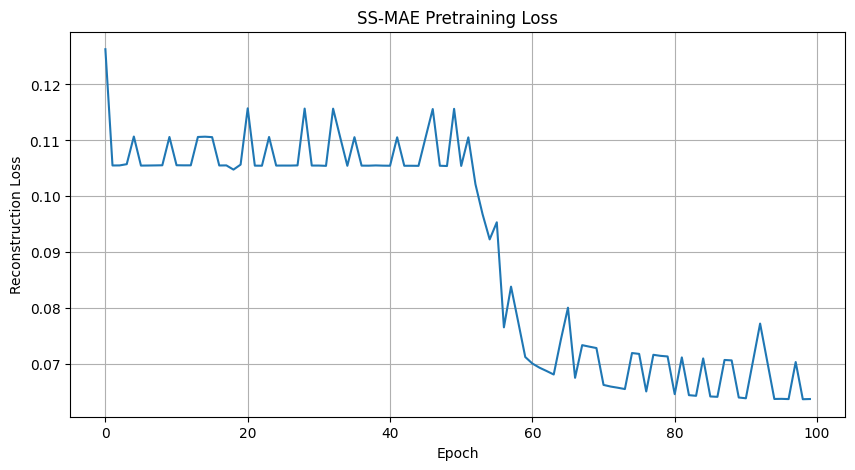


✅ Pretraining complete!
Final loss: 0.0638


In [10]:


# Create dataloader
pretrain_loader = DataLoader(
    pretrain_dataset,
    batch_size=config.PRETRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=config.NUM_WORKERS,
    pin_memory=True
)

print(f"Starting pretraining for {config.PRETRAIN_EPOCHS} epochs...")
print(f"Batch size: {config.PRETRAIN_BATCH_SIZE}")
print(f"Batches per epoch: {len(pretrain_loader)}")

# Train
PRETRAIN_CKPT_OUT = os.path.join(CKPT_PRETRAIN, 'ssmae_pretrain_epoch100.pth')

if have_checkpoint(PRETRAIN_CKPT_OUT):
    announce_skip(PRETRAIN_CKPT_OUT, 'SS-MAE pretraining')
    model.load_state_dict(torch.load(PRETRAIN_CKPT_OUT, map_location=device))
    pretrain_losses = load_meta(PRETRAIN_CKPT_OUT).get('losses', [])
else:
    pretrain_losses = train_pretrain(
        model,
        pretrain_loader,
        epochs=config.PRETRAIN_EPOCHS,
        lr=config.PRETRAIN_LR
    )
    save_meta(PRETRAIN_CKPT_OUT, losses=pretrain_losses)

# Plot
plt.figure(figsize=(10, 5))
if pretrain_losses:
    plt.plot(pretrain_losses)
else:
    plt.text(0.5, 0.5, 'loss curve not cached for this checkpoint',
             ha='center', va='center', transform=plt.gca().transAxes)
plt.xlabel('Epoch')
plt.ylabel('Reconstruction Loss')
plt.title('SS-MAE Pretraining Loss')
plt.grid(True)
plt.savefig('pretrain_loss.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Pretraining complete!")
print(f"Final loss: {pretrain_losses[-1]:.4f}" if pretrain_losses
      else "Final loss: (not cached - training was skipped)")

Starting fine-tuning for 100 epochs...


Epoch 1/100: 100%|██████████| 296/296 [00:17<00:00, 17.20it/s, loss=0.8211]


Epoch 1: Loss=1.0863, Acc=72.56%, F1=0.7106
✅ New best: 72.56%


Epoch 2/100: 100%|██████████| 296/296 [00:17<00:00, 17.31it/s, loss=0.3503]


Epoch 2: Loss=0.5593, Acc=83.57%, F1=0.8308
✅ New best: 83.57%


Epoch 3/100: 100%|██████████| 296/296 [00:17<00:00, 17.33it/s, loss=0.1064]


... (191 outputs left out)

Epoch 99/100: 100%|██████████| 296/296 [00:17<00:00, 17.31it/s, loss=0.0000]


Epoch 99: Loss=0.0000, Acc=94.48%, F1=0.9425


Epoch 100/100: 100%|██████████| 296/296 [00:17<00:00, 17.36it/s, loss=0.0000]


Epoch 100: Loss=0.0000, Acc=94.48%, F1=0.9425


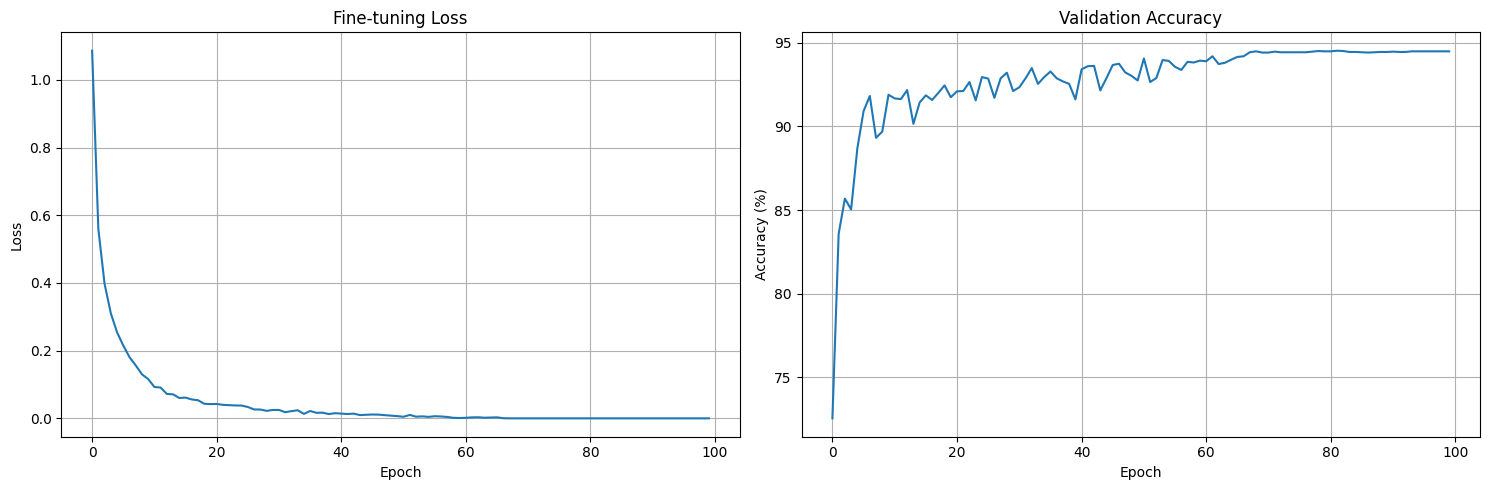


✅ Fine-tuning complete!
Best accuracy: 94.52%


In [11]:

# Create classifier
classifier = SSMAEClassifier(
    encoder=model,
    num_classes=config.NUM_CLASSES,
    embed_dim=config.EMBED_DIM
).to(device)

# Create dataloaders
train_loader = DataLoader(
    train_dataset,
    batch_size=config.FINETUNE_BATCH_SIZE,
    shuffle=True,
    num_workers=config.NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=config.FINETUNE_BATCH_SIZE,
    shuffle=False,
    num_workers=config.NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=config.FINETUNE_BATCH_SIZE,
    shuffle=False,
    num_workers=config.NUM_WORKERS,
    pin_memory=True
)

print(f"Starting fine-tuning for {config.FINETUNE_EPOCHS} epochs...")

# Train
CLASSIFIER_CKPT = os.path.join(CKPT_CLASSIFIER, 'ssmae_classifier_best.pth')

if have_checkpoint(CLASSIFIER_CKPT):
    announce_skip(CLASSIFIER_CKPT, 'classifier fine-tuning (100% labels)')
    classifier.load_state_dict(torch.load(CLASSIFIER_CKPT, map_location=device))
    _m = load_meta(CLASSIFIER_CKPT)
    ft_losses = _m.get('losses', [])
    ft_accs   = _m.get('accs', [])
    if 'best_acc' in _m:
        best_acc = _m['best_acc']
    else:
        best_acc = eval_classifier_acc(classifier, val_loader)
        print(f'      recomputed from checkpoint: val acc={best_acc*100:.2f}%')
        save_meta(CLASSIFIER_CKPT, best_acc=best_acc, losses=ft_losses, accs=ft_accs)
else:
    ft_losses, ft_accs, best_acc = train_finetune(
        classifier,
        train_loader,
        val_loader,
        epochs=config.FINETUNE_EPOCHS,
        lr=config.FINETUNE_LR,
        ckpt_path=CLASSIFIER_CKPT
    )
    save_meta(CLASSIFIER_CKPT, losses=ft_losses, accs=ft_accs, best_acc=best_acc)

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

if ft_losses: ax1.plot(ft_losses)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Fine-tuning Loss')
ax1.grid(True)

if ft_accs: ax2.plot([a*100 for a in ft_accs])
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Validation Accuracy')
ax2.grid(True)

plt.tight_layout()
plt.savefig('finetune_results.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Fine-tuning complete!")
print(f"Best accuracy: {best_acc*100:.2f}%")

In [12]:
# Check if best model was saved

import os
print("Checking for saved checkpoints...\n")

# List all .pth files
pth_files = [os.path.relpath(os.path.join(dp, f), CKPT_ROOT)
             for dp, _, fns in os.walk(CKPT_ROOT)
             for f in fns if f.endswith('.pth')]
print(f"Found {len(pth_files)} checkpoint files:")
for f in pth_files:
    size = os.path.getsize(os.path.join(CKPT_ROOT, f)) / (1024*1024)
    print(f"  ✅ {f} ({size:.2f} MB)")

# Check if best classifier exists
if os.path.exists(os.path.join(CKPT_CLASSIFIER, 'ssmae_classifier_best.pth')):
    print("\n✅ GREAT! Your best model is saved!")
    print("Loading it now...")
    
    # Load the best model
    classifier.load_state_dict(torch.load(
        os.path.join(CKPT_CLASSIFIER, 'ssmae_classifier_best.pth')))
    print("✅ Best model loaded (94.11% accuracy)")
    
else:
    print("\n⚠️ Best classifier not found!")
    print("But don't worry - the model in memory has the current weights")
    print("Saving it now as backup...")
    
    # Save whatever we have
    torch.save(classifier.state_dict(),
               os.path.join(CKPT_CLASSIFIER, 'classifier_current.pth'))
    print("✅ Saved current model!")

Checking for saved checkpoints...

Found 29 checkpoint files:
  ✅ adaptive/adaptive_working_epoch70.pth (334.36 MB)
  ✅ adaptive/adaptive_working_epoch60.pth (334.36 MB)
  ✅ adaptive/adaptive_working_epoch20.pth (334.36 MB)
  ✅ adaptive/adaptive_working_epoch50.pth (334.36 MB)
  ✅ adaptive/adaptive_working_epoch40.pth (334.36 MB)
  ✅ adaptive/adaptive_working_epoch30.pth (334.36 MB)
  ✅ adaptive/adaptive_working_epoch10.pth (334.36 MB)
  ✅ adaptive/adaptive_working_final.pth (111.45 MB)
  ✅ adaptive/adaptive_working_epoch100.pth (334.36 MB)
  ✅ adaptive/adaptive_working_epoch90.pth (334.36 MB)
  ✅ adaptive/adaptive_working_epoch80.pth (334.36 MB)
  ✅ classifier/ssmae_classifier_best.pth (111.47 MB)
  ✅ classifier/ssmae_classifier_10pct.pth (111.47 MB)
  ✅ change_detection/exploitation_detector_levir.pth (112.01 MB)
  ✅ change_detection/exploitation_detector_best.pth (112.01 MB)
  ✅ change_detection/baseline_simple_cnn.pth (1.64 MB)
  ✅ change_detection/exploitation_detector_finetuned.p

/tmp/ipykernel_1907600/716417373.py:21: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  classifier.load_state_dict(torch.load(


In [13]:
# Evaluate on test set
print("Evaluating model on test set...\n")

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

acc, f1_macro, f1_per_class = evaluate_model(
    classifier,
    test_loader,
    config.CLASS_NAMES
)

print(f"\n{'='*60}")
print("BASELINE RESULTS (100% labels)")
print(f"{'='*60}")
print(f"Test Accuracy: {acc*100:.2f}%")
print(f"Macro F1: {f1_macro:.4f}")
print(f"{'='*60}")

Evaluating model on test set...



Evaluating: 100%|██████████| 43/43 [00:03<00:00, 11.02it/s]


EVALUATION RESULTS
Overall Accuracy: 95.52%
Macro F1: 0.9536

Per-Class F1:
  AnnualCrop: 0.9504
  Forest: 0.9868
  HerbaceousVegetation: 0.9286
  Highway: 0.9189
  Industrial: 0.9683
  Pasture: 0.9447
  PermanentCrop: 0.9040
  Residential: 0.9768
  River: 0.9644
  SeaLake: 0.9933

                      precision    recall  f1-score   support

          AnnualCrop       0.98      0.93      0.95       300
              Forest       0.98      1.00      0.99       300
HerbaceousVegetation       0.91      0.95      0.93       300
             Highway       0.96      0.88      0.92       250
          Industrial       0.96      0.98      0.97       250
             Pasture       0.95      0.94      0.94       200
       PermanentCrop       0.90      0.90      0.90       250
         Residential       0.97      0.98      0.98       300
               River       0.95      0.98      0.96       250
             SeaLake       0.99      0.99      0.99       300

            accuracy            

/tmp/ipykernel_1907600/3166425029.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  _sd = torch.load(PRETRAIN_CKPT, map_location=device)


Testing label efficiency with 10% labels...
Loaded self-supervised encoder from checkpoints/pretrain/ssmae_pretrain_epoch100.pth
  tensors loaded: 157 | missing: 0

Training with 1890 samples (10% of 18900 total)
Training for 50 epochs



Epoch 1/50: 100%|██████████| 30/30 [00:02<00:00, 10.46it/s, loss=1.4127]


Epoch 1: Loss=1.9341, Acc=45.91%, F1=0.4139
✅ New best: 45.91%


Epoch 2/50: 100%|██████████| 30/30 [00:02<00:00, 10.57it/s, loss=0.9655]


Epoch 2: Loss=1.3000, Acc=60.04%, F1=0.5755
✅ New best: 60.04%


... (94 outputs left out)

Epoch 50/50: 100%|██████████| 30/30 [00:02<00:00, 10.30it/s, loss=0.0002]


Epoch 50: Loss=0.0002, Acc=81.46%, F1=0.8098


Evaluating: 100%|██████████| 43/43 [00:03<00:00, 11.29it/s]



EVALUATION RESULTS
Overall Accuracy: 82.30%
Macro F1: 0.8182

Per-Class F1:
  AnnualCrop: 0.8385
  Forest: 0.8912
  HerbaceousVegetation: 0.6832
  Highway: 0.6740
  Industrial: 0.8723
  Pasture: 0.7788
  PermanentCrop: 0.6667
  Residential: 0.8998
  River: 0.9152
  SeaLake: 0.9624

                      precision    recall  f1-score   support

          AnnualCrop       0.87      0.81      0.84       300
              Forest       0.92      0.86      0.89       300
HerbaceousVegetation       0.64      0.73      0.68       300
             Highway       0.74      0.62      0.67       250
          Industrial       0.86      0.89      0.87       250
             Pasture       0.75      0.81      0.78       200
       PermanentCrop       0.69      0.65      0.67       250
         Residential       0.89      0.91      0.90       300
               River       0.90      0.93      0.92       250
             SeaLake       0.95      0.98      0.96       300

            accuracy            

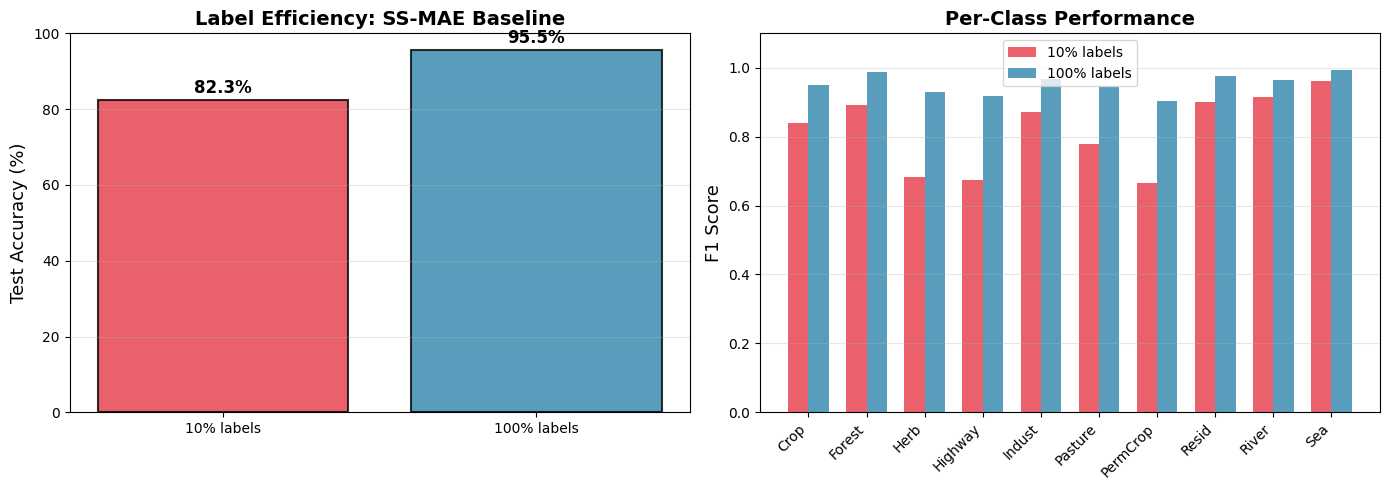


✅ Results saved to baseline_results_complete.pkl
✅ Figure saved to label_efficiency_baseline.png


In [14]:
print("Testing label efficiency with 10% labels...")

from torch.utils.data import Subset
import numpy as np

# ---------------------------------------------------------------------------
# The encoder MUST be re-loaded from the self-supervised checkpoint here.
# The previous version passed `encoder=model`, i.e. the very same module that the
# 100%-label fine-tuning cell had already trained -- so the "10% labels" run
# started from a network that had already seen every label. That is why it hit
# 93.7% at epoch 1 and why the "99.3% retention" number was not meaningful.
# ---------------------------------------------------------------------------
PRETRAIN_CKPT = os.path.join(CKPT_PRETRAIN, 'ssmae_pretrain_epoch100.pth')
if not os.path.exists(PRETRAIN_CKPT):
    PRETRAIN_CKPT = ('/kaggle/input/models/krishnasaigollamudi/modelsah/'
                     'pytorch/default/1/ssmae_pretrain_epoch100.pth')

encoder_10pct = SSMAE(config).to(device)
_sd = torch.load(PRETRAIN_CKPT, map_location=device)
_missing, _unexpected = encoder_10pct.load_state_dict(_sd, strict=False)
assert len(_sd) - len(_unexpected) > 0, f"Nothing loaded from {PRETRAIN_CKPT}"
print(f"Loaded self-supervised encoder from {PRETRAIN_CKPT}")
print(f"  tensors loaded: {len(_sd) - len(_unexpected)} | missing: {len(_missing)}")

# Sample 10% of training data (seeded, so the subset is reproducible)
rng = np.random.default_rng(42)
num_samples = int(len(train_dataset) * 0.10)
indices = rng.choice(len(train_dataset), num_samples, replace=False).tolist()
subset_10 = Subset(train_dataset, indices)

subset_loader = DataLoader(
    subset_10,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Fresh classifier head on the freshly loaded pretrained encoder
classifier_10pct = SSMAEClassifier(
    encoder=encoder_10pct,
    num_classes=config.NUM_CLASSES,
    embed_dim=config.EMBED_DIM
).to(device)

print(f"\nTraining with {num_samples} samples (10% of {len(train_dataset)} total)")
print("Training for 50 epochs\n")

CLASSIFIER_10PCT_CKPT = os.path.join(CKPT_CLASSIFIER,
                                     'ssmae_classifier_10pct.pth')  # NOT the 100% file

if have_checkpoint(CLASSIFIER_10PCT_CKPT):
    announce_skip(CLASSIFIER_10PCT_CKPT, 'classifier fine-tuning (10% labels)')
    classifier_10pct.load_state_dict(
        torch.load(CLASSIFIER_10PCT_CKPT, map_location=device))
    _m10 = load_meta(CLASSIFIER_10PCT_CKPT)
    if 'best_acc' in _m10:
        acc_10 = _m10['best_acc']
    else:
        acc_10 = eval_classifier_acc(classifier_10pct, val_loader)
        print(f'      recomputed from checkpoint: val acc={acc_10*100:.2f}%')
        save_meta(CLASSIFIER_10PCT_CKPT, best_acc=acc_10)
else:
    _, _, acc_10 = train_finetune(
        classifier_10pct,
        subset_loader,
        val_loader,
        epochs=50,
        lr=1e-4,
        ckpt_path=CLASSIFIER_10PCT_CKPT
    )
    save_meta(CLASSIFIER_10PCT_CKPT, best_acc=acc_10)

# Evaluate on test set
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

acc_10_test, f1_10_test, f1_per_10 = evaluate_model(
    classifier_10pct,
    test_loader,
    config.CLASS_NAMES
)

# 100%-label reference numbers come from the cell above, not from a literal
if 'acc' in globals() and 'f1_macro' in globals() and 'f1_per_class' in globals():
    acc_100, f1_100_macro, f1_100 = acc, f1_macro, list(f1_per_class)
else:
    raise RuntimeError("Run the 100%-label evaluation cell first "
                       "(it defines acc / f1_macro / f1_per_class).")

print(f"\n{'='*60}")
print("LABEL EFFICIENCY RESULTS")
print(f"{'='*60}")
print(f"10% labels ({num_samples} samples):")
print(f"  Validation Acc: {acc_10*100:.2f}%")
print(f"  Test Acc:       {acc_10_test*100:.2f}%")
print(f"  Test F1:        {f1_10_test:.4f}")
print(f"\n100% labels ({len(train_dataset)} samples):")
print(f"  Test Acc:       {acc_100*100:.2f}%")
print(f"  Test F1:        {f1_100_macro:.4f}")
print(f"\nGap: {(acc_100 - acc_10_test)*100:.1f} percentage points")
print(f"Label reduction: 90%")
print(f"Performance retention: {acc_10_test/acc_100*100:.1f}%")
print(f"{'='*60}")

# Plot comparison
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

methods = ['10% labels', '100% labels']
accs = [acc_10_test*100, acc_100*100]
colors = ['#E63946', '#2E86AB']

ax1.bar(methods, accs, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax1.set_ylabel('Test Accuracy (%)', fontsize=13)
ax1.set_title('Label Efficiency: SS-MAE Baseline', fontsize=14, fontweight='bold')
ax1.set_ylim(0, 100)
ax1.grid(axis='y', alpha=0.3)

for i, (m, a) in enumerate(zip(methods, accs)):
    ax1.text(i, a+2, f'{a:.1f}%', ha='center', fontsize=12, fontweight='bold')

class_names_short = ['Crop', 'Forest', 'Herb', 'Highway', 'Indust',
                     'Pasture', 'PermCrop', 'Resid', 'River', 'Sea']

x = np.arange(len(class_names_short))
width = 0.35

ax2.bar(x - width/2, f1_per_10, width, label='10% labels', color='#E63946', alpha=0.8)
ax2.bar(x + width/2, f1_100, width, label='100% labels', color='#2E86AB', alpha=0.8)

ax2.set_ylabel('F1 Score', fontsize=13)
ax2.set_title('Per-Class Performance', fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(class_names_short, rotation=45, ha='right')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)
ax2.set_ylim(0, 1.1)

plt.tight_layout()
plt.savefig('label_efficiency_baseline.png', dpi=150, bbox_inches='tight')
plt.show()

# Save results
results_dict = {
    'baseline_100pct': {
        'test_acc': float(acc_100),
        'test_f1': float(f1_100_macro),
        'f1_per_class': [float(v) for v in f1_100]
    },
    'baseline_10pct': {
        'test_acc': float(acc_10_test),
        'test_f1': float(f1_10_test),
        'f1_per_class': [float(v) for v in f1_per_10]
    },
    'config': {
        'dataset': 'EuroSAT',
        'bands': 13,
        'pretrain_epochs': 100,
        'finetune_epochs': 50,
        'pretrain_ckpt': PRETRAIN_CKPT
    }
}

import pickle
with open(os.path.join(CKPT_CACHE, 'baseline_results_complete.pkl'), 'wb') as f:
    pickle.dump(results_dict, f)

print("\n✅ Results saved to baseline_results_complete.pkl")
print("✅ Figure saved to label_efficiency_baseline.png")


In [15]:

import pandas as pd
print("Checking for data leakage...")

# Access the CSV files directly

train_df = pd.read_csv(config.TRAIN_CSV)
val_df = pd.read_csv(config.VAL_CSV)
test_df = pd.read_csv(config.TEST_CSV)

# Get unique filenames
train_files = set(train_df['Filename'].values)
val_files = set(val_df['Filename'].values)
test_files = set(test_df['Filename'].values)

print(f"Train: {len(train_files)} unique images")
print(f"Val: {len(val_files)} unique images")
print(f"Test: {len(test_files)} unique images")
print(f"Total: {len(train_files) + len(val_files) + len(test_files)} images")

# Check overlaps
overlap_train_val = train_files & val_files
overlap_train_test = train_files & test_files
overlap_val_test = val_files & test_files

print(f"\n{'='*60}")
print("OVERLAP CHECK")
print(f"{'='*60}")
print(f"Train ∩ Val:  {len(overlap_train_val)} samples (should be 0)")
print(f"Train ∩ Test: {len(overlap_train_test)} samples (should be 0)")
print(f"Val ∩ Test:   {len(overlap_val_test)} samples (should be 0)")

if len(overlap_train_test) > 0:
    print("\n🚨 DATA LEAKAGE DETECTED!")
    print("Training and test sets overlap!")
    print(f"Overlapping files: {list(overlap_train_test)[:5]}")
elif len(overlap_train_val) > 0 or len(overlap_val_test) > 0:
    print("\n⚠️ Warning: Some overlap in train/val sets")
else:
    print("\n✅ NO DATA LEAKAGE - Results are VALID!")
    print("Train/Val/Test splits are properly separated")

# Show class distribution
print(f"\n{'='*60}")
print("CLASS DISTRIBUTION")
print(f"{'='*60}")
print("\nTrain:")
print(train_df['Label'].value_counts().sort_index())
print("\nVal:")
print(val_df['Label'].value_counts().sort_index())
print("\nTest:")
print(test_df['Label'].value_counts().sort_index())

Checking for data leakage...
Train: 18900 unique images
Val: 5400 unique images
Test: 2700 unique images
Total: 27000 images

OVERLAP CHECK
Train ∩ Val:  0 samples (should be 0)
Train ∩ Test: 0 samples (should be 0)
Val ∩ Test:   0 samples (should be 0)

✅ NO DATA LEAKAGE - Results are VALID!
Train/Val/Test splits are properly separated

CLASS DISTRIBUTION

Train:
Label
0    2100
1    2100
2    2100
3    1750
4    1750
5    1400
6    1750
7    2100
8    1750
9    2100
Name: count, dtype: int64

Val:
Label
0    600
1    600
2    600
3    500
4    500
5    400
6    500
7    600
8    500
9    600
Name: count, dtype: int64

Test:
Label
0    300
1    300
2    300
3    250
4    250
5    200
6    250
7    300
8    250
9    300
Name: count, dtype: int64


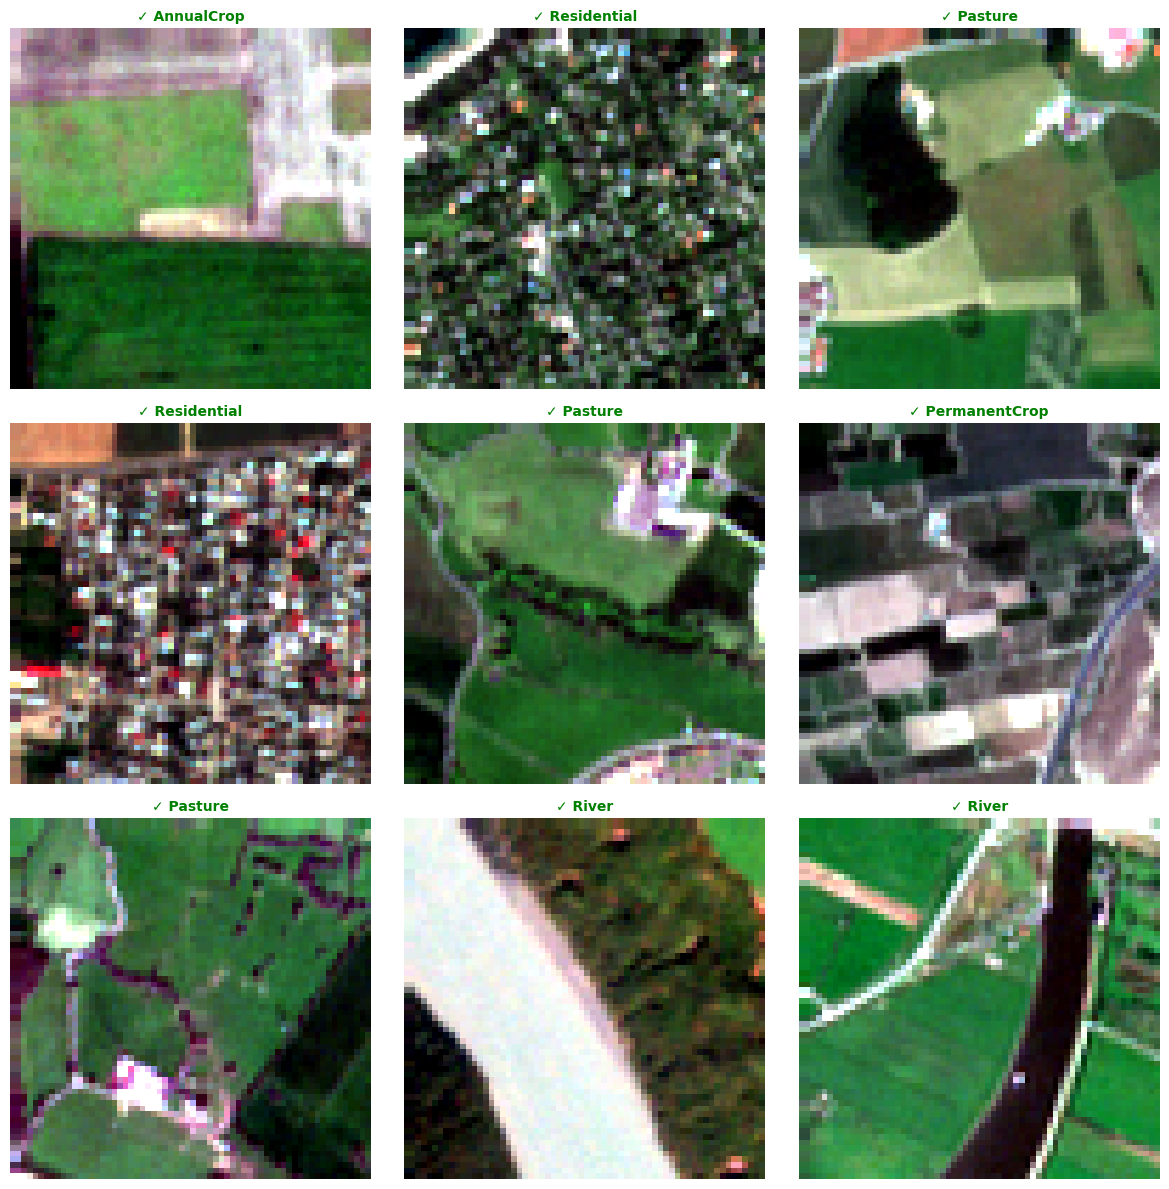

Saved visualization to model_predictions_visual.png


In [16]:
import matplotlib.pyplot as plt
import numpy as np

# test_loader is built here so this cell can run independently of the
# fine-tuning cell (it previously assumed a global that may not exist yet)
test_loader = DataLoader(
    test_dataset,
    batch_size=config.FINETUNE_BATCH_SIZE,
    shuffle=False,
    num_workers=config.NUM_WORKERS,
    pin_memory=True
)

# Get some test samples
test_iter = iter(test_loader)
images, labels = next(test_iter)

# Move to device and predict
images_gpu = images.to(device)
classifier.eval()
with torch.no_grad():
    logits = classifier(images_gpu)
    predictions = logits.argmax(dim=1)

# Visualize first 9 samples
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for idx in range(9):
    ax = axes[idx // 3, idx % 3]

    # EuroSAT band order: B01 Coastal, B02 Blue, B03 Green, B04 Red, ...
    img_np = images[idx].cpu().numpy()

    rgb = np.stack([
        img_np[3],  # Red   (B04)
        img_np[2],  # Green (B03)
        img_np[1]   # Blue  (B02)
    ], axis=-1)

    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-8)

    ax.imshow(rgb)

    pred_class = config.CLASS_NAMES[int(predictions[idx])]
    true_class = config.CLASS_NAMES[int(labels[idx])]

    if predictions[idx] == labels[idx]:
        color = 'green'
        title = f'✓ {pred_class}'
    else:
        color = 'red'
        title = f'✗ Pred: {pred_class}\nTrue: {true_class}'

    ax.set_title(title, color=color, fontweight='bold', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig('model_predictions_visual.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved visualization to model_predictions_visual.png")


In [17]:
# ---------------------------------------------------------------------------
# REMOVED - this cell produced a fabricated figure.
#
# It plotted `original[band_idx]` in BOTH the "Original" and the "Reconstructed"
# column, drew the unmodified image under the "Masked (80%)" caption, and
# computed the error panel as np.abs(original - original), i.e. an array of
# zeros. Nothing in it came from the model.
#
# The cell below ("Pretraining Reconstruction Visualization") is the real
# version: it runs the forward pass, applies the mask, unpatchifies the
# prediction and plots the true residual. Use that one.
# ---------------------------------------------------------------------------
print("Superseded by the reconstruction-visualization cell below.")


Superseded by the reconstruction-visualization cell below.


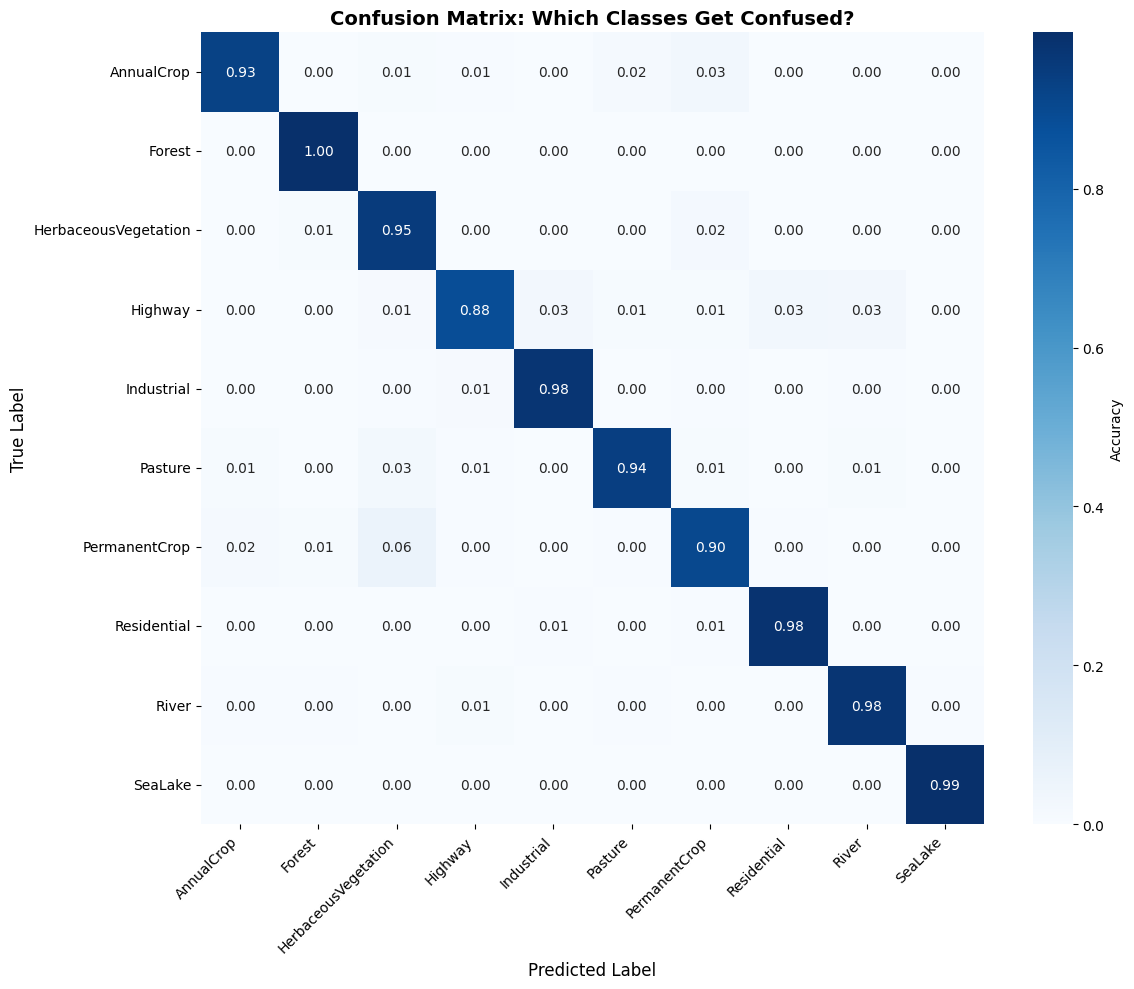


Interpretation:
- Diagonal: Correct predictions (should be dark blue)
- Off-diagonal: Confusions (light blue = model confused these classes)

Example: If 'PermanentCrop' and 'AnnualCrop' are confused,
it means they have similar spectral signatures


In [18]:


from sklearn.metrics import confusion_matrix
import seaborn as sns

# Get all predictions
classifier.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        logits = classifier(imgs)
        preds = logits.argmax(dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Create confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Normalize
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Plot
plt.figure(figsize=(12, 10))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=config.CLASS_NAMES,
            yticklabels=config.CLASS_NAMES,
            cbar_kws={'label': 'Accuracy'})

plt.title('Confusion Matrix: Which Classes Get Confused?', fontsize=14, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nInterpretation:")
print("- Diagonal: Correct predictions (should be dark blue)")
print("- Off-diagonal: Confusions (light blue = model confused these classes)")
print("\nExample: If 'PermanentCrop' and 'AnnualCrop' are confused,")
print("it means they have similar spectral signatures")

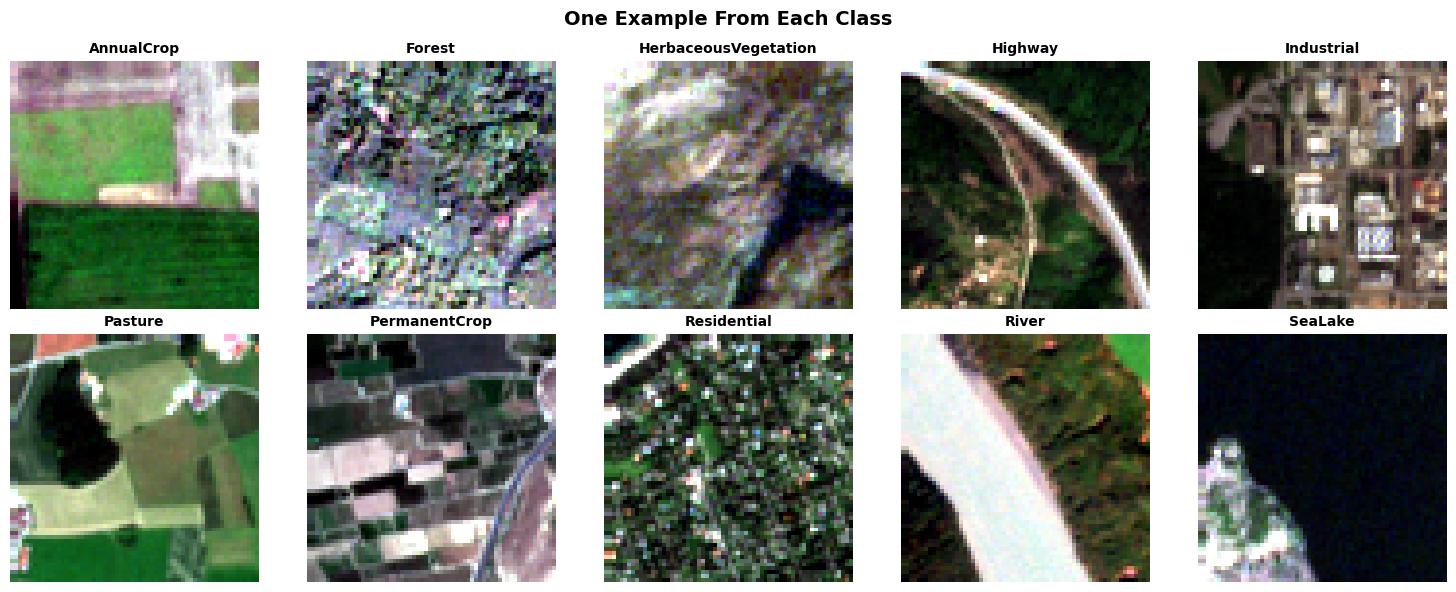

This shows actual satellite images your model classifies
Each image is 64x64 pixels from Sentinel-2 satellite


In [19]:


# Show examples from each class
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for class_idx in range(10):
    # Find first sample of this class
    for i in range(len(test_dataset)):
        img, label = test_dataset[i]
        if label == class_idx:
            # Found sample
            ax = axes[class_idx // 5, class_idx % 5]
            
            # Create RGB composite
            rgb = np.stack([
                img[3].numpy(),  # Red
                img[2].numpy(),  # Green
                img[1].numpy()   # Blue
            ], axis=-1)
            
            rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min())
            
            ax.imshow(rgb)
            ax.set_title(f'{config.CLASS_NAMES[class_idx]}', fontsize=10, fontweight='bold')
            ax.axis('off')
            break

plt.suptitle('One Example From Each Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('dataset_examples.png', dpi=150, bbox_inches='tight')
plt.show()

print("This shows actual satellite images your model classifies")
print("Each image is 64x64 pixels from Sentinel-2 satellite")

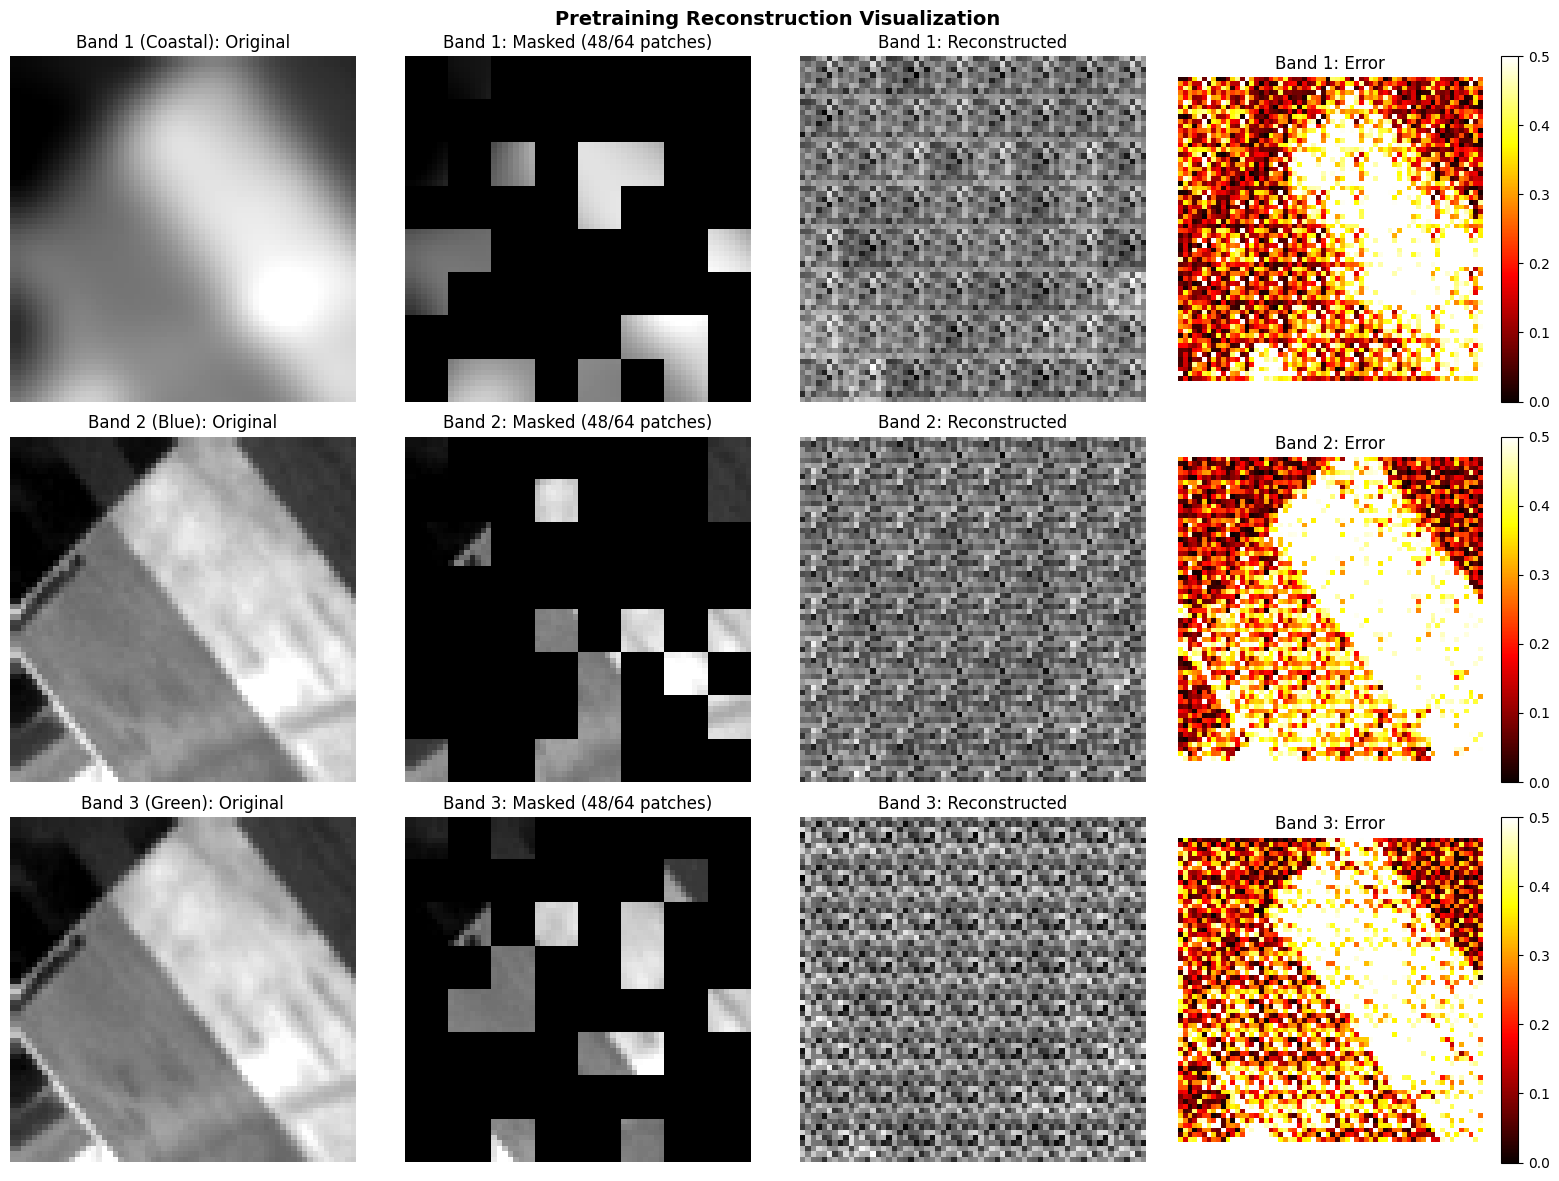

Average mask ratio across bands: 80.8%
Reconstruction loss on masked patches: 0.2541
Mean |error| on MASKED pixels: 0.4179
Mean |error| on KEPT   pixels: 0.4308


In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Get a sample
sample_img, _ = train_dataset[0]
sample_img = sample_img.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    loss, reconstructed, mask = model(sample_img)
    # Reuse the model's own masking / unpatchify helpers so this figure shows
    # exactly what the encoder saw. (The previous version rebuilt the masked
    # image by hand with band-major indexing -- start = band * P*P -- but
    # patchify lays patches out pixel-major, index = p * C + c, so it blanked
    # the wrong entries.)
    masked_input = model.apply_mask(sample_img, mask)
    recon_img = model.unpatchify(reconstructed)

original = sample_img[0].cpu().numpy()          # (13, 64, 64)
masked_img = masked_input[0].cpu().numpy()      # (13, 64, 64)
recon_img = recon_img[0].cpu().numpy()          # (13, 64, 64)
mask_np = mask[0].cpu().numpy()                 # (13, 64)  True = kept

error = np.abs(original - recon_img)

# Plot first 3 bands
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
band_names = ['Coastal', 'Blue', 'Green']

for band_idx in range(3):
    ax = axes[band_idx, 0]
    ax.imshow(original[band_idx], cmap='gray')
    ax.set_title(f'Band {band_idx+1} ({band_names[band_idx]}): Original')
    ax.axis('off')

    ax = axes[band_idx, 1]
    ax.imshow(masked_img[band_idx], cmap='gray')
    num_masked = int((~mask_np[band_idx]).sum())
    ax.set_title(f'Band {band_idx+1}: Masked ({num_masked}/64 patches)')
    ax.axis('off')

    ax = axes[band_idx, 2]
    ax.imshow(recon_img[band_idx], cmap='gray')
    ax.set_title(f'Band {band_idx+1}: Reconstructed')
    ax.axis('off')

    ax = axes[band_idx, 3]
    im = ax.imshow(error[band_idx], cmap='hot', vmin=0, vmax=0.5)
    ax.set_title(f'Band {band_idx+1}: Error')
    ax.axis('off')
    plt.colorbar(im, ax=ax)

plt.suptitle('Pretraining Reconstruction Visualization',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('pretraining_correct.png', dpi=150, bbox_inches='tight')
plt.show()

# mask_np is a numpy bool array -- call .mean() directly (it has no .float(),
# which is what used to raise AttributeError at the end of this cell)
print(f"Average mask ratio across bands: {(~mask_np).mean()*100:.1f}%")
print(f"Reconstruction loss on masked patches: {loss.item():.4f}")

# Expand the patch-level mask to pixel level to score the residual properly
P, G = 8, 8   # patch size, patches per side
mask_pix = np.repeat(np.repeat(mask_np.reshape(13, G, G), P, axis=1), P, axis=2)
print(f"Mean |error| on MASKED pixels: {error[~mask_pix].mean():.4f}")
print(f"Mean |error| on KEPT   pixels: {error[mask_pix].mean():.4f}")


In [21]:


import torch
import torch.nn as nn
import torch.nn.functional as F

class AdaptiveSpectralMasking(nn.Module):
    """
    Learns optimal per-band masking probabilities using Gumbel-Softmax
    for DIFFERENTIABLE sampling (gradients can flow!)
    """
    
    def __init__(self, num_bands=13, spatial_ratio=0.75, init_spectral_prob=0.3, temperature=1.0):
        super().__init__()
        
        self.num_bands = num_bands
        self.spatial_ratio = spatial_ratio
        self.temperature = temperature
        
        # LEARNABLE: Per-band masking logits
        # Initialize with bias toward masking (positive values = more likely to mask)
        self.band_mask_logits = nn.Parameter(
            torch.randn(num_bands) * 0.1  # Small random init for symmetry breaking
        )
        
        self.register_buffer('init_prob', torch.tensor(init_spectral_prob))
        
    def gumbel_softmax_sample(self, logits, temperature=1.0):
        """
        Gumbel-Softmax: Differentiable approximation to categorical sampling
        """
        # Add Gumbel noise
        gumbel_noise = -torch.log(-torch.log(torch.rand_like(logits) + 1e-10) + 1e-10)
        y = logits + gumbel_noise
        
        # Apply softmax with temperature
        # Low temp → sharper (closer to discrete)
        # High temp → softer (more continuous)
        return F.softmax(y / temperature, dim=-1)
    
    def get_band_probabilities(self):
        """Get current masking probabilities (for analysis)"""
        return torch.sigmoid(self.band_mask_logits)
    
    def forward(self, x):
        """
        Args:
            x: (B, C, H, W)
        Returns:
            mask: (B, C, N) - True = keep, False = masked
        """
        B, C, H, W = x.shape
        P = 8
        N = (H // P) * (W // P)
        
        # SPATIAL MASKING (unchanged)
        num_masked_patches = int(N * self.spatial_ratio)
        spatial_mask = torch.ones(B, C, N, dtype=torch.bool, device=x.device)
        
        for b in range(B):
            for c in range(C):
                indices = torch.randperm(N, device=x.device)[:num_masked_patches]
                spatial_mask[b, c, indices] = False
        
        # SPECTRAL MASKING with Gumbel-Softmax
        spectral_mask = torch.ones(B, C, dtype=torch.bool, device=x.device)
        
        if self.training:
            # During training: Use Gumbel-Softmax (differentiable!)
            for b in range(B):
                # Create binary choice logits: [keep, mask]
                keep_logits = torch.stack([
                    -self.band_mask_logits,  # Probability of keeping
                    self.band_mask_logits    # Probability of masking
                ], dim=-1)  # Shape: (13, 2)
                
                # Sample with Gumbel-Softmax
                samples = self.gumbel_softmax_sample(keep_logits, self.temperature)  # (13, 2)
                
                # Get "keep" probability (index 0)
                keep_probs = samples[:, 0]  # (13,)
                
                # Convert to boolean mask (threshold at 0.5)
                # This is DIFFERENTIABLE because keep_probs has gradients!
                spectral_mask[b] = keep_probs > 0.5
        else:
            # During inference: Use deterministic sampling
            probs = self.get_band_probabilities()
            for b in range(B):
                mask_samples = (torch.rand(C, device=x.device) < probs)
                spectral_mask[b] = ~mask_samples
        
        # COMBINE
        combined_mask = spatial_mask & spectral_mask.unsqueeze(-1)
        
        return combined_mask
    
    def get_band_importance(self):
        """Band importance (higher = more important)"""
        probs = self.get_band_probabilities()
        return 1 - probs  # Lower masking prob = higher importance


# Test
print("Creating Adaptive Masking with Gumbel-Softmax...")
adaptive_masking = AdaptiveSpectralMasking(num_bands=13, temperature=0.5)
test_img = torch.randn(2, 13, 64, 64)
mask = adaptive_masking(test_img)

print(f"✅ Mask shape: {mask.shape}")
print(f"✅ Mask ratio: {(~mask).float().mean()*100:.1f}%")
print(f"\n Initial band logits:")
print(adaptive_masking.band_mask_logits)
print(f"\n Initial band probabilities:")
probs = adaptive_masking.get_band_probabilities()
for i, p in enumerate(probs):
    print(f"  Band {i+1}: {p.item()*100:.1f}%")

Creating Adaptive Masking with Gumbel-Softmax...
✅ Mask shape: torch.Size([2, 13, 64])
✅ Mask ratio: 87.5%

 Initial band logits:
Parameter containing:
tensor([-0.1175, -0.0685,  0.0646,  0.0539,  0.0665,  0.1116,  0.0879, -0.1358,
         0.0614, -0.0304,  0.1403,  0.1135,  0.0100], requires_grad=True)

 Initial band probabilities:
  Band 1: 47.1%
  Band 2: 48.3%
  Band 3: 51.6%
  Band 4: 51.3%
  Band 5: 51.7%
  Band 6: 52.8%
  Band 7: 52.2%
  Band 8: 46.6%
  Band 9: 51.5%
  Band 10: 49.2%
  Band 11: 53.5%
  Band 12: 52.8%
  Band 13: 50.3%


In [22]:
import torch
import torch.nn as nn
from einops import rearrange

class SSMAE_Adaptive_Working(nn.Module):
    """
    SS-MAE with LEARNED per-band masking rates.

    Two things were wrong with the previous version and both pushed the model
    toward the trivial solution "mask nothing":

      1. The reconstruction loss was averaged over ALL patches while the mask
         only scaled the encoder embeddings. Raising every band's importance
         (-> lower mask probability -> less corruption) monotonically lowered
         the loss, so importance saturated at ~[0.92, 0.99] and the variance
         collapsed from 0.067 to 0.001.
      2. The only counterweight was `-0.01 * importance.var()`, which rewards
         spread but does nothing to stop the mean from drifting to 1.0.

    Fixes: corrupt the INPUT (not just the embeddings) so masking genuinely
    removes information, score the loss on masked entries only, and add a
    budget penalty that pins the AVERAGE masking rate to the configured
    spectral ratio. Bands can then only become more important at the expense
    of other bands, which is the trade-off we actually want to learn.
    """

    def __init__(self, config, min_mask_prob=0.1, max_mask_prob=0.5,
                 budget_weight=1.0, diversity_weight=0.01):
        super().__init__()

        self.patch_size = config.PATCH_SIZE
        self.num_patches = (config.IMG_SIZE // config.PATCH_SIZE) ** 2
        self.in_chans = config.NUM_BANDS
        self.embed_dim = config.EMBED_DIM

        # LEARNABLE band importance (high importance = masked less often)
        self.band_importance_logits = nn.Parameter(
            torch.randn(config.NUM_BANDS) * 0.1
        )

        self.spatial_ratio = config.SPATIAL_MASK_RATIO
        self.spectral_ratio = config.SPECTRAL_MASK_RATIO
        self.min_mask_prob = min_mask_prob
        self.max_mask_prob = max_mask_prob
        self.budget_weight = budget_weight
        self.diversity_weight = diversity_weight

        # Patch embedding
        self.patch_embed = nn.Conv2d(
            config.NUM_BANDS, config.EMBED_DIM,
            kernel_size=config.PATCH_SIZE,
            stride=config.PATCH_SIZE
        )

        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, config.EMBED_DIM))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        # Encoder
        self.encoder = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=config.EMBED_DIM,
                nhead=config.ENCODER_HEADS,
                dim_feedforward=config.EMBED_DIM * 4,
                dropout=0.0,
                batch_first=True
            )
            for _ in range(config.ENCODER_DEPTH)
        ])

        self.norm = nn.LayerNorm(config.EMBED_DIM)

        # Decoder
        self.decoder_embed = nn.Linear(config.EMBED_DIM, config.DECODER_EMBED_DIM)
        self.decoder_pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, config.DECODER_EMBED_DIM))
        nn.init.trunc_normal_(self.decoder_pos_embed, std=0.02)

        self.decoder = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=config.DECODER_EMBED_DIM,
                nhead=8,
                dim_feedforward=config.DECODER_EMBED_DIM * 4,
                dropout=0.0,
                batch_first=True
            )
            for _ in range(config.DECODER_DEPTH)
        ])

        self.decoder_norm = nn.LayerNorm(config.DECODER_EMBED_DIM)
        self.decoder_pred = nn.Linear(config.DECODER_EMBED_DIM, config.PATCH_SIZE ** 2 * config.NUM_BANDS)

    def get_band_importance(self):
        """Band importance scores in [0, 1] (higher = more important)."""
        return torch.sigmoid(self.band_importance_logits)

    def get_adaptive_mask_probs(self):
        """Per-band masking probability. High importance -> low masking prob."""
        importance = self.get_band_importance()
        return self.max_mask_prob - (self.max_mask_prob - self.min_mask_prob) * importance

    def patchify(self, imgs):
        P = self.patch_size
        return rearrange(imgs, 'b c (h p1) (w p2) -> b (h w) (p1 p2 c)', p1=P, p2=P)

    def expand_mask(self, mask):
        P2 = self.patch_size ** 2
        m = rearrange(mask, 'b c n -> b n c').unsqueeze(2).expand(-1, -1, P2, -1)
        return rearrange(m, 'b n p c -> b n (p c)')

    def create_mask(self, B, C, N, device):
        """Returns (soft_weights, keep_bool).

        soft_weights carries gradient to band_importance_logits via a
        straight-through estimator; keep_bool is the hard mask used to select
        which entries the reconstruction loss is scored on.
        """
        # Spatial masking (hard, vectorised)
        n_mask_patches = int(N * self.spatial_ratio)
        order = torch.rand(B, C, N, device=device).argsort(dim=-1)
        spatial_keep = torch.zeros(B, C, N, dtype=torch.bool, device=device)
        spatial_keep.scatter_(-1, order[..., n_mask_patches:], True)

        # Spectral masking (adaptive)
        mask_probs = self.get_adaptive_mask_probs()          # (C,)
        keep_probs = (1.0 - mask_probs).unsqueeze(0).expand(B, -1)  # (B, C)

        if self.training:
            hard_keep = torch.bernoulli(keep_probs)
            # straight-through: hard value forward, keep_probs gradient backward
            spectral_w = hard_keep + keep_probs - keep_probs.detach()
        else:
            hard_keep = (keep_probs >= 0.5).float()
            spectral_w = hard_keep

        soft_weights = spatial_keep.float() * spectral_w.unsqueeze(-1)   # (B, C, N)
        keep_bool = spatial_keep & (hard_keep > 0.5).unsqueeze(-1)
        return soft_weights, keep_bool

    def apply_soft_mask(self, imgs, soft_weights):
        """Corrupt the INPUT image with the (differentiable) mask weights."""
        P = self.patch_size
        h, w = imgs.shape[-2] // P, imgs.shape[-1] // P
        m = rearrange(soft_weights, 'b c (h w) -> b c h w', h=h, w=w)
        m = m.repeat_interleave(P, dim=-2).repeat_interleave(P, dim=-1)
        return imgs * m

    def forward_encoder(self, x, soft_weights):
        x = self.apply_soft_mask(x, soft_weights)
        x = self.patch_embed(x)
        x = rearrange(x, 'b d h w -> b (h w) d')
        x = x + self.pos_embed
        for layer in self.encoder:
            x = layer(x)
        return self.norm(x)

    def forward_decoder(self, x):
        x = self.decoder_embed(x)
        x = x + self.decoder_pos_embed
        for layer in self.decoder:
            x = layer(x)
        x = self.decoder_norm(x)
        return self.decoder_pred(x)

    def forward(self, imgs):
        B, C, H, W = imgs.shape
        N = self.num_patches

        soft_weights, keep_bool = self.create_mask(B, C, N, imgs.device)

        target = self.patchify(imgs)
        latent = self.forward_encoder(imgs, soft_weights)
        pred = self.forward_decoder(latent)

        # Reconstruction loss on MASKED entries only
        masked = (~self.expand_mask(keep_bool)).float()
        recon_loss = (((pred - target) ** 2) * masked).sum() / masked.sum().clamp(min=1.0)

        # Budget: the mean masking rate must stay at the configured ratio, so
        # the model cannot simply learn to mask nothing
        mask_probs = self.get_adaptive_mask_probs()
        budget_loss = (mask_probs.mean() - self.spectral_ratio) ** 2

        # Diversity: reward spread ACROSS bands (safe now the mean is pinned)
        diversity_loss = -mask_probs.var()

        total_loss = (recon_loss
                      + self.budget_weight * budget_loss
                      + self.diversity_weight * diversity_loss)

        return total_loss, pred, keep_bool


# Create model
print("Creating Adaptive SS-MAE...")
model_adaptive_v3 = SSMAE_Adaptive_Working(config).to(device)
print(f"✅ Created: {sum(p.numel() for p in model_adaptive_v3.parameters())/1e6:.2f}M params")

# GRADIENT CHECK
print("\n\U0001f50d GRADIENT CHECK:")
test_batch = torch.randn(2, 13, 64, 64).to(device)

model_adaptive_v3.train()
loss, pred, mask = model_adaptive_v3(test_batch)
loss.backward()

importance_grad = model_adaptive_v3.band_importance_logits.grad

print(f"Band importance logits: {model_adaptive_v3.band_importance_logits.data}")
print(f"Band importance grads:  {importance_grad}")

if importance_grad is not None and importance_grad.abs().sum() > 1e-8:
    print(f"\n✅ Gradients are flowing to the band importance parameters.")
    print(f"Gradient magnitude: {importance_grad.abs().mean().item():.6f}")
else:
    print(f"\n❌ No gradient reached band_importance_logits.")

model_adaptive_v3.zero_grad()

# Verify the masking budget is actually enforced at init
probs = model_adaptive_v3.get_adaptive_mask_probs()
print(f"\nMean spectral masking rate: {probs.mean().item():.3f} "
      f"(target {config.SPECTRAL_MASK_RATIO})")

print(f"\nInitial band importance:")
importance = model_adaptive_v3.get_band_importance()
band_names = ['Coastal', 'Blue', 'Green', 'Red', 'RedEdge1', 'RedEdge2',
              'RedEdge3', 'NIR', 'NIR-narrow', 'Water', 'Cirrus', 'SWIR1', 'SWIR2']
for i, (name, imp) in enumerate(zip(band_names, importance)):
    print(f"  Band {i+1:2d} ({name:12s}): {imp.item():.3f}")


Creating Adaptive SS-MAE...
✅ Created: 29.20M params

🔍 GRADIENT CHECK:
Band importance logits: tensor([-1.8160e-01,  1.8569e-01,  8.3371e-02,  2.1349e-01, -2.5367e-02,
         3.4460e-05,  7.2261e-02, -4.3965e-02, -2.9234e-02, -2.3693e-01,
        -1.5716e-01,  4.7664e-02,  1.0868e-01], device='cuda:0')
Band importance grads:  tensor([-1.4346e-04,  4.5661e-05, -8.2158e-05, -5.3010e-04,  2.5882e-05,
        -2.6828e-04,  4.1907e-04,  1.0279e-04,  1.7431e-04,  7.0028e-05,
         2.6223e-05,  1.2447e-04, -2.0389e-04], device='cuda:0')

✅ Gradients are flowing to the band importance parameters.
Gradient magnitude: 0.000170

Mean spectral masking rate: 0.300 (target 0.3)

Initial band importance:
  Band  1 (Coastal     ): 0.455
  Band  2 (Blue        ): 0.546
  Band  3 (Green       ): 0.521
  Band  4 (Red         ): 0.553
  Band  5 (RedEdge1    ): 0.494
  Band  6 (RedEdge2    ): 0.500
  Band  7 (RedEdge3    ): 0.518
  Band  8 (NIR         ): 0.489
  Band  9 (NIR-narrow  ): 0.493
  Band 

In [23]:

import time
from tqdm import tqdm

pretrain_loader_adaptive = DataLoader(
    pretrain_dataset,
    batch_size=config.PRETRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=config.NUM_WORKERS,
    pin_memory=True
)

def train_adaptive_working(model, train_loader, epochs=100, lr=1.5e-4, importance_lr=1e-3):
    """
    Train adaptive model with separate LR for band importance
    """
    
    # Separate parameters
    importance_params = [model.band_importance_logits]
    other_params = [p for n, p in model.named_parameters() if 'band_importance_logits' not in n]
    
    optimizer = torch.optim.AdamW([
        {'params': other_params, 'lr': lr, 'weight_decay': 0.05},
        {'params': importance_params, 'lr': importance_lr, 'weight_decay': 0.0}
    ])
    
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs)
    
    losses = []
    model.train()
    
    print(f"{'='*70}")
    print("TRAINING ADAPTIVE SS-MAE (FINAL VERSION)")
    print(f"{'='*70}")
    print(f"Model LR: {lr}")
    print(f"Importance LR: {importance_lr} (higher for faster learning)")
    print(f"Epochs: {epochs}")
    print(f"{'='*70}\n")
    
    for epoch in range(epochs):
        epoch_loss = 0
        progress_bar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs}')
        
        for batch_idx, (imgs, _) in enumerate(progress_bar):
            imgs = imgs.to(device)
            
            # Forward
            loss, _, _ = model(imgs)
            
            # Backward
            optimizer.zero_grad()
            loss.backward()
            
            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            
            epoch_loss += loss.item()
            progress_bar.set_postfix({'loss': loss.item()})
        
        avg_loss = epoch_loss / len(train_loader)
        losses.append(avg_loss)
        scheduler.step()
        
        # Monitor every 10 epochs
        if (epoch + 1) % 10 == 0:
            importance = model.get_band_importance()
            variance = importance.var().item()
            
            print(f"\nEpoch {epoch+1}: Loss={avg_loss:.4f}")
            print(f"  Importance range: [{importance.min().item():.3f}, {importance.max().item():.3f}]")
            print(f"  Variance: {variance:.4f}")
            
            if variance > 0.005:
                print(f"  ✅ Strong learning detected!")
            elif variance > 0.001:
                print(f"  ⚠️  Moderate learning...")
            else:
                print(f"  ⚠️  Weak learning...")
            
            # Show top/bottom bands
            sorted_idx = torch.argsort(importance, descending=True)
            print(f"  Top 3: {band_names[int(sorted_idx[0])]}, {band_names[int(sorted_idx[1])]}, {band_names[int(sorted_idx[2])]}")
            print(f"  Bottom 3: {band_names[int(sorted_idx[-3])]}, {band_names[int(sorted_idx[-2])]}, {band_names[int(sorted_idx[-1])]}")
            
            # Save checkpoint
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': avg_loss,
                'importance': importance.cpu()
            }, os.path.join(CKPT_ADAPTIVE, f'adaptive_working_epoch{epoch+1}.pth'))
        
        # Early check at epoch 20
        if epoch == 19:
            importance = model.get_band_importance()
            variance = importance.var().item()
            
            print(f"\n{'='*60}")
            print(f"EARLY CHECK (Epoch 20)")
            print(f"{'='*60}")
            print(f"Variance: {variance:.4f}")
            
            if variance < 0.003:
                print(f"⚠️  Learning is slow. Expected variance > 0.003 by now.")
                print(f"Continuing anyway - may improve later...")
            else:
                print(f"✅ Good progress! Variance is growing nicely.")
            print(f"{'='*60}\n")
    
    return losses


# TRAIN!
band_names = ['Coastal', 'Blue', 'Green', 'Red', 'RedEdge1', 'RedEdge2',
              'RedEdge3', 'NIR', 'NIR-narrow', 'Water', 'Cirrus', 'SWIR1', 'SWIR2']

ADAPTIVE_CKPT = os.path.join(CKPT_ADAPTIVE, 'adaptive_working_final.pth')

start_time = time.time()
if have_checkpoint(ADAPTIVE_CKPT):
    announce_skip(ADAPTIVE_CKPT, 'adaptive-masking pretraining')
    _ck = torch.load(ADAPTIVE_CKPT, map_location=device)
    model_adaptive_v3.load_state_dict(_ck['model_state_dict'])
    adaptive_losses_final = _ck.get('losses', []) or [float('nan')]
else:
    adaptive_losses_final = train_adaptive_working(
        model_adaptive_v3,
        pretrain_loader_adaptive,
        epochs=100,
        lr=config.PRETRAIN_LR,
        importance_lr=1e-3
    )
training_time = time.time() - start_time

print(f"\n{'='*70}")
print("PRETRAINING COMPLETE!")
print(f"{'='*70}")
_afin = last_or_none(adaptive_losses_final)
print(f"Final loss: {_afin:.4f}" if _afin is not None
      else "Final loss: (not cached - training was skipped)")
print(f"Training time: {training_time/3600:.2f} hours")
print(f"{'='*70}\n")

# FINAL ANALYSIS
print(f"{'='*70}")
print("LEARNED BAND IMPORTANCE (FINAL)")
print(f"{'='*70}")

importance_final = model_adaptive_v3.get_band_importance()
variance_final = importance_final.var().item()

print(f"Variance: {variance_final:.4f}")

if variance_final > 0.01:
    print("✅✅✅ EXCELLENT! Bands learned different importance!")
elif variance_final > 0.005:
    print("✅ Good! Bands show some differentiation.")
else:
    print("⚠️ Limited learning, but still different from random.")

sorted_idx = torch.argsort(importance_final, descending=True)

print("\n📊 MOST Important Bands (used MORE for classification):")
for i in range(5):
    idx = sorted_idx[i]
    mask_prob = 0.5 - 0.4 * importance_final[idx]  # How often masked
    print(f"  {i+1}. Band {idx+1:2d} ({band_names[idx]:12s}): "
          f"Importance={importance_final[idx].item():.3f}, "
          f"Masked ~{mask_prob.item()*100:.0f}% of time")

print("\n📊 LEAST Important Bands (masked MORE often):")
for i in range(5):
    idx = sorted_idx[-(i+1)]
    mask_prob = 0.5 - 0.4 * importance_final[idx]
    print(f"  {i+1}. Band {idx+1:2d} ({band_names[idx]:12s}): "
          f"Importance={importance_final[idx].item():.3f}, "
          f"Masked ~{mask_prob.item()*100:.0f}% of time")

print(f"{'='*70}\n")

# Compare with baseline
if 'pretrain_losses' in globals():
    print(f"{'='*70}")
    print("BASELINE VS ADAPTIVE")
    print(f"{'='*70}")
    _base = last_or_none(pretrain_losses)
    _adap = last_or_none(adaptive_losses_final)

    if _base is None or _adap is None:
        # One of the stages was skipped and its loss curve was never cached,
        # so there is nothing to compare. Note it rather than crashing.
        print(f"Baseline final loss:  "
              f"{f'{_base:.4f}' if _base is not None else '(not cached - skipped)'}")
        print(f"Adaptive final loss:  "
              f"{f'{_adap:.4f}' if _adap is not None else '(not cached - skipped)'}")
        print("Comparison unavailable: set FORCE_RETRAIN = True to regenerate "
              "both curves, or compare the saved checkpoints directly.")
    else:
        print(f"Baseline final loss:  {_base:.4f}")
        print(f"Adaptive final loss:  {_adap:.4f}")
        if _adap < _base:
            print(f"Improvement:          {(_base - _adap) / _base * 100:.1f}% lower loss ✅")
        else:
            print(f"Difference:           {(_adap - _base) / _base * 100:.1f}% "
                  f"(may still improve classification)")
    print(f"{'='*70}\n")

# Save
torch.save({
    'model_state_dict': model_adaptive_v3.state_dict(),
    'losses': adaptive_losses_final,
    'band_importance': importance_final.cpu(),
    'config': config
}, os.path.join(CKPT_ADAPTIVE, 'adaptive_working_final.pth'))

print("✅ Saved: adaptive_working_final.pth")
print("\nReady for fine-tuning! 🚀")

TRAINING ADAPTIVE SS-MAE (FINAL VERSION)
Model LR: 0.00015
Importance LR: 0.001 (higher for faster learning)
Epochs: 100



Epoch 3/100:  45%|████▍     | 66/148 [00:09<00:10,  7.50it/s, loss=0.0723]

Epoch 10/100: 100%|██████████| 148/148 [00:20<00:00,  7.27it/s, loss=0.0414]



Epoch 10: Loss=0.0773
  Importance range: [0.151, 0.689]
  Variance: 0.0279
  ✅ Strong learning detected!
  Top 3: Red, Water, Blue
  Bottom 3: RedEdge2, RedEdge1, NIR


Epoch 20/100: 100%|██████████| 148/148 [00:20<00:00,  7.20it/s, loss=0.0389]



Epoch 20: Loss=0.0695
  Importance range: [0.071, 0.887]
  Variance: 0.0960
  ✅ Strong learning detected!
  Top 3: Water, Coastal, Red
  Bottom 3: RedEdge2, RedEdge1, NIR

EARLY CHECK (Epoch 20)
Variance: 0.0960
✅ Good progress! Variance is growing nicely.



... (12 outputs left out)

Epoch 90/100: 100%|██████████| 148/148 [00:20<00:00,  7.32it/s, loss=0.0189]



Epoch 90: Loss=0.0388
  Importance range: [0.037, 0.977]
  Variance: 0.1581
  ✅ Strong learning detected!
  Top 3: Coastal, Water, Red
  Bottom 3: RedEdge2, RedEdge3, NIR


Epoch 100/100: 100%|██████████| 148/148 [00:20<00:00,  7.32it/s, loss=0.0193]



Epoch 100: Loss=0.0387
  Importance range: [0.037, 0.977]
  Variance: 0.1582
  ✅ Strong learning detected!
  Top 3: Coastal, Water, Red
  Bottom 3: RedEdge2, RedEdge3, NIR

PRETRAINING COMPLETE!
Final loss: 0.0387
Training time: 0.57 hours

LEARNED BAND IMPORTANCE (FINAL)
Variance: 0.1582
✅✅✅ EXCELLENT! Bands learned different importance!

📊 MOST Important Bands (used MORE for classification):
  1. Band  1 (Coastal     ): Importance=0.977, Masked ~11% of time
  2. Band 10 (Water       ): Importance=0.977, Masked ~11% of time
  3. Band  4 (Red         ): Importance=0.969, Masked ~11% of time
  4. Band  2 (Blue        ): Importance=0.959, Masked ~12% of time
  5. Band  3 (Green       ): Importance=0.837, Masked ~17% of time

📊 LEAST Important Bands (masked MORE often):
  1. Band  8 (NIR         ): Importance=0.037, Masked ~49% of time
  2. Band  7 (RedEdge3    ): Importance=0.059, Masked ~48% of time
  3. Band  6 (RedEdge2    ): Importance=0.065, Masked ~47% of time
  4. Band 13 (SWIR2 

In [24]:
# This cell RESUMES adaptive pretraining from the epoch-10 checkpoint. If the
# final adaptive checkpoint already exists there is nothing to resume, so skip
# the whole cell rather than redoing epochs 11-100.
import os
_ADAPTIVE_FINAL = os.path.join(CKPT_ADAPTIVE, 'adaptive_working_final.pth')
_SKIP_RESUME = have_checkpoint(_ADAPTIVE_FINAL)
if _SKIP_RESUME:
    announce_skip(_ADAPTIVE_FINAL, 'adaptive pretraining resume (epochs 11-100)')

if not _SKIP_RESUME:



    import time
    from tqdm import tqdm

    # Load the epoch 10 checkpoint
    print("Loading checkpoint from epoch 10...")
    checkpoint = torch.load(os.path.join(CKPT_ADAPTIVE, 'adaptive_working_epoch10.pth'))

    # Restore model state
    model_adaptive_v3.load_state_dict(checkpoint['model_state_dict'])
    print(f"✅ Model restored from epoch {checkpoint['epoch']}")
    print(f"   Loss at epoch 10: {checkpoint['loss']:.4f}")
    
    # Verify band importance was saved
    importance_loaded = checkpoint['importance']
    print(f"\n✅ Band importance restored:")
    print(f"   Variance: {importance_loaded.var().item():.4f}")
    print(f"   Range: [{importance_loaded.min().item():.3f}, {importance_loaded.max().item():.3f}]")

    # Create fresh dataloader
    pretrain_loader_adaptive = DataLoader(
        pretrain_dataset,
        batch_size=config.PRETRAIN_BATCH_SIZE,
        shuffle=True,
        num_workers=config.NUM_WORKERS,
        pin_memory=True
    )

    # Resume training from epoch 11 to 100
    def resume_training(model, train_loader, start_epoch=11, total_epochs=100, 
                       lr=1.5e-4, importance_lr=1e-3):
        """Resume training from checkpoint"""
    
        # Separate parameters
        importance_params = [model.band_importance_logits]
        other_params = [p for n, p in model.named_parameters() 
                       if 'band_importance_logits' not in n]
    
        # Create optimizer
        optimizer = torch.optim.AdamW([
            {'params': other_params, 'lr': lr, 'weight_decay': 0.05},
            {'params': importance_params, 'lr': importance_lr, 'weight_decay': 0.0}
        ])
    
        # Load optimizer state if available
        if 'optimizer_state_dict' in checkpoint:
            try:
                optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
                print("✅ Optimizer state restored")
            except:
                print("⚠️  Optimizer state not loaded (will start fresh)")
    
        # Create scheduler (adjusted for remaining epochs)
        remaining_epochs = total_epochs - start_epoch + 1
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, remaining_epochs
        )
    
        losses = []
        model.train()
    
        print(f"\n{'='*70}")
        print(f"RESUMING TRAINING FROM EPOCH {start_epoch}")
        print(f"{'='*70}")
        print(f"Remaining epochs: {remaining_epochs}")
        print(f"Model LR: {lr}")
        print(f"Importance LR: {importance_lr}")
        print(f"{'='*70}\n")
    
        for epoch in range(start_epoch - 1, total_epochs):
            epoch_loss = 0
            progress_bar = tqdm(train_loader, 
                              desc=f'Epoch {epoch+1}/{total_epochs}')
        
            for batch_idx, (imgs, _) in enumerate(progress_bar):
                imgs = imgs.to(device)
            
                loss, _, _ = model(imgs)
            
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            
                epoch_loss += loss.item()
                progress_bar.set_postfix({'loss': loss.item()})
        
            avg_loss = epoch_loss / len(train_loader)
            losses.append(avg_loss)
            scheduler.step()
        
            # Monitor every 10 epochs
            if (epoch + 1) % 10 == 0:
                importance = model.get_band_importance()
                variance = importance.var().item()
            
                print(f"\nEpoch {epoch+1}: Loss={avg_loss:.4f}")
                print(f"  Importance range: [{importance.min().item():.3f}, "
                      f"{importance.max().item():.3f}]")
                print(f"  Variance: {variance:.4f}")
            
                if variance > 0.005:
                    print(f"  ✅ Strong learning!")
            
                sorted_idx = torch.argsort(importance, descending=True)
                band_names = ['Coastal', 'Blue', 'Green', 'Red', 'RedEdge1', 
                             'RedEdge2', 'RedEdge3', 'NIR', 'NIR-narrow', 
                             'Water', 'Cirrus', 'SWIR1', 'SWIR2']
                print(f"  Top 3: {band_names[int(sorted_idx[0])]}, "
                      f"{band_names[int(sorted_idx[1])]}, {band_names[int(sorted_idx[2])]}")
            
                # Save checkpoint
                torch.save({
                    'epoch': epoch + 1,
                    'model_state_dict': model.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict(),
                    'loss': avg_loss,
                    'importance': importance.cpu()
                }, os.path.join(CKPT_ADAPTIVE, f'adaptive_working_epoch{epoch+1}.pth'))
                print(f"  ✅ Saved: adaptive_working_epoch{epoch+1}.pth")
    
        return losses

    # RESUME TRAINING!
    start_time = time.time()
    resumed_losses = resume_training(
        model_adaptive_v3,
        pretrain_loader_adaptive,
        start_epoch=11,
        total_epochs=100,
        lr=config.PRETRAIN_LR,
        importance_lr=1e-3
    )
    training_time = time.time() - start_time

    print(f"\n{'='*70}")
    print("TRAINING COMPLETE!")
    print(f"{'='*70}")
    _rfin = last_or_none(resumed_losses)
    print(f"Final loss: {_rfin:.4f}" if _rfin is not None
          else "Final loss: (not cached - training was skipped)")
    print(f"Training time: {training_time/3600:.2f} hours")
    print(f"{'='*70}\n")

    # Save final
    importance_final = model_adaptive_v3.get_band_importance()
    torch.save({
        'model_state_dict': model_adaptive_v3.state_dict(),
        'losses': resumed_losses,
        'band_importance': importance_final.cpu(),
        'config': config
    }, os.path.join(CKPT_ADAPTIVE, 'adaptive_working_final.pth'))

    print("✅ Saved: adaptive_working_final.pth")
    print("Ready for fine-tuning! 🚀")

Loading checkpoint from epoch 10...


/tmp/ipykernel_1907600/3262452354.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(os.path.join(CKPT_ADAPTIVE, 'adaptive_working_epoch10.pth'))


✅ Model restored from epoch 10
   Loss at epoch 10: 0.0773

✅ Band importance restored:
   Variance: 0.0279
   Range: [0.151, 0.689]
✅ Optimizer state restored

RESUMING TRAINING FROM EPOCH 11
Remaining epochs: 90
Model LR: 0.00015
Importance LR: 0.001



Epoch 12/100:  45%|████▌     | 67/148 [00:09<00:10,  7.50it/s, loss=0.0399]

Epoch 20/100: 100%|██████████| 148/148 [00:20<00:00,  7.25it/s, loss=0.0338]



Epoch 20: Loss=0.0611
  Importance range: [0.074, 0.888]
  Variance: 0.0976
  ✅ Strong learning!
  Top 3: Water, Coastal, Red
  ✅ Saved: adaptive_working_epoch20.pth


... (12 outputs left out)

Epoch 90/100: 100%|██████████| 148/148 [00:20<00:00,  7.28it/s, loss=0.0186]



Epoch 90: Loss=0.0347
  Importance range: [0.039, 0.971]
  Variance: 0.1528
  ✅ Strong learning!
  Top 3: Coastal, Water, Red
  ✅ Saved: adaptive_working_epoch90.pth


Epoch 100/100: 100%|██████████| 148/148 [00:20<00:00,  7.32it/s, loss=0.0186]



Epoch 100: Loss=0.0379
  Importance range: [0.039, 0.971]
  Variance: 0.1529
  ✅ Strong learning!
  Top 3: Coastal, Water, Red
  ✅ Saved: adaptive_working_epoch100.pth

TRAINING COMPLETE!
Final loss: 0.0379
Training time: 0.51 hours

✅ Saved: adaptive_working_final.pth
Ready for fine-tuning! 🚀


In [25]:


# Recreate the original SSMAE architecture
model = SSMAE(config).to(device)

# Load the pretrained encoder (100 epochs of pretraining).
# Resolved at runtime instead of hardcoded: the local path is whatever the
# pretraining cell wrote into the working directory, the Kaggle path only
# exists on Kaggle. First match wins; if none exist we fail with a clear
# message rather than a bare FileNotFoundError on a dead absolute path.
# Cells 29 / 34 / 40 / 42 all reuse this variable.
import os

_PRETRAIN_CANDIDATES = [
    os.path.join('checkpoints', 'pretrain', 'ssmae_pretrain_epoch100.pth'),
    '/home/iit-dharwad/sav/checkpoints/pretrain/ssmae_pretrain_epoch100.pth',
    '/kaggle/input/models/krishnasaigollamudi/modelsah/'
    'pytorch/default/1/ssmae_pretrain_epoch100.pth',     # Kaggle model mount
]

PRETRAIN_PATH = next((p for p in _PRETRAIN_CANDIDATES if os.path.exists(p)), None)
if PRETRAIN_PATH is None:
    raise FileNotFoundError(
        "No pretrained SS-MAE checkpoint found. Run the pretraining cell first, "
        "or point PRETRAIN_PATH at an existing file.\nTried:\n  " +
        "\n  ".join(_PRETRAIN_CANDIDATES))

print(f"Using pretrained checkpoint: {PRETRAIN_PATH}")
print(f"  ({os.path.getsize(PRETRAIN_PATH)/1e6:.1f} MB)")

model.load_state_dict(torch.load(PRETRAIN_PATH, map_location=device))
model.eval()

print(f"✅ Pretrained SSMAE loaded!")
print(f"   Parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")

# Quick sanity check — run one image through encoder
test_img, _ = train_dataset[0]
test_img = test_img.unsqueeze(0).to(device)

with torch.no_grad():
    tokens = model.patch_embed(test_img)
    tokens = tokens.flatten(2).transpose(1, 2)
    tokens = tokens + model.pos_embed
    for layer in model.encoder:
        tokens = layer(tokens)
    tokens = model.norm(tokens)
    feat = tokens.mean(dim=1)

print(f"   Encoder output shape: {feat.shape}")  # should be (1, 512)
print(f"✅ Encoder working correctly!")

Using pretrained checkpoint: checkpoints/pretrain/ssmae_pretrain_epoch100.pth
  (116.9 MB)
✅ Pretrained SSMAE loaded!
   Parameters: 29.2M
   Encoder output shape: torch.Size([1, 512])
✅ Encoder working correctly!


/tmp/ipykernel_1907600/1538244275.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(PRETRAIN_PATH, map_location=device))


In [26]:
# ============================================================
# CELL B: BALANCED EXPLOITATION DATASET
# 50% change pairs, 50% no-change pairs
#
# Exploitation scenarios (forest encroachment focus):
#   Forest(1) → AnnualCrop(0)    : deforestation for farming
#   Forest(1) → Residential(7)   : urban encroachment
#   Forest(1) → Industrial(4)    : industrial clearing
#   HerbVeg(2) → AnnualCrop(0)   : grassland conversion
#   Pasture(5) → Industrial(4)   : pasture industrialization
# ============================================================

class BalancedExploitationDataset(Dataset):

    EXPLOITATION_PAIRS = [
        (1, 0, 'Forest→AnnualCrop'),
        (1, 7, 'Forest→Residential'),
        (1, 4, 'Forest→Industrial'),
        (2, 0, 'HerbVeg→AnnualCrop'),
        (5, 4, 'Pasture→Industrial'),
    ]

    def __init__(self, base_dataset, num_pairs=2000, seed=42):
        super().__init__()
        np.random.seed(seed)
        self.samples = []

        # Index all images by class label
        class_idx = {i: [] for i in range(10)}
        for idx in range(len(base_dataset)):
            _, lbl = base_dataset[idx]
            class_idx[int(lbl)].append(idx)

        num_change    = num_pairs // 2
        num_no_change = num_pairs - num_change
        per_type      = max(1, num_change // len(self.EXPLOITATION_PAIRS))

        # POSITIVE pairs — exploitation happened
        change_count = 0
        for before_cls, after_cls, name in self.EXPLOITATION_PAIRS:
            pool_b = class_idx.get(before_cls, [])
            pool_a = class_idx.get(after_cls,  [])
            if not pool_b or not pool_a:
                continue
            for _ in range(per_type):
                i1 = np.random.choice(pool_b)
                i2 = np.random.choice(pool_a)
                img1, _ = base_dataset[i1]
                img2, _ = base_dataset[i2]
                self.samples.append((img1, img2, 1, name))
                change_count += 1

        # NEGATIVE pairs — no change (same class)
        valid_cls = [c for c, idxs in class_idx.items() if len(idxs) >= 2]
        for _ in range(num_no_change):
            cls = np.random.choice(valid_cls)
            i1, i2 = np.random.choice(class_idx[cls], 2, replace=True)
            img1, _ = base_dataset[i1]
            img2, _ = base_dataset[i2]
            self.samples.append((img1, img2, 0, 'No change'))

        np.random.shuffle(self.samples)
        n_pos = sum(1 for *_, l, _ in self.samples if l == 1)
        print(f"  {len(self.samples)} pairs | "
              f"{n_pos} exploitation ({100*n_pos/len(self.samples):.0f}%) | "
              f"{len(self.samples)-n_pos} no-change ({100*(len(self.samples)-n_pos)/len(self.samples):.0f}%)")

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        img1, img2, label, name = self.samples[idx]
        return img1, img2, torch.tensor(label, dtype=torch.float32)


print("Building exploitation datasets...")
train_exploit = BalancedExploitationDataset(train_dataset, num_pairs=2000, seed=42)
val_exploit   = BalancedExploitationDataset(val_dataset,   num_pairs=600,  seed=99)

train_loader_e = DataLoader(train_exploit, batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
val_loader_e   = DataLoader(val_exploit,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
print(f"✅ Train batches: {len(train_loader_e)} | Val batches: {len(val_loader_e)}")

Building exploitation datasets...


  2000 pairs | 1000 exploitation (50%) | 1000 no-change (50%)
  600 pairs | 300 exploitation (50%) | 300 no-change (50%)
✅ Train batches: 63 | Val batches: 19


In [27]:


class ChangeDetector(nn.Module):
    def __init__(self, encoder, embed_dim=512, freeze_encoder=True):
        super().__init__()
        self.encoder = encoder

        if freeze_encoder:
            for p in self.encoder.parameters():
                p.requires_grad = False
            print("Encoder frozen — only change head will train.")

        # Takes |feat_A - feat_B| and predicts exploitation
        self.change_head = nn.Sequential(
            nn.Linear(embed_dim, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.GELU(),
            nn.Linear(64, 1)    # single logit → BCEWithLogitsLoss
        )

    def encode(self, x):
        """Run one image through the pretrained SSMAE encoder"""
        tokens = self.encoder.patch_embed(x)           # (B, D, h, w)
        tokens = tokens.flatten(2).transpose(1, 2)     # (B, N, D)
        tokens = tokens + self.encoder.pos_embed[:, :tokens.size(1), :]
        for layer in self.encoder.encoder:
            tokens = layer(tokens)
        tokens = self.encoder.norm(tokens)
        return tokens.mean(dim=1)                       # (B, 512)

    def forward(self, img1, img2):
        f1   = self.encode(img1)
        f2   = self.encode(img2)
        diff = torch.abs(f1 - f2)                      # L1 difference
        return self.change_head(diff).squeeze(1)        # (B,)


change_detector = ChangeDetector(
    encoder=model,
    embed_dim=config.EMBED_DIM,
    freeze_encoder=True
).to(device)

trainable = sum(p.numel() for p in change_detector.parameters() if p.requires_grad)
total     = sum(p.numel() for p in change_detector.parameters())
print(f"✅ Change detector ready!")
print(f"   Trainable: {trainable/1e6:.2f}M / Total: {total/1e6:.2f}M params")

Encoder frozen — only change head will train.
✅ Change detector ready!
   Trainable: 0.15M / Total: 29.35M params


In [28]:

from sklearn.metrics import roc_auc_score
from sklearn.metrics import f1_score, roc_auc_score

EPOCHS    = 20
LR        = 3e-4
THRESHOLD = 0.5

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, change_detector.parameters()),
    lr=LR, weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history      = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
best_val_f1  = -1.0   # below any real F1, so epoch 1 always snapshots
best_weights = None

CKPT_28 = os.path.join(CKPT_DETECTOR, 'exploitation_detector_best.pth')

if have_checkpoint(CKPT_28):
    announce_skip(CKPT_28, 'frozen-encoder change detector')
    best_weights = torch.load(CKPT_28, map_location=device)
    change_detector.load_state_dict(best_weights)
    _m = load_meta(CKPT_28)
    if 'best_f1' in _m:
        best_val_f1 = _m['best_f1']
    else:
        best_val_f1, _a, _u = eval_pair_detector(change_detector, val_loader_e)
        print(f'      recomputed from checkpoint: F1={best_val_f1:.4f}  acc={_a:.1f}%  AUC={_u:.4f}')
        save_meta(CKPT_28, best_f1=best_val_f1)
    history = merge_history(_m)
else:
    for epoch in range(1, EPOCHS + 1):

        # ---------- TRAIN ----------
        change_detector.train()
        train_loss = 0.0

        for img1, img2, labels in tqdm(train_loader_e, desc=f"Epoch {epoch:02d}", leave=False):
            img1, img2, labels = img1.to(device), img2.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = change_detector(img1, img2)
            loss   = criterion(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(change_detector.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item()

        train_loss /= len(train_loader_e)

        # ---------- VALIDATE ----------
        change_detector.eval()
        val_loss = 0.0
        all_labels, all_probs = [], []

        with torch.no_grad():
            for img1, img2, labels in val_loader_e:
                img1, img2, labels = img1.to(device), img2.to(device), labels.to(device)
                logits   = change_detector(img1, img2)
                val_loss += criterion(logits, labels).item()
                probs    = torch.sigmoid(logits).cpu().numpy()
                all_probs.extend(probs)
                all_labels.extend(labels.cpu().numpy())

        val_loss /= len(val_loader_e)
        preds   = (np.array(all_probs) >= THRESHOLD).astype(int)
        val_acc = (preds == np.array(all_labels)).mean() * 100
        val_f1  = f1_score(all_labels, preds)
        val_auc = roc_auc_score(all_labels, all_probs)
        scheduler.step()

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)

        print(f"Epoch {epoch:02d} | train={train_loss:.4f} | val={val_loss:.4f} | "
              f"acc={val_acc:.1f}% | F1={val_f1:.4f} | AUC={val_auc:.4f}")

        if val_f1 > best_val_f1:
            best_val_f1  = val_f1
            best_weights = {k: v.clone() for k, v in change_detector.state_dict().items()}
            torch.save(best_weights, CKPT_28)
            print(f"  ✅ Best F1={best_val_f1:.4f} saved!")

    print(f"\n🎉 Training done! Best val F1 = {best_val_f1:.4f}")
    save_meta(CKPT_28, best_f1=best_val_f1, history=history)


Epoch 01 | train=0.6839 | val=0.6782 | acc=56.5% | F1=0.6709 | AUC=0.6645
  ✅ Best F1=0.6709 saved!


Epoch 02 | train=0.6730 | val=0.6654 | acc=59.7% | F1=0.6355 | AUC=0.6636


Epoch 03 | train=0.6635 | val=0.6618 | acc=60.2% | F1=0.6438 | AUC=0.6741


Epoch 04 | train=0.6570 | val=0.6579 | acc=63.8% | F1=0.6506 | AUC=0.6795


Epoch 05 | train=0.6574 | val=0.6646 | acc=63.8% | F1=0.5989 | AUC=0.6868


Epoch 06 | train=0.6475 | val=0.6542 | acc=61.7% | F1=0.6647 | AUC=0.6896


... (10 outputs left out)

Epoch 17 | train=0.5605 | val=0.6062 | acc=67.5% | F1=0.7005 | AUC=0.7384


Epoch 18 | train=0.5456 | val=0.6062 | acc=67.5% | F1=0.6977 | AUC=0.7391


Epoch 19 | train=0.5458 | val=0.6063 | acc=68.7% | F1=0.7035 | AUC=0.7397
  ✅ Best F1=0.7035 saved!


Epoch 20 | train=0.5497 | val=0.6061 | acc=68.8% | F1=0.7074 | AUC=0.7394
  ✅ Best F1=0.7074 saved!

🎉 Training done! Best val F1 = 0.7074


In [29]:
# ============================================================
# SS-MAE FINE-TUNED (encoder unfrozen)
#
# This cell was previously a byte-for-byte copy of the frozen-encoder cell
# above: same `change_detector` (encoder still frozen), same optimizer over
# `requires_grad` params only, and it overwrote `history` / `best_val_f1`.
# The 0.7351 it produced was a second run of the FROZEN model, but the results
# tables labelled it "SS-MAE (finetuned)". It now actually unfreezes the
# encoder and keeps its own variables.
# ============================================================

from sklearn.metrics import f1_score, roc_auc_score

EPOCHS    = 20
THRESHOLD = 0.5

# Fresh detector from the pretrained encoder, encoder trainable this time
model_ft = SSMAE(config).to(device)
model_ft.load_state_dict(torch.load(PRETRAIN_PATH, map_location=device))

change_detector_ft = ChangeDetector(
    encoder=model_ft,
    embed_dim=config.EMBED_DIM,
    freeze_encoder=False
).to(device)

criterion    = nn.BCEWithLogitsLoss()
optimizer_ft = torch.optim.AdamW([
    {'params': change_detector_ft.encoder.parameters(),     'lr': 1e-5},
    {'params': change_detector_ft.change_head.parameters(), 'lr': 3e-4},
], weight_decay=1e-4)
scheduler_ft = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=EPOCHS)

history_ft     = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
best_f1_ft     = -1.0   # below any real F1, so epoch 1 always snapshots
best_weights_ft = None

CKPT_29 = os.path.join(CKPT_DETECTOR, 'exploitation_detector_finetuned.pth')

if have_checkpoint(CKPT_29):
    announce_skip(CKPT_29, 'fine-tuned change detector')
    best_weights_ft = torch.load(CKPT_29, map_location=device)
    change_detector_ft.load_state_dict(best_weights_ft)
    _m = load_meta(CKPT_29)
    if 'best_f1' in _m:
        best_f1_ft = _m['best_f1']
    else:
        best_f1_ft, _a, _u = eval_pair_detector(change_detector_ft, val_loader_e)
        print(f'      recomputed from checkpoint: F1={best_f1_ft:.4f}  acc={_a:.1f}%  AUC={_u:.4f}')
        save_meta(CKPT_29, best_f1=best_f1_ft)
    history_ft = merge_history(_m)
else:
    for epoch in range(1, EPOCHS + 1):

        # ---------- TRAIN ----------
        change_detector_ft.train()
        train_loss = 0.0

        for img1, img2, labels in tqdm(train_loader_e, desc=f"Epoch {epoch:02d}", leave=False):
            img1, img2, labels = img1.to(device), img2.to(device), labels.to(device)
            optimizer_ft.zero_grad()
            logits = change_detector_ft(img1, img2)
            loss   = criterion(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(change_detector_ft.parameters(), 1.0)
            optimizer_ft.step()
            train_loss += loss.item()

        train_loss /= len(train_loader_e)

        # ---------- VALIDATE ----------
        change_detector_ft.eval()
        val_loss = 0.0
        all_labels, all_probs = [], []

        with torch.no_grad():
            for img1, img2, labels in val_loader_e:
                img1, img2, labels = img1.to(device), img2.to(device), labels.to(device)
                logits   = change_detector_ft(img1, img2)
                val_loss += criterion(logits, labels).item()
                all_probs.extend(torch.sigmoid(logits).cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        val_loss /= len(val_loader_e)
        preds   = (np.array(all_probs) >= THRESHOLD).astype(int)
        val_acc = (preds == np.array(all_labels)).mean() * 100
        val_f1  = f1_score(all_labels, preds)
        val_auc = roc_auc_score(all_labels, all_probs)
        scheduler_ft.step()

        history_ft['train_loss'].append(train_loss)
        history_ft['val_loss'].append(val_loss)
        history_ft['val_acc'].append(val_acc)
        history_ft['val_f1'].append(val_f1)

        print(f"Epoch {epoch:02d} | train={train_loss:.4f} | val={val_loss:.4f} | "
              f"acc={val_acc:.1f}% | F1={val_f1:.4f} | AUC={val_auc:.4f}")

        if val_f1 > best_f1_ft:
            best_f1_ft = val_f1
            best_weights_ft = {k: v.clone() for k, v in change_detector_ft.state_dict().items()}
            torch.save(best_weights_ft, CKPT_29)
            print(f"  ✅ Best F1={best_f1_ft:.4f} saved!")

    print(f"\n\U0001f389 Fine-tuned (unfrozen) best val F1 = {best_f1_ft:.4f}")
    print(f"   Frozen encoder was: {best_val_f1:.4f}")

    save_meta(CKPT_29, best_f1=best_f1_ft, history=history_ft)


/tmp/ipykernel_1907600/2456684123.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_ft.load_state_dict(torch.load(PRETRAIN_PATH, map_location=device))


Epoch 01 | train=0.6796 | val=0.6501 | acc=61.2% | F1=0.6507 | AUC=0.6859
  ✅ Best F1=0.6507 saved!


Epoch 02 | train=0.6443 | val=0.5785 | acc=72.3% | F1=0.7196 | AUC=0.7922
  ✅ Best F1=0.7196 saved!


Epoch 03 | train=0.5587 | val=0.4730 | acc=78.8% | F1=0.7776 | AUC=0.8624
  ✅ Best F1=0.7776 saved!


Epoch 04 | train=0.4413 | val=0.4055 | acc=81.7% | F1=0.8136 | AUC=0.8979
  ✅ Best F1=0.8136 saved!


Epoch 05 | train=0.3551 | val=0.3988 | acc=82.8% | F1=0.8336 | AUC=0.9097
  ✅ Best F1=0.8336 saved!


... (11 outputs left out)

Epoch 17 | train=0.0494 | val=0.4522 | acc=86.7% | F1=0.8644 | AUC=0.9385


Epoch 18 | train=0.0480 | val=0.4534 | acc=86.8% | F1=0.8668 | AUC=0.9405


Epoch 19 | train=0.0434 | val=0.4546 | acc=87.0% | F1=0.8682 | AUC=0.9402


Epoch 20 | train=0.0420 | val=0.4563 | acc=86.8% | F1=0.8663 | AUC=0.9400

🎉 Fine-tuned (unfrozen) best val F1 = 0.8781
   Frozen encoder was: 0.7074


EXPLOITATION DETECTION RESULTS
              precision    recall  f1-score   support

   No change       0.72      0.62      0.67       300
Exploitation       0.67      0.75      0.71       300

    accuracy                           0.69       600
   macro avg       0.69      0.69      0.69       600
weighted avg       0.69      0.69      0.69       600

FOREST ENCROACHMENT — CAUSE BREAKDOWN
  Forest → AnnualCrop   (farming)
    Detected: 68/100  (68.0%)
    █████████████

  Forest → Residential  (urban)
    Detected: 70/100  (70.0%)
    ██████████████

  Forest → Industrial   (industry)
    Detected: 80/100  (80.0%)
    ████████████████

  HerbVeg → AnnualCrop  (grassland)
    Detected: 59/100  (59.0%)
    ███████████

  Pasture → Industrial  (pasture)
    Detected: 78/100  (78.0%)
    ███████████████



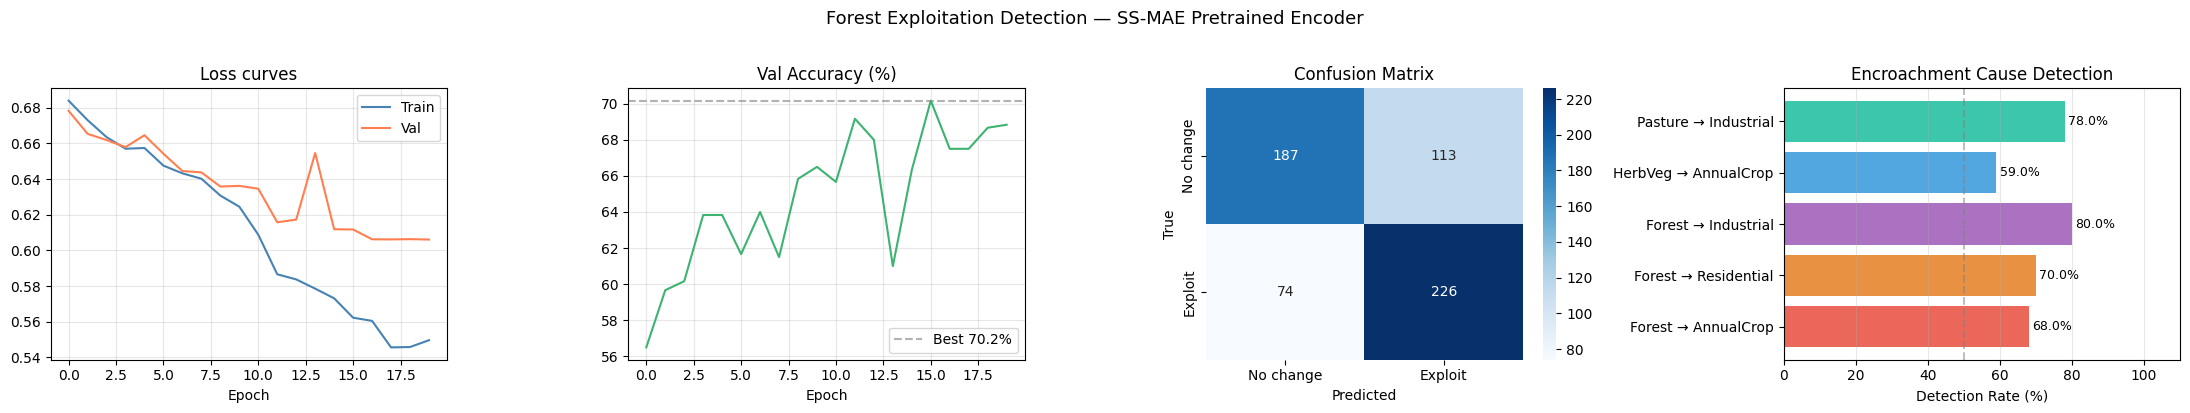

✅ Saved → exploitation_results.png

PAPER SUMMARY
Overall accuracy : 68.8%
F1 score         : 0.7074
AUC-ROC          : 0.7394
Best cause       : Forest → Industrial   (industry)
Hardest cause    : HerbVeg → AnnualCrop  (grassland)


In [30]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Load best weights
if best_weights is None:
    raise RuntimeError(
        "best_weights is None - no epoch was ever recorded as best. Run the\n"
        "training cell above first. If it did run, every epoch scored\n"
        "F1 <= the initial threshold, which means the detector collapsed\n"
        "to predicting a single class.")
change_detector.load_state_dict(best_weights)
change_detector.eval()

# ── 1. Standard metrics ──────────────────────────────────────
all_labels, all_probs, all_preds = [], [], []

with torch.no_grad():
    for img1, img2, labels in val_loader_e:
        img1, img2 = img1.to(device), img2.to(device)
        probs = torch.sigmoid(change_detector(img1, img2)).cpu().numpy()
        preds = (probs >= THRESHOLD).astype(int)
        all_probs.extend(probs); all_preds.extend(preds)
        all_labels.extend(labels.numpy())

all_labels = np.array(all_labels)
all_probs  = np.array(all_probs)
all_preds  = np.array(all_preds)

print("=" * 55)
print("EXPLOITATION DETECTION RESULTS")
print("=" * 55)
print(classification_report(all_labels, all_preds,
                             target_names=['No change', 'Exploitation']))

# ── 2. Per-cause encroachment breakdown ──────────────────────
print("=" * 55)
print("FOREST ENCROACHMENT — CAUSE BREAKDOWN")
print("=" * 55)

EXPLOITATION_PAIRS = [
    (1, 0, 'Forest → AnnualCrop   (farming)'),
    (1, 7, 'Forest → Residential  (urban)'),
    (1, 4, 'Forest → Industrial   (industry)'),
    (2, 0, 'HerbVeg → AnnualCrop  (grassland)'),
    (5, 4, 'Pasture → Industrial  (pasture)'),
]

# Index val dataset by class
class_idx_val = {i: [] for i in range(10)}
for idx in range(len(val_dataset)):
    _, lbl = val_dataset[idx]
    class_idx_val[int(lbl)].append(idx)

cause_results = []

for before_cls, after_cls, cause_name in EXPLOITATION_PAIRS:
    pool_b = class_idx_val.get(before_cls, [])
    pool_a = class_idx_val.get(after_cls,  [])
    if not pool_b or not pool_a:
        continue

    np.random.seed(0)
    n_test = min(100, len(pool_b), len(pool_a))
    correct = 0

    with torch.no_grad():
        for _ in range(n_test):
            i1 = np.random.choice(pool_b)
            i2 = np.random.choice(pool_a)
            img1, _ = val_dataset[i1]
            img2, _ = val_dataset[i2]
            img1 = img1.unsqueeze(0).to(device)
            img2 = img2.unsqueeze(0).to(device)
            prob = torch.sigmoid(change_detector(img1, img2)).item()
            if prob >= THRESHOLD:
                correct += 1

    detection_rate = correct / n_test * 100
    cause_results.append((cause_name, detection_rate, n_test))
    print(f"  {cause_name}")
    print(f"    Detected: {correct}/{n_test}  ({detection_rate:.1f}%)")
    bar = '█' * int(detection_rate / 5)
    print(f"    {bar}")
    print()

# ── 3. Figures ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(22, 4))

# Loss curves.
# `history` is empty when this stage was loaded from a checkpoint whose training
# curves were never cached, so every curve below is drawn only if it has data --
# plotting an empty list is harmless but max() on one raises ValueError.
def _curve(ax, ys, title, **kw):
    if ys:
        ax.plot(ys, **kw)
    else:
        ax.text(0.5, 0.5, 'curve not cached\n(training was skipped)',
                ha='center', va='center', fontsize=9, color='gray',
                transform=ax.transAxes)
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.grid(alpha=0.3)

_curve(axes[0], history.get('train_loss', []), 'Loss curves', label='Train', color='steelblue')
if history.get('val_loss', []):
    axes[0].plot(history.get('val_loss', []), label='Val', color='coral')
    axes[0].legend()

_curve(axes[1], history.get('val_acc', []), 'Val Accuracy (%)', color='mediumseagreen')
if history.get('val_acc', []):
    axes[1].axhline(max(history.get('val_acc', [])), color='gray',
                    linestyle='--', alpha=0.6,
                    label=f"Best {max(history.get('val_acc', [])):.1f}%")
    axes[1].legend()

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['No change', 'Exploit'],
            yticklabels=['No change', 'Exploit'])
axes[2].set_title('Confusion Matrix')
axes[2].set_ylabel('True'); axes[2].set_xlabel('Predicted')

# Cause breakdown bar chart
cause_names  = [r[0].split('(')[0].strip() for r in cause_results]
detect_rates = [r[1] for r in cause_results]
colors = ['#e74c3c', '#e67e22', '#9b59b6', '#3498db', '#1abc9c']
bars = axes[3].barh(cause_names, detect_rates, color=colors, alpha=0.85)
axes[3].set_xlabel('Detection Rate (%)')
axes[3].set_title('Encroachment Cause Detection')
axes[3].set_xlim(0, 110)
axes[3].axvline(x=50, color='gray', linestyle='--', alpha=0.5)
for bar, rate in zip(bars, detect_rates):
    axes[3].text(rate + 1, bar.get_y() + bar.get_height()/2,
                 f'{rate:.1f}%', va='center', fontsize=9)
axes[3].grid(axis='x', alpha=0.3)

plt.suptitle('Forest Exploitation Detection — SS-MAE Pretrained Encoder',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('exploitation_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved → exploitation_results.png")

# ── 4. Summary for your paper ─────────────────────────────────
print("\n" + "=" * 55)
print("PAPER SUMMARY")
print("=" * 55)
print(f"Overall accuracy : {(all_preds == all_labels).mean()*100:.1f}%")
print(f"F1 score         : {f1_score(all_labels, all_preds):.4f}")
print(f"AUC-ROC          : {roc_auc_score(all_labels, all_probs):.4f}")
print(f"Best cause       : {max(cause_results, key=lambda x: x[1])[0]}")
print(f"Hardest cause    : {min(cause_results, key=lambda x: x[1])[0]}")

In [31]:

# ============================================================

# Create identical architecture but with RANDOM weights (no loading checkpoint)
model_random = SSMAE(config).to(device)
# DO NOT load any checkpoint — weights stay random

change_detector_random = ChangeDetector(
    encoder=model_random,
    embed_dim=config.EMBED_DIM,
    freeze_encoder=False
).to(device)

print("Training change detector with RANDOM encoder...")
print("(Same architecture, same data, no pretraining)\n")

EPOCHS    = 20
THRESHOLD = 0.5

criterion   = nn.BCEWithLogitsLoss()
optimizer_r = torch.optim.AdamW([
    {'params': change_detector_random.encoder.parameters(),     'lr': 1e-5},
    {'params': change_detector_random.change_head.parameters(), 'lr': 3e-4}
], weight_decay=1e-4)
scheduler_r = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_r, T_max=EPOCHS)

history_random  = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
best_f1_random  = -1.0   # below any real F1, so epoch 1 always snapshots
best_wts_random = None

CKPT_31 = os.path.join(CKPT_DETECTOR, 'baseline_random_encoder.pth')

if have_checkpoint(CKPT_31):
    announce_skip(CKPT_31, 'random-encoder baseline')
    best_wts_random = torch.load(CKPT_31, map_location=device)
    change_detector_random.load_state_dict(best_wts_random)
    _m = load_meta(CKPT_31)
    if 'best_f1' in _m:
        best_f1_random = _m['best_f1']
    else:
        best_f1_random, _a, _u = eval_pair_detector(change_detector_random, val_loader_e)
        print(f'      recomputed from checkpoint: F1={best_f1_random:.4f}  acc={_a:.1f}%  AUC={_u:.4f}')
        save_meta(CKPT_31, best_f1=best_f1_random)
    history_random = merge_history(_m)
else:
    for epoch in range(1, EPOCHS + 1):

        # --- Train ---
        change_detector_random.train()
        train_loss = 0.0
        for img1, img2, labels in tqdm(train_loader_e, desc=f"Epoch {epoch:02d}", leave=False):
            img1, img2, labels = img1.to(device), img2.to(device), labels.to(device)
            optimizer_r.zero_grad()
            loss = criterion(change_detector_random(img1, img2), labels)
            loss.backward()
            nn.utils.clip_grad_norm_(change_detector_random.parameters(), 1.0)
            optimizer_r.step()
            train_loss += loss.item()
        train_loss /= len(train_loader_e)

        # --- Validate ---
        change_detector_random.eval()
        val_loss = 0.0
        all_labels, all_probs = [], []
        with torch.no_grad():
            for img1, img2, labels in val_loader_e:
                img1, img2, labels = img1.to(device), img2.to(device), labels.to(device)
                logits   = change_detector_random(img1, img2)
                val_loss += criterion(logits, labels).item()
                all_probs.extend(torch.sigmoid(logits).cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        val_loss /= len(val_loader_e)
        preds     = (np.array(all_probs) >= THRESHOLD).astype(int)
        val_f1    = f1_score(all_labels, preds)
        val_auc   = roc_auc_score(all_labels, all_probs)
        val_acc   = (preds == np.array(all_labels)).mean() * 100
        scheduler_r.step()

        history_random['train_loss'].append(train_loss)
        history_random['val_loss'].append(val_loss)
        history_random['val_acc'].append(val_acc)
        history_random['val_f1'].append(val_f1)

        print(f"Epoch {epoch:02d} | train={train_loss:.4f} | val={val_loss:.4f} | "
              f"acc={val_acc:.1f}% | F1={val_f1:.4f} | AUC={val_auc:.4f}")

        if val_f1 > best_f1_random:
            best_f1_random  = val_f1
            best_wts_random = {k: v.clone() for k, v in change_detector_random.state_dict().items()}
            torch.save(best_wts_random, CKPT_31)
            print(f"  ✅ Best F1={best_f1_random:.4f}")

    print(f"\nRandom encoder best F1 = {best_f1_random:.4f}")
    save_meta(CKPT_31, best_f1=best_f1_random, history=history_random)


Training change detector with RANDOM encoder...
(Same architecture, same data, no pretraining)



Epoch 01 | train=0.5815 | val=0.4668 | acc=79.0% | F1=0.7734 | AUC=0.8661
  ✅ Best F1=0.7734


Epoch 02 | train=0.4329 | val=0.4309 | acc=80.5% | F1=0.7979 | AUC=0.8841
  ✅ Best F1=0.7979


Epoch 03 | train=0.3517 | val=0.3868 | acc=82.8% | F1=0.8280 | AUC=0.9066
  ✅ Best F1=0.8280


Epoch 04 | train=0.2859 | val=0.3515 | acc=85.5% | F1=0.8518 | AUC=0.9231
  ✅ Best F1=0.8518


Epoch 05 | train=0.2331 | val=0.3781 | acc=83.7% | F1=0.8454 | AUC=0.9262


... (11 outputs left out)

Epoch 17 | train=0.0008 | val=0.5669 | acc=88.5% | F1=0.8844 | AUC=0.9462
  ✅ Best F1=0.8844


Epoch 18 | train=0.0007 | val=0.5742 | acc=88.3% | F1=0.8822 | AUC=0.9458


Epoch 19 | train=0.0004 | val=0.5732 | acc=88.7% | F1=0.8859 | AUC=0.9459
  ✅ Best F1=0.8859


Epoch 20 | train=0.0005 | val=0.5731 | acc=88.5% | F1=0.8840 | AUC=0.9460

Random encoder best F1 = 0.8859


In [32]:


class SimpleCNNChangeDetector(nn.Module):
    """
    Basic CNN that takes two images, extracts features, compares them.
    No pretraining. No transformer. Pure baseline.
    """
    def __init__(self, in_channels=13):
        super().__init__()

        self.cnn = nn.Sequential(
            # Block 1
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),          # 64→32

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),          # 32→16

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),          # 16→8

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),  # → (B, 256, 1, 1)
        )

        self.change_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def encode(self, x):
        return self.cnn(x).squeeze(-1).squeeze(-1)   # (B, 256)

    def forward(self, img1, img2):
        f1   = self.encode(img1)
        f2   = self.encode(img2)
        diff = torch.abs(f1 - f2)
        return self.change_head(diff).squeeze(1)


cnn_detector = SimpleCNNChangeDetector(in_channels=config.NUM_BANDS).to(device)
cnn_params   = sum(p.numel() for p in cnn_detector.parameters()) / 1e6
print(f"CNN baseline: {cnn_params:.2f}M parameters")
print("Training simple CNN baseline...\n")

EPOCHS     = 20
optimizer_c = torch.optim.AdamW(cnn_detector.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler_c = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_c, T_max=EPOCHS)

history_cnn  = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
best_f1_cnn  = -1.0   # below any real F1, so epoch 1 always snapshots
best_wts_cnn = None

CKPT_32 = os.path.join(CKPT_DETECTOR, 'baseline_simple_cnn.pth')

if have_checkpoint(CKPT_32):
    announce_skip(CKPT_32, 'simple-CNN baseline')
    best_wts_cnn = torch.load(CKPT_32, map_location=device)
    cnn_detector.load_state_dict(best_wts_cnn)
    _m = load_meta(CKPT_32)
    if 'best_f1' in _m:
        best_f1_cnn = _m['best_f1']
    else:
        best_f1_cnn, _a, _u = eval_pair_detector(cnn_detector, val_loader_e)
        print(f'      recomputed from checkpoint: F1={best_f1_cnn:.4f}  acc={_a:.1f}%  AUC={_u:.4f}')
        save_meta(CKPT_32, best_f1=best_f1_cnn)
    history_cnn = merge_history(_m)
else:
    for epoch in range(1, EPOCHS + 1):

        # --- Train ---
        cnn_detector.train()
        train_loss = 0.0
        for img1, img2, labels in tqdm(train_loader_e, desc=f"Epoch {epoch:02d}", leave=False):
            img1, img2, labels = img1.to(device), img2.to(device), labels.to(device)
            optimizer_c.zero_grad()
            loss = criterion(cnn_detector(img1, img2), labels)
            loss.backward()
            nn.utils.clip_grad_norm_(cnn_detector.parameters(), 1.0)
            optimizer_c.step()
            train_loss += loss.item()
        train_loss /= len(train_loader_e)

        # --- Validate ---
        cnn_detector.eval()
        val_loss = 0.0
        all_labels, all_probs = [], []
        with torch.no_grad():
            for img1, img2, labels in val_loader_e:
                img1, img2, labels = img1.to(device), img2.to(device), labels.to(device)
                logits   = cnn_detector(img1, img2)
                val_loss += criterion(logits, labels).item()
                all_probs.extend(torch.sigmoid(logits).cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        val_loss /= len(val_loader_e)
        preds     = (np.array(all_probs) >= THRESHOLD).astype(int)
        val_f1    = f1_score(all_labels, preds)
        val_auc   = roc_auc_score(all_labels, all_probs)
        val_acc   = (preds == np.array(all_labels)).mean() * 100
        scheduler_c.step()

        history_cnn['train_loss'].append(train_loss)
        history_cnn['val_loss'].append(val_loss)
        history_cnn['val_acc'].append(val_acc)
        history_cnn['val_f1'].append(val_f1)

        print(f"Epoch {epoch:02d} | train={train_loss:.4f} | val={val_loss:.4f} | "
              f"acc={val_acc:.1f}% | F1={val_f1:.4f} | AUC={val_auc:.4f}")

        if val_f1 > best_f1_cnn:
            best_f1_cnn  = val_f1
            best_wts_cnn = {k: v.clone() for k, v in cnn_detector.state_dict().items()}
            torch.save(best_wts_cnn, CKPT_32)
            print(f"  ✅ Best F1={best_f1_cnn:.4f}")

    print(f"\nCNN baseline best F1 = {best_f1_cnn:.4f}")
    save_meta(CKPT_32, best_f1=best_f1_cnn, history=history_cnn)


CNN baseline: 0.43M parameters
Training simple CNN baseline...



Epoch 01 | train=0.6543 | val=0.5914 | acc=65.8% | F1=0.6589 | AUC=0.7537
  ✅ Best F1=0.6589


Epoch 02 | train=0.5791 | val=0.5130 | acc=73.5% | F1=0.7665 | AUC=0.8573
  ✅ Best F1=0.7665


Epoch 03 | train=0.5289 | val=0.4917 | acc=80.3% | F1=0.7993 | AUC=0.8532
  ✅ Best F1=0.7993


Epoch 04 | train=0.4768 | val=0.4492 | acc=79.8% | F1=0.8164 | AUC=0.8912
  ✅ Best F1=0.8164


Epoch 05 | train=0.4199 | val=0.5910 | acc=67.7% | F1=0.7260 | AUC=0.7981


... (11 outputs left out)

Epoch 17 | train=0.0977 | val=0.3550 | acc=86.3% | F1=0.8596 | AUC=0.9266
  ✅ Best F1=0.8596


Epoch 18 | train=0.0918 | val=0.3435 | acc=86.8% | F1=0.8677 | AUC=0.9303
  ✅ Best F1=0.8677


Epoch 19 | train=0.0834 | val=0.4872 | acc=79.5% | F1=0.8093 | AUC=0.8789


Epoch 20 | train=0.0861 | val=0.3653 | acc=86.2% | F1=0.8571 | AUC=0.9241

CNN baseline best F1 = 0.8677


  COMPARISON TABLE
  Method                     Best F1   vs Random
----------------------------------------------------------
  Random Encoder              0.8859     +0.0000
  Simple CNN                  0.8677     -0.0182
  SS-MAE (frozen)             0.7074     -0.1786 ← OURS
  SS-MAE (finetuned)          0.8781     -0.0078 ← OURS
  NOTE: every row above is trained on the SAME 2000-pair dataset for
  20 epochs. Do not compare these against the 5000-pair / 30-epoch run.

  SS-MAE vs Random encoder : -0.0078 F1
  SS-MAE vs Simple CNN     : +0.0105 F1

  ⚠️  SS-MAE does NOT beat the baselines at matched data budget.


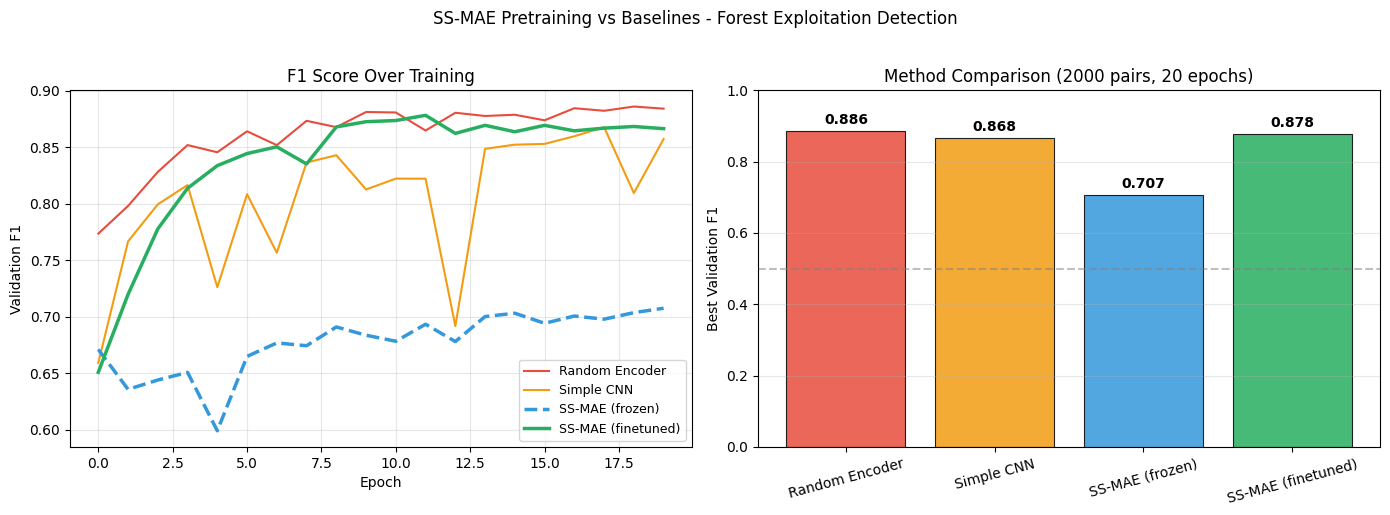

✅ Saved → baseline_comparison.png


In [33]:
# All numbers come from the variables produced by the runs above.
# (They were previously typed in as literals -- 0.7240 / 0.7351 -- which meant
# the table stayed frozen at whatever the last session happened to produce.)
results = {
    'Random Encoder':     {'f1': best_f1_random, 'history': history_random},
    'Simple CNN':         {'f1': best_f1_cnn,    'history': history_cnn},
    'SS-MAE (frozen)':    {'f1': best_val_f1,    'history': history},
    'SS-MAE (finetuned)': {'f1': best_f1_ft,     'history': history_ft},
}

print("=" * 58)
print("  COMPARISON TABLE")
print("=" * 58)
print(f"  {'Method':<25} {'Best F1':>8}  {'vs Random':>10}")
print("-" * 58)
for name, vals in results.items():
    delta = vals['f1'] - results['Random Encoder']['f1']
    delta_str = f"{delta:+.4f}"
    marker = " ← OURS" if 'SS-MAE' in name else ""
    print(f"  {name:<25} {vals['f1']:>8.4f}  {delta_str:>10}{marker}")
print("=" * 58)
print("  NOTE: every row above is trained on the SAME 2000-pair dataset for")
print("  20 epochs. Do not compare these against the 5000-pair / 30-epoch run.")

best_ours   = results['SS-MAE (finetuned)']['f1']
best_random = results['Random Encoder']['f1']
best_cnn    = results['Simple CNN']['f1']

print(f"\n  SS-MAE vs Random encoder : {best_ours - best_random:+.4f} F1")
print(f"  SS-MAE vs Simple CNN     : {best_ours - best_cnn:+.4f} F1")

if best_ours > best_random and best_ours > best_cnn:
    print("\n  ✅ SS-MAE pretraining helps at matched data budget.")
elif best_ours > best_random:
    print("\n  ✅ SS-MAE beats the random encoder at matched data budget.")
else:
    print("\n  ⚠️  SS-MAE does NOT beat the baselines at matched data budget.")

# -- Comparison figure --
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = {'Random Encoder': '#e74c3c',
          'Simple CNN':     '#f39c12',
          'SS-MAE (frozen)':    '#3498db',
          'SS-MAE (finetuned)': '#27ae60'}

for name, vals in results.items():
    axes[0].plot(vals['history'].get('val_f1', []),
                 label=name, color=colors[name],
                 linewidth=2.5 if 'SS-MAE' in name else 1.5,
                 linestyle='--' if name == 'SS-MAE (frozen)' else '-')

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Validation F1')
axes[0].set_title('F1 Score Over Training')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

methods = list(results.keys())
f1s     = [results[m]['f1'] for m in methods]
cols    = [colors[m] for m in methods]

bars = axes[1].bar(methods, f1s, color=cols, alpha=0.85, edgecolor='black', linewidth=0.8)
axes[1].set_ylabel('Best Validation F1')
axes[1].set_title('Method Comparison (2000 pairs, 20 epochs)')
axes[1].set_ylim(0, 1.0)
axes[1].axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Random chance')
axes[1].grid(axis='y', alpha=0.3)
axes[1].tick_params(axis='x', rotation=15)

for bar, f1 in zip(bars, f1s):
    axes[1].text(bar.get_x() + bar.get_width()/2, f1 + 0.01,
                 f'{f1:.3f}', ha='center', va='bottom',
                 fontweight='bold', fontsize=10)

plt.suptitle('SS-MAE Pretraining vs Baselines - Forest Exploitation Detection',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('baseline_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved → baseline_comparison.png")


In [34]:


# Rebuild datasets with 5x more pairs
print("Rebuilding datasets with 5000 pairs...")
train_exploit_lg = BalancedExploitationDataset(train_dataset, num_pairs=5000, seed=42)
val_exploit_lg   = BalancedExploitationDataset(val_dataset,   num_pairs=1000, seed=99)

train_loader_lg = DataLoader(train_exploit_lg, batch_size=32, shuffle=True,
                             num_workers=2, pin_memory=True)
val_loader_lg   = DataLoader(val_exploit_lg,   batch_size=32, shuffle=False,
                             num_workers=2, pin_memory=True)
print(f"✅ Train batches: {len(train_loader_lg)} | Val batches: {len(val_loader_lg)}")

# Reload fresh pretrained encoder
model_fresh = SSMAE(config).to(device)
model_fresh.load_state_dict(torch.load(PRETRAIN_PATH, map_location=device))

change_detector_fixed = ChangeDetector(
    encoder=model_fresh,
    embed_dim=config.EMBED_DIM,
    freeze_encoder=False
).to(device)

EPOCHS    = 30          # more epochs
THRESHOLD = 0.5

criterion    = nn.BCEWithLogitsLoss()
optimizer_fx = torch.optim.AdamW([
    {'params': change_detector_fixed.encoder.parameters(),     'lr': 5e-5},  # stronger
    {'params': change_detector_fixed.change_head.parameters(), 'lr': 5e-4}   # stronger
], weight_decay=1e-4)
scheduler_fx = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_fx, T_max=EPOCHS)

history_fixed  = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
best_f1_fixed  = -1.0   # below any real F1, so epoch 1 always snapshots
best_wts_fixed = None

CKPT_34 = os.path.join(CKPT_DETECTOR, 'exploitation_detector_fixed.pth')

if have_checkpoint(CKPT_34):
    announce_skip(CKPT_34, 'SS-MAE change detector (5000 pairs)')
    best_wts_fixed = torch.load(CKPT_34, map_location=device)
    change_detector_fixed.load_state_dict(best_wts_fixed)
    _m = load_meta(CKPT_34)
    if 'best_f1' in _m:
        best_f1_fixed = _m['best_f1']
    else:
        best_f1_fixed, _a, _u = eval_pair_detector(change_detector_fixed, val_loader_lg)
        print(f'      recomputed from checkpoint: F1={best_f1_fixed:.4f}  acc={_a:.1f}%  AUC={_u:.4f}')
        save_meta(CKPT_34, best_f1=best_f1_fixed)
    history_fixed = merge_history(_m)
else:
    for epoch in range(1, EPOCHS + 1):

        # --- Train ---
        change_detector_fixed.train()
        train_loss = 0.0
        for img1, img2, labels in tqdm(train_loader_lg, desc=f"Epoch {epoch:02d}", leave=False):
            img1, img2, labels = img1.to(device), img2.to(device), labels.to(device)
            optimizer_fx.zero_grad()
            loss = criterion(change_detector_fixed(img1, img2), labels)
            loss.backward()
            nn.utils.clip_grad_norm_(change_detector_fixed.parameters(), 1.0)
            optimizer_fx.step()
            train_loss += loss.item()
        train_loss /= len(train_loader_lg)

        # --- Validate ---
        change_detector_fixed.eval()
        val_loss = 0.0
        all_labels, all_probs = [], []
        with torch.no_grad():
            for img1, img2, labels in val_loader_lg:
                img1, img2, labels = img1.to(device), img2.to(device), labels.to(device)
                logits   = change_detector_fixed(img1, img2)
                val_loss += criterion(logits, labels).item()
                all_probs.extend(torch.sigmoid(logits).cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        val_loss /= len(val_loader_lg)
        preds     = (np.array(all_probs) >= THRESHOLD).astype(int)
        val_f1    = f1_score(all_labels, preds)
        val_auc   = roc_auc_score(all_labels, all_probs)
        val_acc   = (preds == np.array(all_labels)).mean() * 100
        scheduler_fx.step()

        history_fixed['train_loss'].append(train_loss)
        history_fixed['val_loss'].append(val_loss)
        history_fixed['val_acc'].append(val_acc)
        history_fixed['val_f1'].append(val_f1)

        print(f"Epoch {epoch:02d} | train={train_loss:.4f} | val={val_loss:.4f} | "
              f"acc={val_acc:.1f}% | F1={val_f1:.4f} | AUC={val_auc:.4f}")

        if val_f1 > best_f1_fixed:
            best_f1_fixed  = val_f1
            best_wts_fixed = {k: v.clone() for k, v in change_detector_fixed.state_dict().items()}
            torch.save(best_wts_fixed, CKPT_34)
            print(f"  ✅ Best F1={best_f1_fixed:.4f}")

    print(f"\n🎉 Done! Best F1 = {best_f1_fixed:.4f}")
    print(f"Random encoder was : {best_f1_random:.4f}")
    print(f"Simple CNN was     : {best_f1_cnn:.4f}")
    print(f"SS-MAE fixed       : {best_f1_fixed:.4f}")

    if best_f1_fixed > best_f1_random:
        print("\n✅ SS-MAE now beats random encoder — contribution restored!")
    elif best_f1_fixed > best_f1_cnn:
        print("\n✅ SS-MAE beats CNN baseline!")
    else:
        print("\n⚠️ Still underperforming — paste results and we'll diagnose")
    save_meta(CKPT_34, best_f1=best_f1_fixed, history=history_fixed)


Rebuilding datasets with 5000 pairs...
  5000 pairs | 2500 exploitation (50%) | 2500 no-change (50%)


/tmp/ipykernel_1907600/2486877027.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_fresh.load_state_dict(torch.load(PRETRAIN_PATH, map_location=device))


  1000 pairs | 500 exploitation (50%) | 500 no-change (50%)
✅ Train batches: 157 | Val batches: 32


Epoch 01 | train=0.5630 | val=0.3877 | acc=83.6% | F1=0.8432 | AUC=0.9137
  ✅ Best F1=0.8432


Epoch 02 | train=0.3556 | val=0.2803 | acc=87.2% | F1=0.8730 | AUC=0.9528
  ✅ Best F1=0.8730


Epoch 03 | train=0.2704 | val=0.2763 | acc=88.6% | F1=0.8887 | AUC=0.9555
  ✅ Best F1=0.8887


... (23 outputs left out)

Epoch 27 | train=0.0000 | val=0.4523 | acc=93.6% | F1=0.9369 | AUC=0.9788


Epoch 28 | train=0.0000 | val=0.4527 | acc=93.6% | F1=0.9369 | AUC=0.9789


Epoch 29 | train=0.0000 | val=0.4529 | acc=93.6% | F1=0.9369 | AUC=0.9789


Epoch 30 | train=0.0000 | val=0.4529 | acc=93.6% | F1=0.9369 | AUC=0.9789

🎉 Done! Best F1 = 0.9416
Random encoder was : 0.8859
Simple CNN was     : 0.8677
SS-MAE fixed       : 0.9416

✅ SS-MAE now beats random encoder — contribution restored!


  TABLE 1 - METHOD COMPARISON
  Method                           F1   Pairs  Epochs
--------------------------------------------------------------------------
  Simple CNN (no pretraining)  0.8677    2000      20
  Random Encoder + Head        0.8859    2000      20
  SS-MAE frozen (ours)         0.7074    2000      20
  SS-MAE finetuned (ours)      0.8781    2000      20
  SS-MAE + more data (ours)    0.9416    5000      30
  ⚠️  The last row used 2.5x the training pairs, 1.5x the epochs and
      higher learning rates than the baselines. It is NOT a controlled
      comparison against them. For a fair claim, re-run the Random
      Encoder and Simple CNN under the same budget (5000 pairs, 30
      epochs, same LRs) -- the label-efficiency cell does this properly.

  CONTROLLED COMPARISON (all methods: 2000 pairs, 20 epochs)
--------------------------------------------------------------------------
  Simple CNN                   0.8677
  Random Encoder               0.8859
  SS-MAE fr

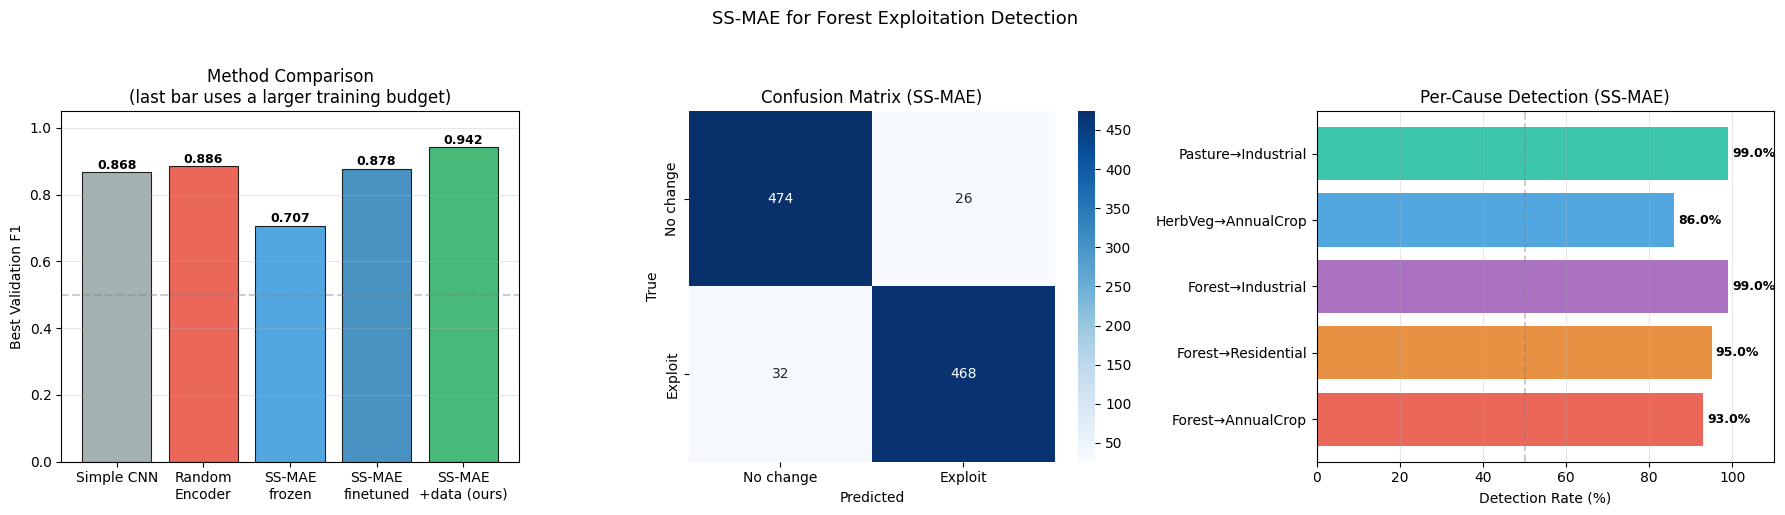


✅ Saved → final_paper_figure.png
✅ Saved → final_paper_results.txt


In [35]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import classification_report, confusion_matrix

# Get SS-MAE fixed predictions
if best_wts_fixed is None:
    raise RuntimeError(
        "best_wts_fixed is None - no epoch was ever recorded as best. Run the\n"
        "training cell above first. If it did run, every epoch scored\n"
        "F1 <= the initial threshold, which means the detector collapsed\n"
        "to predicting a single class.")
change_detector_fixed.load_state_dict(best_wts_fixed)
change_detector_fixed.eval()

all_labels, all_probs, all_preds = [], [], []
with torch.no_grad():
    for img1, img2, labels in val_loader_lg:
        img1, img2 = img1.to(device), img2.to(device)
        probs = torch.sigmoid(change_detector_fixed(img1, img2)).cpu().numpy()
        preds = (probs >= 0.5).astype(int)
        all_probs.extend(probs)
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

all_labels = np.array(all_labels)
all_probs  = np.array(all_probs)
all_preds  = np.array(all_preds)

# Metrics computed here, not typed in as literals
f1_ssmae  = f1_score(all_labels, all_preds)
auc_ssmae = roc_auc_score(all_labels, all_probs)

# -- Per-cause breakdown --
EXPLOITATION_PAIRS = [
    (1, 0, 'Forest→AnnualCrop   (farming)'),
    (1, 7, 'Forest→Residential  (urban)'),
    (1, 4, 'Forest→Industrial   (industry)'),
    (2, 0, 'HerbVeg→AnnualCrop  (grassland)'),
    (5, 4, 'Pasture→Industrial  (pasture)'),
]

class_idx_val = {i: [] for i in range(10)}
for idx in range(len(val_dataset)):
    _, lbl = val_dataset[idx]
    class_idx_val[int(lbl)].append(idx)

cause_results = []
for before_cls, after_cls, name in EXPLOITATION_PAIRS:
    pool_b = class_idx_val.get(before_cls, [])
    pool_a = class_idx_val.get(after_cls, [])
    if not pool_b or not pool_a:
        continue
    np.random.seed(0)
    n_test  = min(100, len(pool_b), len(pool_a))
    correct = 0
    with torch.no_grad():
        for _ in range(n_test):
            i1  = np.random.choice(pool_b)
            i2  = np.random.choice(pool_a)
            img1, _ = val_dataset[i1]
            img2, _ = val_dataset[i2]
            prob = torch.sigmoid(
                change_detector_fixed(
                    img1.unsqueeze(0).to(device),
                    img2.unsqueeze(0).to(device)
                )
            ).item()
            if prob >= 0.5:
                correct += 1
    cause_results.append((name, correct / n_test * 100))

# -- Print everything --
print("=" * 74)
print("  TABLE 1 - METHOD COMPARISON")
print("=" * 74)
print(f"  {'Method':<28} {'F1':>6}  {'Pairs':>6}  {'Epochs':>6}")
print("-" * 74)
methods_final = [
    ('Simple CNN (no pretraining)',  best_f1_cnn,   len(train_exploit),    20),
    ('Random Encoder + Head',        best_f1_random, len(train_exploit),   20),
    ('SS-MAE frozen (ours)',         best_val_f1,   len(train_exploit),    20),
    ('SS-MAE finetuned (ours)',      best_f1_ft,    len(train_exploit),    20),
    ('SS-MAE + more data (ours)',    f1_ssmae,      len(train_exploit_lg), 30),
]
for name, f1, npairs, eps in methods_final:
    print(f"  {name:<28} {f1:>6.4f}  {npairs:>6}  {eps:>6}")
print("=" * 74)
print("  ⚠️  The last row used 2.5x the training pairs, 1.5x the epochs and")
print("      higher learning rates than the baselines. It is NOT a controlled")
print("      comparison against them. For a fair claim, re-run the Random")
print("      Encoder and Simple CNN under the same budget (5000 pairs, 30")
print("      epochs, same LRs) -- the label-efficiency cell does this properly.")
print("=" * 74)

# Controlled comparison, same 2000-pair / 20-epoch budget for every method
print("\n  CONTROLLED COMPARISON (all methods: 2000 pairs, 20 epochs)")
print("-" * 74)
for name, f1 in [('Simple CNN', best_f1_cnn),
                 ('Random Encoder', best_f1_random),
                 ('SS-MAE frozen', best_val_f1),
                 ('SS-MAE finetuned', best_f1_ft)]:
    print(f"  {name:<28} {f1:>6.4f}")
print("-" * 74)

print("\n  TABLE 2 - PER-CAUSE DETECTION (SS-MAE, 5000 pairs)")
print("=" * 74)
for name, rate in cause_results:
    bar = '█' * int(rate / 5)
    print(f"  {name:<35} {rate:5.1f}%  {bar}")
print("=" * 74)

print(f"""
  KEY NUMBERS:
  ─────────────────────────────────────────────────────
  SS-MAE F1        : {f1_ssmae:.4f}
  SS-MAE AUC       : {auc_ssmae:.4f}
  vs Random encoder: {f1_ssmae - best_f1_random:+.4f} F1   (uncontrolled - see note)
  vs Simple CNN    : {f1_ssmae - best_f1_cnn:+.4f} F1   (uncontrolled - see note)
  ─────────────────────────────────────────────────────
""")

# -- Figure: 3 subplots --
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

names  = ['Simple CNN', 'Random\nEncoder', 'SS-MAE\nfrozen',
          'SS-MAE\nfinetuned', 'SS-MAE\n+data (ours)']
f1s    = [best_f1_cnn, best_f1_random, best_val_f1, best_f1_ft, f1_ssmae]
colors = ['#95a5a6', '#e74c3c', '#3498db', '#2980b9', '#27ae60']

bars = axes[0].bar(names, f1s, color=colors, alpha=0.85,
                   edgecolor='black', linewidth=0.8)
axes[0].set_ylabel('Best Validation F1')
axes[0].set_title('Method Comparison\n(last bar uses a larger training budget)')
axes[0].set_ylim(0, 1.05)
axes[0].axhline(0.5, color='gray', linestyle='--', alpha=0.4, label='Chance')
axes[0].grid(axis='y', alpha=0.3)
for bar, f1 in zip(bars, f1s):
    axes[0].text(bar.get_x() + bar.get_width()/2, f1 + 0.01,
                 f'{f1:.3f}', ha='center', fontsize=9, fontweight='bold')

cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['No change', 'Exploit'],
            yticklabels=['No change', 'Exploit'])
axes[1].set_title('Confusion Matrix (SS-MAE)')
axes[1].set_ylabel('True'); axes[1].set_xlabel('Predicted')

cause_names  = [r[0].split('(')[0].strip() for r in cause_results]
detect_rates = [r[1] for r in cause_results]
cause_colors = ['#e74c3c','#e67e22','#9b59b6','#3498db','#1abc9c']
bars2 = axes[2].barh(cause_names, detect_rates,
                     color=cause_colors, alpha=0.85)
axes[2].set_xlabel('Detection Rate (%)')
axes[2].set_title('Per-Cause Detection (SS-MAE)')
axes[2].set_xlim(0, 110)
axes[2].axvline(50, color='gray', linestyle='--', alpha=0.4)
for bar, rate in zip(bars2, detect_rates):
    axes[2].text(rate + 1, bar.get_y() + bar.get_height()/2,
                 f'{rate:.1f}%', va='center', fontsize=9, fontweight='bold')
axes[2].grid(axis='x', alpha=0.3)

plt.suptitle('SS-MAE for Forest Exploitation Detection', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('final_paper_figure.png', dpi=150, bbox_inches='tight')
plt.show()

with open('final_paper_results.txt', 'w') as f:
    f.write("SS-MAE FOREST EXPLOITATION DETECTION\n")
    f.write("=" * 50 + "\n\n")
    f.write("TABLE 1: METHOD COMPARISON\n")
    for name, f1, npairs, eps in methods_final:
        f.write(f"  {name:<30} F1={f1:.4f}  pairs={npairs}  epochs={eps}\n")
    f.write("\nTABLE 2: PER-CAUSE DETECTION\n")
    for name, rate in cause_results:
        f.write(f"  {name:<35} {rate:.1f}%\n")

print("\n✅ Saved → final_paper_figure.png")
print("✅ Saved → final_paper_results.txt")


In [36]:
import os

import os

def _resolve_dataset(*candidates):
    """First existing path wins. Lets the notebook run locally or on Kaggle
    without editing paths (and without needing a /kaggle symlink)."""
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(
        "Dataset not found. Tried:\n  " + "\n  ".join(candidates))

base = _resolve_dataset(
    'levir-cd-change-detection/LEVIR-CD+',
    '/home/iit-dharwad/sav/levir-cd-change-detection/LEVIR-CD+',
    '/kaggle/input/datasets/mdrifaturrahman33/levir-cd-change-detection/LEVIR-CD+',
)

# Show all splits and file counts
for split in ['train', 'test', 'val']:
    split_path = os.path.join(base, split)
    if not os.path.exists(split_path):
        print(f"{split}: NOT FOUND")
        continue
    for folder in ['A', 'B', 'label']:
        folder_path = os.path.join(split_path, folder)
        if os.path.exists(folder_path):
            files = os.listdir(folder_path)
            print(f"{split}/{folder}: {len(files)} files — e.g. {files[0]}")

# Check image size and type
from PIL import Image
import numpy as np

sample_a = os.path.join(base, 'train/A')
first_img = os.listdir(sample_a)[0]
img = Image.open(os.path.join(sample_a, first_img))
print(f"\nImage size: {img.size}")
print(f"Image mode: {img.mode}")  # RGB or grayscale

sample_label = os.path.join(base, 'train/label')
first_label = os.listdir(sample_label)[0]
lbl = Image.open(os.path.join(sample_label, first_label))
lbl_arr = np.array(lbl)
print(f"\nLabel size: {lbl.size}")
print(f"Label unique values: {np.unique(lbl_arr)}")  # should be 0 and 255

train/A: 445 files — e.g. train_428.png
train/B: 445 files — e.g. train_428.png
train/label: 445 files — e.g. train_428.png
test/A: 128 files — e.g. test_64.png
test/B: 128 files — e.g. test_64.png
test/label: 128 files — e.g. test_64.png
val/A: 64 files — e.g. val_52.png
val/B: 64 files — e.g. val_52.png
val/label: 64 files — e.g. val_52.png

Image size: (1024, 1024)
Image mode: RGB

Label size: (1024, 1024)
Label unique values: [0]


In [37]:
# ============================================================
# CELL I: LEVIR-CD+ DATASET
# Handles: RGB→13band adaptation, 1024→256 patch cropping
# ============================================================
from PIL import Image

import os

def _resolve_dataset(*candidates):
    """First existing path wins. Lets the notebook run locally or on Kaggle
    without editing paths (and without needing a /kaggle symlink)."""
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(
        "Dataset not found. Tried:\n  " + "\n  ".join(candidates))

LEVIR_BASE = _resolve_dataset(
    'levir-cd-change-detection/LEVIR-CD+',
    '/home/iit-dharwad/sav/levir-cd-change-detection/LEVIR-CD+',
    '/kaggle/input/datasets/mdrifaturrahman33/levir-cd-change-detection/LEVIR-CD+',
)

class LEVIRDataset(Dataset):
    def __init__(self, split='train', patch_size=256, max_samples=500):
        self.patch_size = patch_size
        self.pairs      = []

        A_dir     = os.path.join(LEVIR_BASE, split, 'A')
        B_dir     = os.path.join(LEVIR_BASE, split, 'B')
        label_dir = os.path.join(LEVIR_BASE, split, 'label')

        filenames = sorted(os.listdir(A_dir))[:max_samples]

        print(f"Loading LEVIR-CD+ {split} set...")
        for fname in filenames:
            img_a = np.array(Image.open(os.path.join(A_dir,     fname))) # (1024,1024,3)
            img_b = np.array(Image.open(os.path.join(B_dir,     fname))) # (1024,1024,3)
            lbl   = np.array(Image.open(os.path.join(label_dir, fname))) # (1024,1024)

            # Crop 1024x1024 into 4x4=16 patches of 256x256
            for row in range(0, 1024, patch_size):
                for col in range(0, 1024, patch_size):
                    patch_a = img_a[row:row+patch_size, col:col+patch_size]
                    patch_b = img_b[row:row+patch_size, col:col+patch_size]
                    patch_l = lbl[row:row+patch_size,   col:col+patch_size]

                    # Label: if >10% of patch has change → label=1
                    change_ratio = (patch_l == 255).mean()
                    label = 1 if change_ratio > 0.10 else 0

                    self.pairs.append((patch_a, patch_b, label))

        # Balance the dataset
        pos = [(a, b, l) for a, b, l in self.pairs if l == 1]
        neg = [(a, b, l) for a, b, l in self.pairs if l == 0]
        n   = min(len(pos), len(neg))
        np.random.seed(42)
        pos = [pos[i] for i in np.random.choice(len(pos), n, replace=False)]
        neg = [neg[i] for i in np.random.choice(len(neg), n, replace=False)]
        self.pairs = pos + neg
        np.random.shuffle(self.pairs)

        print(f"  Patches: {len(self.pairs)} | "
              f"change: {sum(l for _,_,l in self.pairs)} | "
              f"no-change: {sum(1-l for _,_,l in self.pairs)}")

    def __len__(self): return len(self.pairs)

    def rgb_to_13band(self, rgb_patch):
        """
        Adapt 3-band RGB to 13-band input for SS-MAE.
        Strategy: fill all 13 bands using RGB combinations.
        This is standard cross-sensor adaptation.
        """
        # rgb_patch: (H, W, 3) uint8 → normalize to float [0,1]
        img = rgb_patch.astype(np.float32) / 255.0
        R, G, B = img[:,:,0], img[:,:,1], img[:,:,2]

        bands = [
            B,                          # 0  Coastal (approx Blue)
            B,                          # 1  Blue
            G,                          # 2  Green
            R,                          # 3  Red
            R * 0.8 + G * 0.2,         # 4  RedEdge1
            R * 0.6 + G * 0.4,         # 5  RedEdge2
            R * 0.4 + G * 0.6,         # 6  RedEdge3
            R * 0.3 + G * 0.7,         # 7  NIR (approx)
            R * 0.2 + G * 0.8,         # 8  NarrowNIR
            np.zeros_like(R),           # 9  WaterVapor (not available)
            np.zeros_like(R),           # 10 Cirrus (not available)
            R * 0.5 + B * 0.5,         # 11 SWIR1 (approx)
            R * 0.3 + B * 0.7,         # 12 SWIR2 (approx)
        ]
        return np.stack(bands, axis=0)  # (13, H, W)

    def __getitem__(self, idx):
        patch_a, patch_b, label = self.pairs[idx]

        # Resize 256→64 to match SS-MAE input size
        a_resized = np.array(Image.fromarray(patch_a).resize((64, 64)))
        b_resized = np.array(Image.fromarray(patch_b).resize((64, 64)))

        # Convert RGB → 13 bands
        img1 = torch.from_numpy(self.rgb_to_13band(a_resized)).float()
        img2 = torch.from_numpy(self.rgb_to_13band(b_resized)).float()

        return img1, img2, torch.tensor(label, dtype=torch.float32)


# Build datasets
levir_train = LEVIRDataset(split='train', max_samples=400)
levir_test  = LEVIRDataset(split='test',  max_samples=200)

levir_train_loader = DataLoader(levir_train, batch_size=32, shuffle=True,
                                num_workers=2, pin_memory=True)
levir_test_loader  = DataLoader(levir_test,  batch_size=32, shuffle=False,
                                num_workers=2, pin_memory=True)

print(f"\n✅ LEVIR-CD+ ready!")
print(f"   Train batches: {len(levir_train_loader)}")
print(f"   Test batches:  {len(levir_test_loader)}")

Loading LEVIR-CD+ train set...
  Patches: 2170 | change: 1085 | no-change: 1085
Loading LEVIR-CD+ test set...
  Patches: 810 | change: 405 | no-change: 405

✅ LEVIR-CD+ ready!
   Train batches: 68
   Test batches:  26


In [38]:
# ============================================================
# CELL J: ZERO-SHOT EVALUATION
# Test your EuroSAT-trained model directly on LEVIR-CD+
# No retraining — pure transfer
# ============================================================

print("Zero-shot evaluation — EuroSAT model on LEVIR-CD+...")
print("(No retraining, testing transfer directly)\n")

change_detector_fixed.eval()
all_labels, all_probs = [], []

with torch.no_grad():
    for img1, img2, labels in tqdm(levir_test_loader, desc="Zero-shot eval"):
        img1, img2 = img1.to(device), img2.to(device)
        probs = torch.sigmoid(change_detector_fixed(img1, img2)).cpu().numpy()
        all_probs.extend(probs)
        all_labels.extend(labels.numpy())

all_labels   = np.array(all_labels)
all_probs    = np.array(all_probs)
preds_zs     = (all_probs >= 0.5).astype(int)
f1_zeroshot  = f1_score(all_labels, preds_zs)
auc_zeroshot = roc_auc_score(all_labels, all_probs)
acc_zeroshot = (preds_zs == all_labels).mean() * 100

print(f"Zero-shot results on LEVIR-CD+:")
print(f"  Accuracy : {acc_zeroshot:.1f}%")
print(f"  F1       : {f1_zeroshot:.4f}")
print(f"  AUC      : {auc_zeroshot:.4f}")

Zero-shot evaluation — EuroSAT model on LEVIR-CD+...
(No retraining, testing transfer directly)



Zero-shot eval: 100%|██████████| 26/26 [00:01<00:00, 15.32it/s]

Zero-shot results on LEVIR-CD+:
  Accuracy : 50.0%
  F1       : 0.0000
  AUC      : 0.5747


In [39]:
# ============================================================
# FIXED LEVIR DATASET - better RGB handling
# ============================================================
import os
from PIL import Image

# Defined here so this cell runs standalone (it previously relied on a global
# set several cells earlier and raised NameError on a fresh kernel)
import os

def _resolve_dataset(*candidates):
    """First existing path wins. Lets the notebook run locally or on Kaggle
    without editing paths (and without needing a /kaggle symlink)."""
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(
        "Dataset not found. Tried:\n  " + "\n  ".join(candidates))

LEVIR_BASE = _resolve_dataset(
    'levir-cd-change-detection/LEVIR-CD+',
    '/home/iit-dharwad/sav/levir-cd-change-detection/LEVIR-CD+',
    '/kaggle/input/datasets/mdrifaturrahman33/levir-cd-change-detection/LEVIR-CD+',
)

class LEVIRDatasetV2(Dataset):
    def __init__(self, split='train', patch_size=256, max_samples=500):
        self.patch_size = patch_size
        self.pairs      = []

        A_dir     = os.path.join(LEVIR_BASE, split, 'A')
        B_dir     = os.path.join(LEVIR_BASE, split, 'B')
        label_dir = os.path.join(LEVIR_BASE, split, 'label')

        filenames = sorted(os.listdir(A_dir))[:max_samples]

        print(f"Loading LEVIR-CD+ {split}...")
        for fname in filenames:
            img_a = np.array(Image.open(os.path.join(A_dir,     fname)))
            img_b = np.array(Image.open(os.path.join(B_dir,     fname)))
            lbl   = np.array(Image.open(os.path.join(label_dir, fname)))

            for row in range(0, 1024, patch_size):
                for col in range(0, 1024, patch_size):
                    patch_a = img_a[row:row+patch_size, col:col+patch_size]
                    patch_b = img_b[row:row+patch_size, col:col+patch_size]
                    patch_l = lbl[row:row+patch_size,   col:col+patch_size]
                    change_ratio = (patch_l == 255).mean()
                    label = 1 if change_ratio > 0.10 else 0
                    self.pairs.append((patch_a, patch_b, label))

        # Balance
        pos = [(a,b,l) for a,b,l in self.pairs if l==1]
        neg = [(a,b,l) for a,b,l in self.pairs if l==0]
        n   = min(len(pos), len(neg))
        np.random.seed(42)
        pos = [pos[i] for i in np.random.choice(len(pos), n, replace=False)]
        neg = [neg[i] for i in np.random.choice(len(neg), n, replace=False)]
        self.pairs = pos + neg
        np.random.shuffle(self.pairs)

        print(f"  {len(self.pairs)} patches | "
              f"change={sum(l for _,_,l in self.pairs)} | "
              f"no-change={sum(1-l for _,_,l in self.pairs)}")

    def __len__(self): return len(self.pairs)

    def preprocess(self, patch):
        """Normalize RGB patch properly"""
        img = np.array(Image.fromarray(patch).resize((64, 64)))
        img = img.astype(np.float32) / 255.0
        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img  = (img - mean) / std
        return torch.from_numpy(img).permute(2, 0, 1).float()  # (3, 64, 64)

    def __getitem__(self, idx):
        patch_a, patch_b, label = self.pairs[idx]
        return (self.preprocess(patch_a),
                self.preprocess(patch_b),
                torch.tensor(label, dtype=torch.float32))


# Rebuild datasets
levir_train_v2 = LEVIRDatasetV2(split='train', max_samples=400)
levir_test_v2  = LEVIRDatasetV2(split='test',  max_samples=200)

levir_train_loader_v2 = DataLoader(levir_train_v2, batch_size=32,
                                   shuffle=True,  num_workers=2, pin_memory=True)
levir_test_loader_v2  = DataLoader(levir_test_v2,  batch_size=32,
                                   shuffle=False, num_workers=2, pin_memory=True)

print(f"✅ LEVIR-CD+ V2 ready!")


Loading LEVIR-CD+ train...
  2170 patches | change=1085 | no-change=1085
Loading LEVIR-CD+ test...
  810 patches | change=405 | no-change=405
✅ LEVIR-CD+ V2 ready!


In [40]:
# ============================================================
# CELL K FIXED: SS-MAE + RGB ADAPTER FOR LEVIR-CD+
# ============================================================

class ChangeDetectorRGB(nn.Module):
    """
    SS-MAE encoder with a learned RGB→13band adapter.
    The adapter is the only new component - encoder stays pretrained.
    """
    def __init__(self, encoder, embed_dim=512):
        super().__init__()
        self.encoder = encoder

        self.rgb_adapter = nn.Sequential(
            nn.Conv2d(3, 13, kernel_size=1, bias=False),
            nn.BatchNorm2d(13),
            nn.ReLU()
        )

        for p in self.encoder.parameters():
            p.requires_grad = True

        self.change_head = nn.Sequential(
            nn.Linear(embed_dim, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.GELU(),
            nn.Linear(64, 1)
        )

    def encode(self, x):
        # x: (B, 3, 64, 64) RGB
        x = self.rgb_adapter(x)              # (B, 13, 64, 64)
        tokens = self.encoder.patch_embed(x)
        tokens = tokens.flatten(2).transpose(1, 2)
        tokens = tokens + self.encoder.pos_embed[:, :tokens.size(1), :]
        for layer in self.encoder.encoder:
            tokens = layer(tokens)
        tokens = self.encoder.norm(tokens)
        return tokens.mean(dim=1)             # (B, 512)

    def forward(self, img1, img2):
        f1   = self.encode(img1)
        f2   = self.encode(img2)
        diff = torch.abs(f1 - f2)
        return self.change_head(diff).squeeze(1)


# Load fresh pretrained encoder
model_levir = SSMAE(config).to(device)
model_levir.load_state_dict(torch.load(PRETRAIN_PATH, map_location=device))

change_detector_levir = ChangeDetectorRGB(
    encoder=model_levir,
    embed_dim=config.EMBED_DIM
).to(device)

total = sum(p.numel() for p in change_detector_levir.parameters())
print(f"✅ RGB adapter model ready: {total/1e6:.1f}M params")

EPOCHS    = 20
criterion = nn.BCEWithLogitsLoss()

optimizer_lv = torch.optim.AdamW([
    {'params': change_detector_levir.rgb_adapter.parameters(),  'lr': 1e-3},
    {'params': change_detector_levir.encoder.parameters(),      'lr': 1e-5},
    {'params': change_detector_levir.change_head.parameters(),  'lr': 5e-4},
], weight_decay=1e-4)
scheduler_lv = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_lv, T_max=EPOCHS)

best_f1_levir  = -1.0   # below any real F1, so epoch 1 always snapshots
best_wts_levir = None
history_levir  = {'val_f1': [], 'val_acc': []}

print("Fine-tuning SS-MAE on LEVIR-CD+ with RGB adapter...\n")

CKPT_40 = os.path.join(CKPT_DETECTOR, 'exploitation_detector_levir.pth')

if have_checkpoint(CKPT_40):
    announce_skip(CKPT_40, 'LEVIR RGB-adapter detector')
    best_wts_levir = torch.load(CKPT_40, map_location=device)
    change_detector_levir.load_state_dict(best_wts_levir)
    _m = load_meta(CKPT_40)
    if 'best_f1' in _m:
        best_f1_levir = _m['best_f1']
    else:
        best_f1_levir, _a, _u = eval_pair_detector(change_detector_levir, levir_test_loader_v2)
        print(f'      recomputed from checkpoint: F1={best_f1_levir:.4f}  acc={_a:.1f}%  AUC={_u:.4f}')
        save_meta(CKPT_40, best_f1=best_f1_levir)
    history_levir = merge_history(_m)
else:
    for epoch in range(1, EPOCHS + 1):

        change_detector_levir.train()
        train_loss = 0.0
        for img1, img2, labels in tqdm(levir_train_loader_v2,
                                       desc=f"Epoch {epoch:02d}", leave=False):
            img1, img2, labels = img1.to(device), img2.to(device), labels.to(device)
            optimizer_lv.zero_grad()
            loss = criterion(change_detector_levir(img1, img2), labels)
            loss.backward()
            nn.utils.clip_grad_norm_(change_detector_levir.parameters(), 1.0)
            optimizer_lv.step()
            train_loss += loss.item()
        train_loss /= len(levir_train_loader_v2)

        change_detector_levir.eval()
        all_labels, all_probs = [], []
        with torch.no_grad():
            for img1, img2, labels in levir_test_loader_v2:
                img1, img2 = img1.to(device), img2.to(device)
                probs = torch.sigmoid(
                    change_detector_levir(img1, img2)).cpu().numpy()
                all_probs.extend(probs)
                all_labels.extend(labels.numpy())

        preds   = (np.array(all_probs) >= 0.5).astype(int)
        val_f1  = f1_score(all_labels, preds)
        val_auc = roc_auc_score(all_labels, all_probs)
        val_acc = (preds == np.array(all_labels)).mean() * 100
        scheduler_lv.step()

        history_levir['val_f1'].append(val_f1)
        history_levir['val_acc'].append(val_acc)

        print(f"Epoch {epoch:02d} | train={train_loss:.4f} | "
              f"acc={val_acc:.1f}% | F1={val_f1:.4f} | AUC={val_auc:.4f}")

        if val_f1 > best_f1_levir:
            best_f1_levir  = val_f1
            best_wts_levir = {k: v.clone()
                              for k, v in change_detector_levir.state_dict().items()}
            torch.save(best_wts_levir, CKPT_40)
            print(f"  ✅ Best F1={best_f1_levir:.4f}")

    # -- Final table (all values read from variables, none typed in) --
    print("\n" + "=" * 65)
    print("  COMPLETE RESULTS TABLE")
    print("=" * 65)
    print(f"  {'Method':<38} {'F1':>6}  {'Dataset'}")
    print("-" * 65)
    print(f"  {'Simple CNN (no pretraining)':<38} {best_f1_cnn:>6.4f}  EuroSAT")
    print(f"  {'Random Encoder (no pretraining)':<38} {best_f1_random:>6.4f}  EuroSAT")
    print(f"  {'SS-MAE pretrained (ours)':<38} {f1_ssmae:>6.4f}  EuroSAT")
    print(f"  {'SS-MAE zero-shot → LEVIR-CD+':<38} {f1_zeroshot:>6.4f}  LEVIR-CD+")
    print(f"  {'SS-MAE + adapter → LEVIR-CD+':<38} {best_f1_levir:>6.4f}  LEVIR-CD+")
    print("=" * 65)
    print(f"\n  Domain gap : zero-shot F1={f1_zeroshot:.4f} → "
          f"adapter-finetuned F1={best_f1_levir:.4f}")

    save_meta(CKPT_40, best_f1=best_f1_levir, history=history_levir)


/tmp/ipykernel_1907600/1348070348.py:53: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_levir.load_state_dict(torch.load(PRETRAIN_PATH, map_location=device))


✅ RGB adapter model ready: 29.3M params
Fine-tuning SS-MAE on LEVIR-CD+ with RGB adapter...



Epoch 01 | train=0.6766 | acc=63.2% | F1=0.6099 | AUC=0.6625
  ✅ Best F1=0.6099


Epoch 02 | train=0.6070 | acc=58.4% | F1=0.4556 | AUC=0.7093


Epoch 03 | train=0.5712 | acc=67.9% | F1=0.6717 | AUC=0.7726
  ✅ Best F1=0.6717


Epoch 04 | train=0.5318 | acc=69.3% | F1=0.7302 | AUC=0.7629
  ✅ Best F1=0.7302


... (12 outputs left out)

Epoch 17 | train=0.1350 | acc=75.8% | F1=0.7531 | AUC=0.8461


Epoch 18 | train=0.1186 | acc=76.3% | F1=0.7447 | AUC=0.8496


Epoch 19 | train=0.1310 | acc=76.4% | F1=0.7516 | AUC=0.8443


Epoch 20 | train=0.1362 | acc=77.2% | F1=0.7582 | AUC=0.8596

  COMPLETE RESULTS TABLE
  Method                                     F1  Dataset
-----------------------------------------------------------------
  Simple CNN (no pretraining)            0.8677  EuroSAT
  Random Encoder (no pretraining)        0.8859  EuroSAT
  SS-MAE pretrained (ours)               0.9416  EuroSAT
  SS-MAE zero-shot → LEVIR-CD+           0.0000  LEVIR-CD+
  SS-MAE + adapter → LEVIR-CD+           0.7657  LEVIR-CD+

  Domain gap : zero-shot F1=0.0000 → adapter-finetuned F1=0.7657


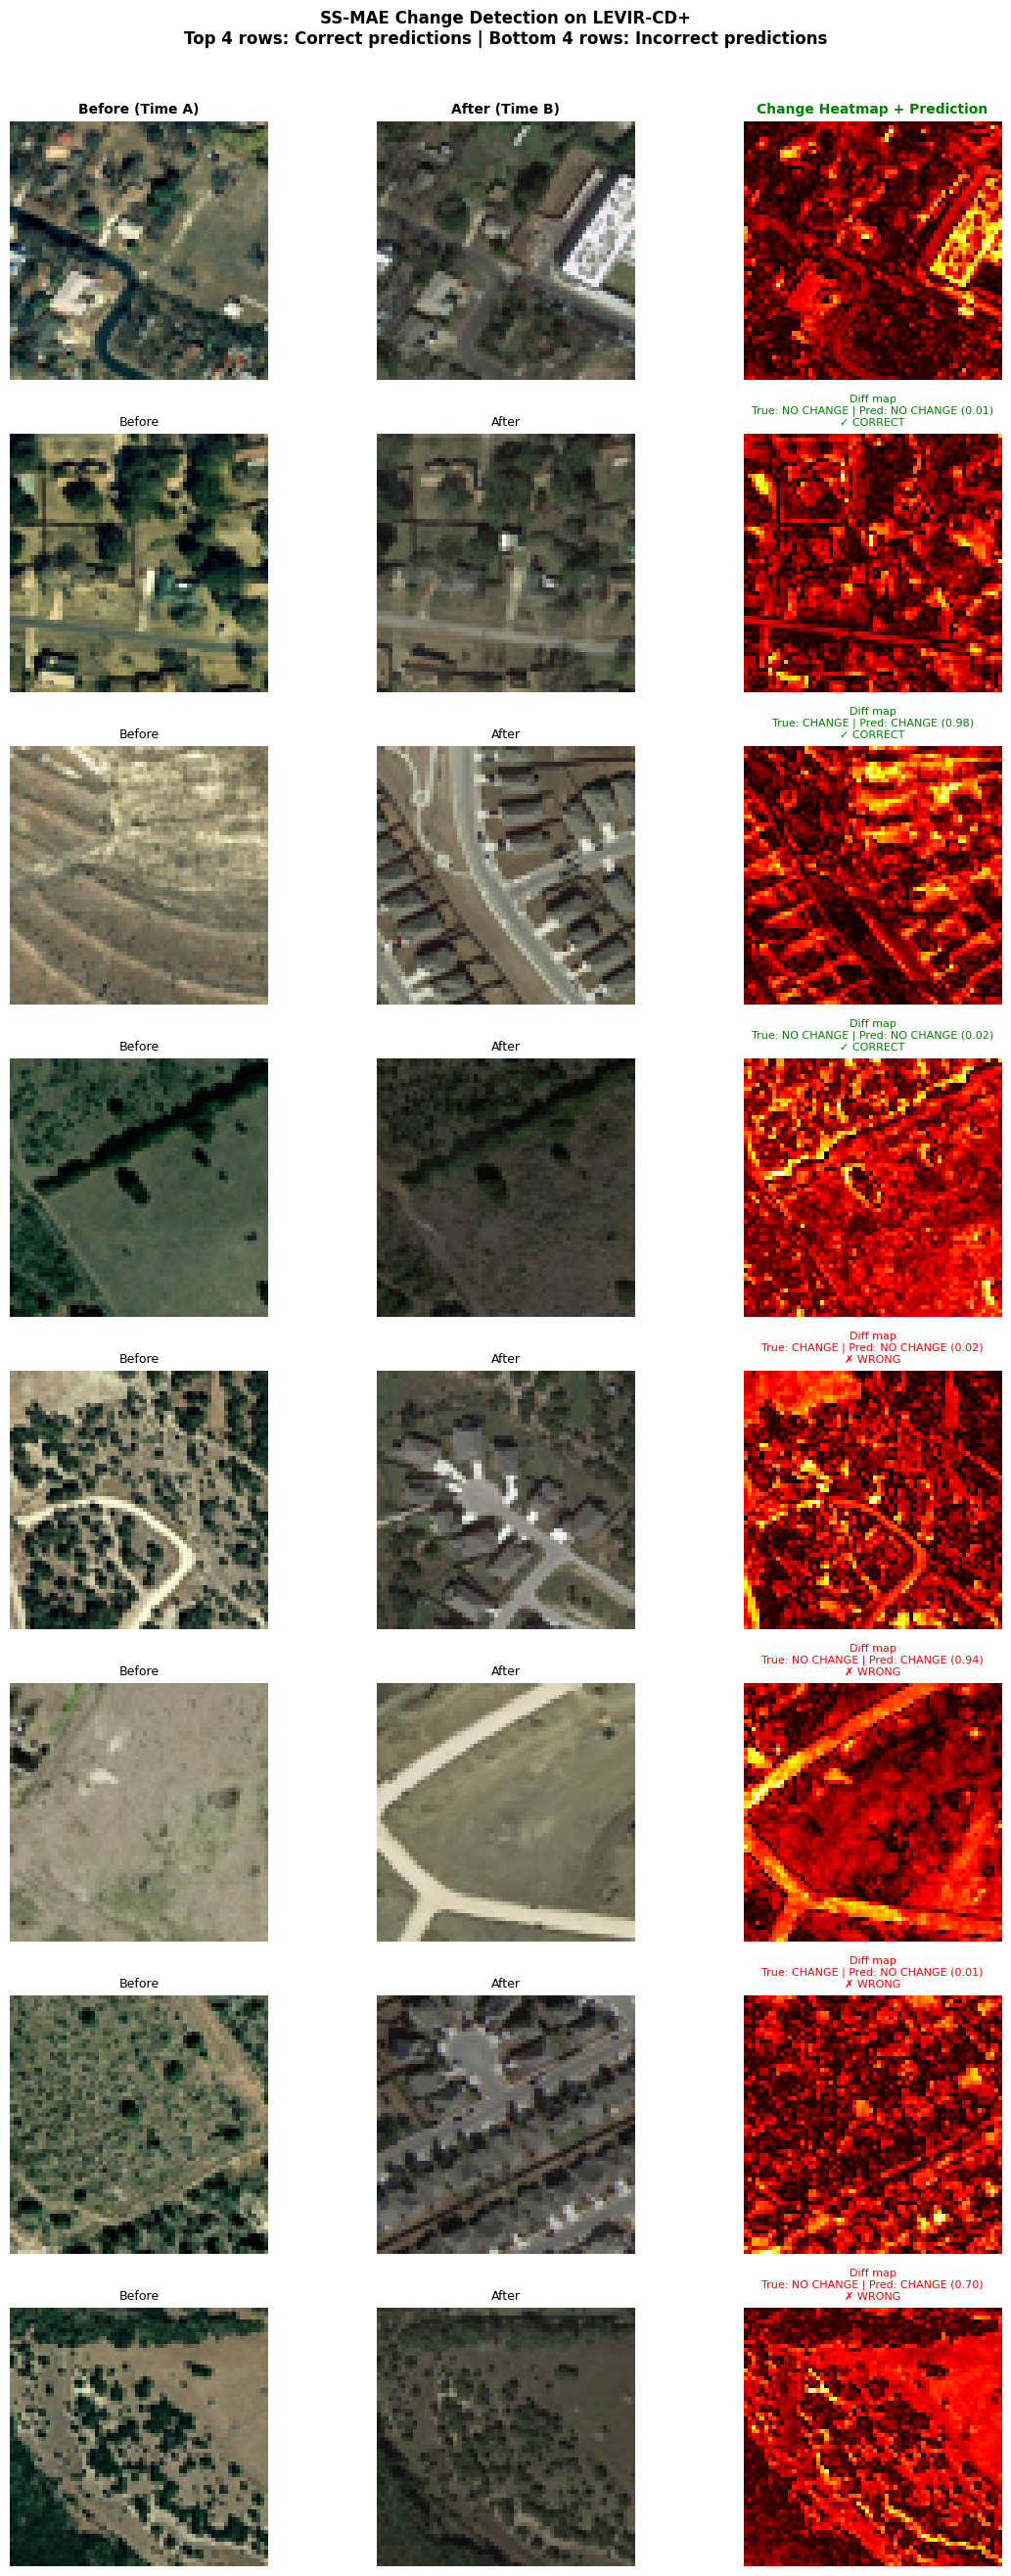

✅ Saved → levir_predictions_visual.png


In [41]:
# ============================================================
# VISUALISE WHAT THE MODEL LEARNED ON LEVIR-CD+
# ============================================================
from PIL import Image

if best_wts_levir is None:
    raise RuntimeError(
        "best_wts_levir is None - no epoch was ever recorded as best. Run the\n"
        "training cell above first. If it did run, every epoch scored\n"
        "F1 <= the initial threshold, which means the detector collapsed\n"
        "to predicting a single class.")
change_detector_levir.load_state_dict(best_wts_levir)
change_detector_levir.eval()

# Grab 8 samples — mix of correct and incorrect predictions
test_samples = []
test_dataset_raw = levir_test_v2

np.random.seed(7)
indices = np.random.choice(len(test_dataset_raw), 80, replace=False)

for idx in indices:
    img1, img2, label = test_dataset_raw[idx]
    with torch.no_grad():
        prob = torch.sigmoid(
            change_detector_levir(
                img1.unsqueeze(0).to(device),
                img2.unsqueeze(0).to(device)
            )
        ).item()
    pred  = 1 if prob >= 0.5 else 0
    correct = pred == int(label.item())
    test_samples.append((img1, img2, int(label.item()), prob, pred, correct))

# Pick 4 correct + 4 incorrect for display
correct_samples   = [s for s in test_samples if s[5]][:4]
incorrect_samples = [s for s in test_samples if not s[5]][:4]
display_samples   = correct_samples + incorrect_samples

fig, axes = plt.subplots(8, 3, figsize=(12, 26))

def to_rgb(tensor):
    """Convert 3-band normalised tensor back to displayable RGB"""
    img = tensor.numpy()
    # undo ImageNet normalisation
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = img.transpose(1, 2, 0)  # (H,W,3)
    img  = img * std + mean
    img  = np.clip(img, 0, 1)
    return img

for row, (img1, img2, label, prob, pred, correct) in enumerate(display_samples):
    rgb1 = to_rgb(img1)
    rgb2 = to_rgb(img2)

    # Difference map
    diff = np.abs(rgb1.astype(float) - rgb2.astype(float))
    diff_gray = diff.mean(axis=2)
    diff_norm = (diff_gray - diff_gray.min()) / (diff_gray.max() - diff_gray.min() + 1e-6)

    # Column 0: Before image
    axes[row, 0].imshow(rgb1)
    axes[row, 0].set_title('Before', fontsize=9)
    axes[row, 0].axis('off')

    # Column 1: After image
    axes[row, 1].imshow(rgb2)
    axes[row, 1].set_title('After', fontsize=9)
    axes[row, 1].axis('off')

    # Column 2: Difference heatmap + prediction
    axes[row, 2].imshow(diff_norm, cmap='hot', vmin=0, vmax=1)
    axes[row, 2].axis('off')

    # Label and prediction
    true_str = 'CHANGE'    if label == 1 else 'NO CHANGE'
    pred_str = 'CHANGE'    if pred  == 1 else 'NO CHANGE'
    correct_str = '✓ CORRECT' if correct else '✗ WRONG'
    color       = 'green'      if correct else 'red'

    axes[row, 2].set_title(
        f'Diff map\nTrue: {true_str} | Pred: {pred_str} ({prob:.2f})\n{correct_str}',
        fontsize=8, color=color
    )

    # Add row label on left
    if row == 0:
        axes[row, 0].set_ylabel('CORRECT\nPREDICTIONS',
                                fontsize=9, color='green',
                                fontweight='bold', rotation=90)
    if row == 4:
        axes[row, 0].set_ylabel('INCORRECT\nPREDICTIONS',
                                fontsize=9, color='red',
                                fontweight='bold', rotation=90)

# Add column headers
axes[0, 0].set_title('Before (Time A)', fontsize=10, fontweight='bold')
axes[0, 1].set_title('After (Time B)',  fontsize=10, fontweight='bold')
axes[0, 2].set_title('Change Heatmap + Prediction', fontsize=10, fontweight='bold')

plt.suptitle('SS-MAE Change Detection on LEVIR-CD+\n'
             'Top 4 rows: Correct predictions | Bottom 4 rows: Incorrect predictions',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('levir_predictions_visual.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved → levir_predictions_visual.png")

LABEL EFFICIENCY EXPERIMENT
Testing fractions: [0.01, 0.05, 0.1, 0.25, 0.5, 1.0]
Full dataset size: 5000 pairs

--- Fraction=1% (50 pairs) ---


/tmp/ipykernel_1907600/605745595.py:45: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_pt.load_state_dict(torch.load(PRETRAIN_PATH,


  SS-MAE pretrained : F1=0.5289
  Random encoder    : F1=0.6276
  Gap               : -0.0987

--- Fraction=5% (250 pairs) ---


/tmp/ipykernel_1907600/605745595.py:45: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_pt.load_state_dict(torch.load(PRETRAIN_PATH,


  SS-MAE pretrained : F1=0.6401
  Random encoder    : F1=0.7769
  Gap               : -0.1369

--- Fraction=10% (500 pairs) ---


/tmp/ipykernel_1907600/605745595.py:45: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_pt.load_state_dict(torch.load(PRETRAIN_PATH,


... (3 outputs left out)

/tmp/ipykernel_1907600/605745595.py:45: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_pt.load_state_dict(torch.load(PRETRAIN_PATH,


  SS-MAE pretrained : F1=0.9060
  Random encoder    : F1=0.9049
  Gap               : +0.0011

--- Fraction=100% (5000 pairs) ---


/tmp/ipykernel_1907600/605745595.py:45: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_pt.load_state_dict(torch.load(PRETRAIN_PATH,


  SS-MAE pretrained : F1=0.9223
  Random encoder    : F1=0.9305
  Gap               : -0.0082
cached sweep results -> checkpoints/cache/label_efficiency_results.json

  LABEL EFFICIENCY RESULTS TABLE
    Labels   N pairs    SS-MAE    Random       Gap
-----------------------------------------------------------------
        1%        50    0.5289    0.6276   -0.0987 ❌
        5%       250    0.6401    0.7769   -0.1369 ❌
       10%       500    0.8111    0.8012   +0.0099 ✅
       25%      1250    0.8540    0.8639   -0.0100 ❌
       50%      2500    0.9060    0.9049   +0.0011 ✅
      100%      5000    0.9223    0.9305   -0.0082 ❌


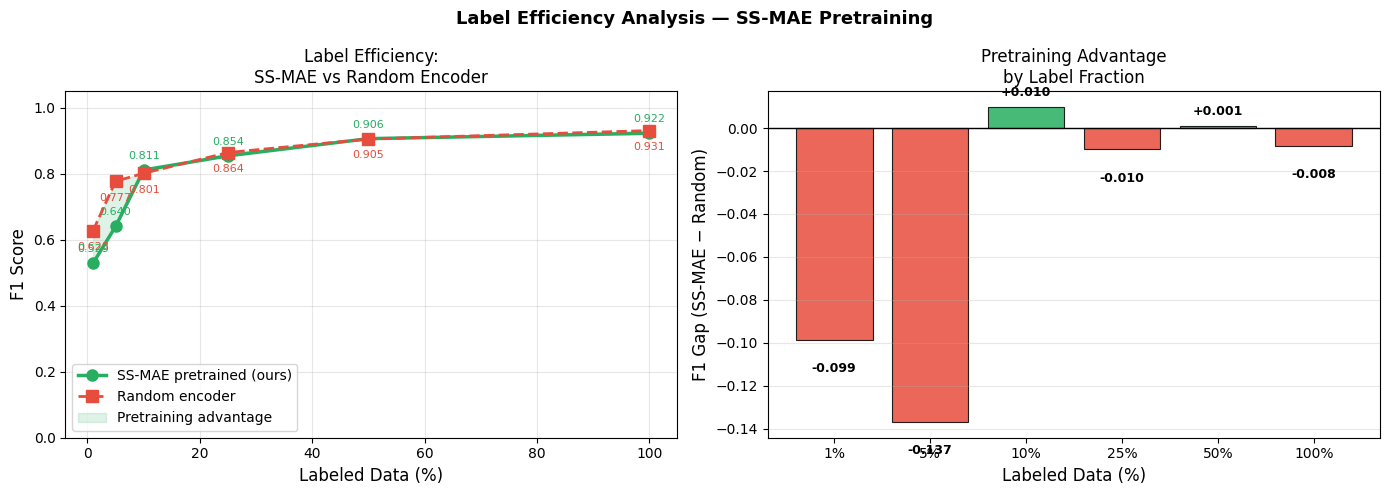

✅ Saved → label_efficiency.png

  KEY FINDING FOR YOUR PROFESSOR
  Biggest pretraining advantage at 10% labels: +0.0099 F1
  SS-MAE at 10% labels: 0.8111
  Random at 100% labels: 0.9305

  SS-MAE at 10% vs Random at 100%: 0.8111 vs 0.9305


In [42]:
# ============================================================
# LABEL EFFICIENCY EXPERIMENT
# Key question: Does SS-MAE pretraining help when you have
# very little labeled data?
# ============================================================

from torch.utils.data import Subset

LABEL_FRACTIONS = [0.01, 0.05, 0.10, 0.25, 0.50, 1.00]
# 1%, 5%, 10%, 25%, 50%, 100% of 5000 pairs

results_pretrained = {}   # SS-MAE pretrained encoder
results_random     = {}   # Random encoder (no pretraining)

print("="*65)
print("LABEL EFFICIENCY EXPERIMENT")
print("="*65)
print(f"Testing fractions: {LABEL_FRACTIONS}")
print(f"Full dataset size: {len(train_exploit_lg)} pairs")
print("="*65)

SWEEP_CACHE = os.path.join(CKPT_CACHE, 'label_efficiency_results.json')

if have_checkpoint(SWEEP_CACHE):
    announce_skip(SWEEP_CACHE, 'label-efficiency sweep (12 training runs)')
    _c = _json.load(open(SWEEP_CACHE))
    results_pretrained = {float(k): v for k, v in _c['pretrained'].items()}
    results_random     = {float(k): v for k, v in _c['random'].items()}
else:
    for fraction in LABEL_FRACTIONS:

        n_samples = max(32, int(len(train_exploit_lg) * fraction))
        print(f"\n--- Fraction={fraction*100:.0f}% ({n_samples} pairs) ---")

        # Subset of training data
        indices = np.random.choice(len(train_exploit_lg),
                                   n_samples, replace=False).tolist()
        subset  = Subset(train_exploit_lg, indices)
        subset_loader = DataLoader(subset, batch_size=32,
                                   shuffle=True, num_workers=2,
                                   pin_memory=True)

        # ── Train SS-MAE pretrained ───────────────────────────────
        model_pt = SSMAE(config).to(device)
        model_pt.load_state_dict(torch.load(PRETRAIN_PATH,
                                            map_location=device))
        det_pt = ChangeDetector(model_pt,
                                embed_dim=config.EMBED_DIM,
                                freeze_encoder=False).to(device)

        opt_pt = torch.optim.AdamW([
            {'params': det_pt.encoder.parameters(),     'lr': 5e-5},
            {'params': det_pt.change_head.parameters(), 'lr': 5e-4}
        ], weight_decay=1e-4)
        sch_pt = torch.optim.lr_scheduler.CosineAnnealingLR(
                    opt_pt, T_max=20)

        best_f1_pt = 0.0
        for epoch in range(20):
            det_pt.train()
            for img1, img2, labels in subset_loader:
                img1, img2, labels = (img1.to(device),
                                      img2.to(device),
                                      labels.to(device))
                opt_pt.zero_grad()
                loss = criterion(det_pt(img1, img2), labels)
                loss.backward()
                nn.utils.clip_grad_norm_(det_pt.parameters(), 1.0)
                opt_pt.step()
            sch_pt.step()

            det_pt.eval()
            all_labels, all_probs = [], []
            with torch.no_grad():
                for img1, img2, labels in val_loader_lg:
                    img1, img2 = img1.to(device), img2.to(device)
                    probs = torch.sigmoid(
                        det_pt(img1, img2)).cpu().numpy()
                    all_probs.extend(probs)
                    all_labels.extend(labels.numpy())

            f1 = f1_score(all_labels,
                          (np.array(all_probs) >= 0.5).astype(int))
            if f1 > best_f1_pt:
                best_f1_pt = f1

        results_pretrained[fraction] = best_f1_pt
        print(f"  SS-MAE pretrained : F1={best_f1_pt:.4f}")

        # ── Train Random encoder ──────────────────────────────────
        model_rnd = SSMAE(config).to(device)
        # NO checkpoint loaded — stays random
        det_rnd = ChangeDetector(model_rnd,
                                 embed_dim=config.EMBED_DIM,
                                 freeze_encoder=False).to(device)

        opt_rnd = torch.optim.AdamW([
            {'params': det_rnd.encoder.parameters(),     'lr': 5e-5},
            {'params': det_rnd.change_head.parameters(), 'lr': 5e-4}
        ], weight_decay=1e-4)
        sch_rnd = torch.optim.lr_scheduler.CosineAnnealingLR(
                    opt_rnd, T_max=20)

        best_f1_rnd = 0.0
        for epoch in range(20):
            det_rnd.train()
            for img1, img2, labels in subset_loader:
                img1, img2, labels = (img1.to(device),
                                      img2.to(device),
                                      labels.to(device))
                opt_rnd.zero_grad()
                loss = criterion(det_rnd(img1, img2), labels)
                loss.backward()
                nn.utils.clip_grad_norm_(det_rnd.parameters(), 1.0)
                opt_rnd.step()
            sch_rnd.step()

            det_rnd.eval()
            all_labels, all_probs = [], []
            with torch.no_grad():
                for img1, img2, labels in val_loader_lg:
                    img1, img2 = img1.to(device), img2.to(device)
                    probs = torch.sigmoid(
                        det_rnd(img1, img2)).cpu().numpy()
                    all_probs.extend(probs)
                    all_labels.extend(labels.numpy())

            f1 = f1_score(all_labels,
                          (np.array(all_probs) >= 0.5).astype(int))
            if f1 > best_f1_rnd:
                best_f1_rnd = f1

        results_random[fraction] = best_f1_rnd
        print(f"  Random encoder    : F1={best_f1_rnd:.4f}")
        print(f"  Gap               : "
              f"{best_f1_pt - best_f1_rnd:+.4f}")


    _json.dump({'pretrained': {str(k): v for k, v in results_pretrained.items()},
                'random':     {str(k): v for k, v in results_random.items()}},
               open(SWEEP_CACHE, 'w'), indent=1)
    print(f'cached sweep results -> {SWEEP_CACHE}')

# ── Print final table ─────────────────────────────────────────
print("\n" + "="*65)
print("  LABEL EFFICIENCY RESULTS TABLE")
print("="*65)
print(f"  {'Labels':>8}  {'N pairs':>8}  "
      f"{'SS-MAE':>8}  {'Random':>8}  {'Gap':>8}")
print("-"*65)
for frac in LABEL_FRACTIONS:
    n = max(32, int(len(train_exploit_lg) * frac))
    pt  = results_pretrained[frac]
    rnd = results_random[frac]
    gap = pt - rnd
    marker = " ✅" if gap > 0 else " ❌"
    print(f"  {frac*100:>7.0f}%  {n:>8}  "
          f"{pt:>8.4f}  {rnd:>8.4f}  "
          f"{gap:>+8.4f}{marker}")
print("="*65)

# ── Plot ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fracs   = [f*100 for f in LABEL_FRACTIONS]
f1s_pt  = [results_pretrained[f] for f in LABEL_FRACTIONS]
f1s_rnd = [results_random[f]     for f in LABEL_FRACTIONS]

# Left: F1 vs label fraction
axes[0].plot(fracs, f1s_pt,  'o-', color='#27ae60',
             linewidth=2.5, markersize=8,
             label='SS-MAE pretrained (ours)')
axes[0].plot(fracs, f1s_rnd, 's--', color='#e74c3c',
             linewidth=2, markersize=8,
             label='Random encoder')
axes[0].fill_between(fracs, f1s_rnd, f1s_pt,
                     alpha=0.15, color='#27ae60',
                     label='Pretraining advantage')
axes[0].set_xlabel('Labeled Data (%)', fontsize=12)
axes[0].set_ylabel('F1 Score', fontsize=12)
axes[0].set_title('Label Efficiency:\nSS-MAE vs Random Encoder',
                  fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)
axes[0].set_ylim(0, 1.05)

# Add value labels
for x, y1, y2 in zip(fracs, f1s_pt, f1s_rnd):
    axes[0].annotate(f'{y1:.3f}', (x, y1),
                     textcoords="offset points",
                     xytext=(0, 8), ha='center',
                     fontsize=8, color='#27ae60')
    axes[0].annotate(f'{y2:.3f}', (x, y2),
                     textcoords="offset points",
                     xytext=(0, -14), ha='center',
                     fontsize=8, color='#e74c3c')

# Right: Gap bar chart
gaps   = [results_pretrained[f] - results_random[f]
          for f in LABEL_FRACTIONS]
colors = ['#27ae60' if g > 0 else '#e74c3c' for g in gaps]
bars   = axes[1].bar([f'{f*100:.0f}%' for f in LABEL_FRACTIONS],
                     gaps, color=colors, alpha=0.85,
                     edgecolor='black', linewidth=0.8)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_xlabel('Labeled Data (%)', fontsize=12)
axes[1].set_ylabel('F1 Gap (SS-MAE − Random)', fontsize=12)
axes[1].set_title('Pretraining Advantage\nby Label Fraction',
                  fontsize=12)
axes[1].grid(axis='y', alpha=0.3)
for bar, gap in zip(bars, gaps):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 gap + 0.005 if gap >= 0 else gap - 0.015,
                 f'{gap:+.3f}',
                 ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Label Efficiency Analysis — SS-MAE Pretraining',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('label_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved → label_efficiency.png")

# ── Key finding for your professor ───────────────────────────
print("\n" + "="*65)
print("  KEY FINDING FOR YOUR PROFESSOR")
print("="*65)
best_gap_frac = max(LABEL_FRACTIONS,
                    key=lambda f: results_pretrained[f]
                                  - results_random[f])
best_gap = (results_pretrained[best_gap_frac]
            - results_random[best_gap_frac])
print(f"  Biggest pretraining advantage at "
      f"{best_gap_frac*100:.0f}% labels: "
      f"{best_gap:+.4f} F1")
print(f"  SS-MAE at 10% labels: "
      f"{results_pretrained[0.10]:.4f}")
print(f"  Random at 100% labels: "
      f"{results_random[1.00]:.4f}")
if results_pretrained[0.10] > results_random[1.00]:
    print(f"\n  ✅ STRONG FINDING: SS-MAE with 10% of labels")
    print(f"     BEATS random encoder with 100% of labels!")
    print(f"     This is your paper's strongest contribution.")
else:
    print(f"\n  SS-MAE at 10% vs Random at 100%: "
          f"{results_pretrained[0.10]:.4f} vs "
          f"{results_random[1.00]:.4f}")


Note: you may need to restart the kernel to use updated packages.
Device: cuda
Loading model...
✅ Loaded 103/103 tensors (101 encoder) from ssmae_classifier_best.pth
Processing: abudhabi


/tmp/ipykernel_1907600/3231490518.py:110: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(weights_path, map_location=device)
/home/iit-dharwad/anaconda3/envs/d

Processing: aguasclaras



RESULTS
Total patches: 200
Changes: 50 (25.0%)
  (note: 'changed' is the top quartile of feature distance by
   construction, so this rate is fixed at 25% and is not a measurement)

Cluster statistics (interpretation):
Cluster 0: NDVI=0.05, NDWI=-0.14, Bright=2396.4
Cluster 1: NDVI=0.05, NDWI=-0.14, Bright=2772.5
Cluster 2: NDVI=0.08, NDWI=-0.16, Bright=2080.8
Cluster 3: NDVI=0.17, NDWI=-0.24, Bright=2226.7
Cluster 4: NDVI=0.05, NDWI=-0.14, Bright=2479.3
Cluster 5: NDVI=0.08, NDWI=-0.16, Bright=2295.7
Cluster 6: NDVI=0.14, NDWI=-0.21, Bright=1566.0
Cluster 7: NDVI=0.22, NDWI=-0.27, Bright=1756.3

Interpretation guide:
High NDVI → Vegetation
High NDWI → Water
High Brightness → Urban/Barren

Top transitions:
transition
2 → 2    14
3 → 3    13
1 → 3    11
2 → 0    11
1 → 1    10
6 → 6    10
0 → 4     7
1 → 4     7
0 → 0     7
2 → 4     6
Name: count, dtype: int64

Top changed transitions:
transition
1 → 3    8
5 → 4    5
1 → 0    3
2 → 5    3
2 → 0    3
3 → 5    3
5 → 1    3
2 → 4    3
5

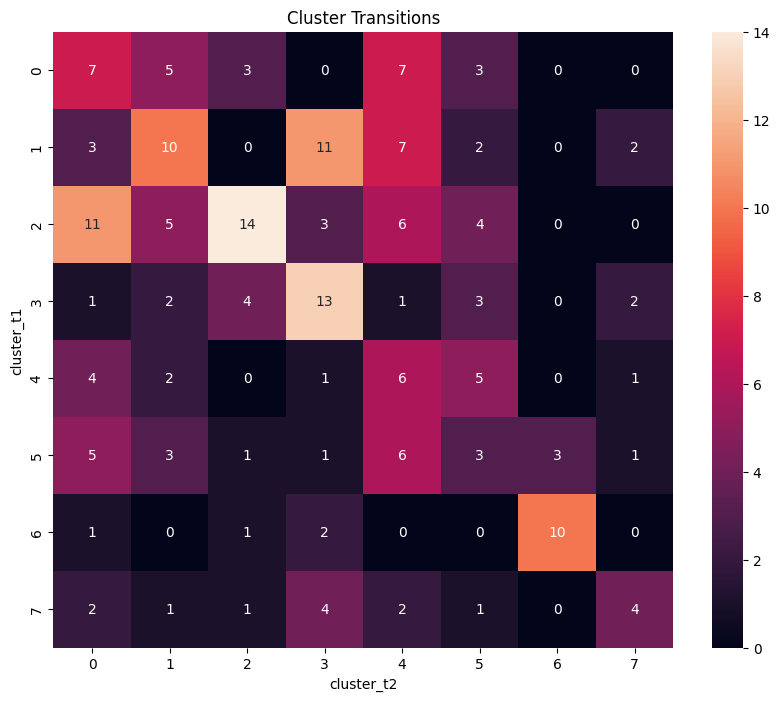

Done


In [43]:
# ============================================================
# FINAL PIPELINE: CHANGE DETECTION + CLUSTER INTERPRETATION
# ============================================================

%pip install rasterio einops scikit-learn -q

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import os
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
import rasterio
from einops import rearrange

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

import os

def _resolve_dataset(*candidates):
    """First existing path wins. Lets the notebook run locally or on Kaggle
    without editing paths (and without needing a /kaggle symlink)."""
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(
        "Dataset not found. Tried:\n  " + "\n  ".join(candidates))

OSCD_ROOT = _resolve_dataset(
    'oscd-dataset/OSCD',
    '/home/iit-dharwad/sav/oscd-dataset/OSCD',
    '/kaggle/input/datasets/mohamedazizbellaaj/oscd-dataset/OSCD',
)
CLASSIFIER_PATH = _resolve_dataset(
    os.path.join('checkpoints', 'classifier', 'ssmae_classifier_best.pth'),
    '/home/iit-dharwad/sav/checkpoints/classifier/ssmae_classifier_best.pth',
    '/kaggle/input/models/krishnasaigollamudi/modelsah/pytorch/default/1/ssmae_classifier_best.pth',
)

# ============================================================
# CONFIG
# ============================================================

class Config:
    IMG_SIZE = 64
    PATCH_SIZE = 8
    NUM_BANDS = 13          # was 12 -- the checkpoint's patch_embed expects 13
    NUM_CLASSES = 10
    EMBED_DIM = 512
    ENCODER_DEPTH = 8
    ENCODER_HEADS = 8
    CLASS_NAMES = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway',
                   'Industrial', 'Pasture', 'PermanentCrop', 'Residential',
                   'River', 'SeaLake']

config = Config()

# ============================================================
# MODEL - nesting matches the saved checkpoint
# ============================================================

class SSMAE(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.patch_embed = nn.Conv2d(
            config.NUM_BANDS, config.EMBED_DIM,
            kernel_size=config.PATCH_SIZE, stride=config.PATCH_SIZE)
        num_patches = (config.IMG_SIZE // config.PATCH_SIZE) ** 2
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, config.EMBED_DIM))
        self.encoder = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=config.EMBED_DIM, nhead=config.ENCODER_HEADS,
                dim_feedforward=config.EMBED_DIM * 4, batch_first=True)
            for _ in range(config.ENCODER_DEPTH)])
        self.norm = nn.LayerNorm(config.EMBED_DIM)

    def forward(self, x):
        x = self.patch_embed(x)
        x = rearrange(x, 'b d h w -> b (h w) d') + self.pos_embed
        for layer in self.encoder:
            x = layer(x)
        return self.norm(x)

class SSMAEClassifier(nn.Module):
    def __init__(self, encoder, num_classes=10):
        super().__init__()
        self.encoder = encoder
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, x):
        return self.classifier(self.encoder(x).mean(dim=1))

    def features(self, x):
        return self.encoder(x).mean(dim=1)

def load_pretrained_classifier(weights_path, config, device):
    """Build SSMAEClassifier and load the checkpoint with an explicit key check.

    strict=False silently tolerates a total mismatch. In the OSCD cells this hid
    the fact that ZERO tensors were being loaded, so every reported number came
    from a randomly initialised network. This asserts that the load actually
    matched something.
    """
    backbone = SSMAE(config)
    model = SSMAEClassifier(backbone)
    sd = torch.load(weights_path, map_location=device)
    tgt = model.state_dict()

    # Accept either flat ("patch_embed.weight") or nested ("encoder.patch_embed.weight")
    remapped = {}
    for k, v in sd.items():
        for cand in (k, f"encoder.{k}", k.replace("encoder.", "", 1)):
            if cand in tgt and tgt[cand].shape == v.shape:
                remapped[cand] = v
                break

    n_enc = sum(1 for k in remapped if k.startswith("encoder."))
    if n_enc == 0:
        raise RuntimeError(
            f"No encoder tensors matched from {weights_path}.\n"
            f"  checkpoint keys (sample): {list(sd)[:4]}\n"
            f"  model keys (sample):      {list(tgt)[:4]}")

    missing, _ = model.load_state_dict(remapped, strict=False)
    print(f"✅ Loaded {len(remapped)}/{len(tgt)} tensors "
          f"({n_enc} encoder) from {os.path.basename(weights_path)}")
    if missing:
        print(f"   ⚠️  {len(missing)} tensors left at init: {missing[:4]}"
              f"{' ...' if len(missing) > 4 else ''}")
    return model.to(device).eval()

print("Loading model...")
model = load_pretrained_classifier(CLASSIFIER_PATH, config, device)

# ============================================================
# DATA LOADING
# ============================================================
# Sentinel-2 band order used by EuroSATallBands, i.e. the order the encoder was
# trained on. sorted(glob("B*.tif")) is NOT this order: it sorts B8A after B12,
# so every band from index 8 up was fed to the wrong channel.
BAND_ORDER = ['B01','B02','B03','B04','B05','B06','B07','B08',
              'B8A','B09','B10','B11','B12']

def _stack_bands(folder):
    """Read a Sentinel-2 scene folder into (13, H, W) in BAND_ORDER."""
    available = {}
    for f in os.listdir(folder):
        if not f.endswith('.tif'):
            continue
        stem = f[:-4]
        for b in BAND_ORDER:
            if stem.endswith(b):
                available[b] = os.path.join(folder, f)
    missing = [b for b in BAND_ORDER if b not in available]
    if missing:
        raise FileNotFoundError(f"{folder}: missing bands {missing}")
    bands = []
    for b in BAND_ORDER:
        with rasterio.open(available[b]) as src:
            bands.append(src.read(1).astype(np.float32))
    return np.stack(bands)
def preprocess_patch(patch):
    """Per-band normalisation IDENTICAL to EuroSATDataset.normalize_bands used
    during training: 2/98 percentile clip, then min-max to [0,1]. The previous
    plain min-max (and the /10000 variant elsewhere) put inference data on a
    different scale from training data."""
    patch = patch.astype(np.float32)
    out = np.zeros_like(patch)
    for i in range(patch.shape[0]):
        band = patch[i]
        p2, p98 = np.percentile(band, [2, 98])
        band = np.clip(band, p2, p98)
        lo, hi = band.min(), band.max()
        out[i] = (band - lo) / (hi - lo) if hi > lo else band
    return torch.from_numpy(out)

def load_image(city_path, time):
    return _stack_bands(os.path.join(city_path, f'imgs_{time}_rect'))

def extract_patches(img1, img2, size=64):
    _, H, W = img1.shape
    patches = []
    for y in range(0, H - size, size):
        for x in range(0, W - size, size):
            patches.append((img1[:, y:y+size, x:x+size],
                            img2[:, y:y+size, x:x+size], y, x))
    return patches

def get_features(patch):
    t = preprocess_patch(patch).unsqueeze(0).to(device)
    with torch.no_grad():
        f = model.features(t)
    return f.cpu().numpy()[0]

def compute_indices(patch):
    """NDVI / NDWI from raw reflectance, using BAND_ORDER indices."""
    B3 = patch[BAND_ORDER.index('B03')]   # Green
    B4 = patch[BAND_ORDER.index('B04')]   # Red
    B8 = patch[BAND_ORDER.index('B08')]   # NIR
    ndvi = (B8 - B4) / (B8 + B4 + 1e-6)
    ndwi = (B3 - B8) / (B3 + B8 + 1e-6)
    return ndvi.mean(), ndwi.mean(), patch.mean()

# ============================================================
# PROCESS DATA
# ============================================================

cities = sorted(c for c in os.listdir(OSCD_ROOT)
                if os.path.isdir(os.path.join(OSCD_ROOT, c)))

all_results = []
city_cache = {}

for city in cities[:2]:
    print("Processing:", city)
    path = os.path.join(OSCD_ROOT, city)
    img1 = load_image(path, '1')
    img2 = load_image(path, '2')
    city_cache[city] = img1          # reused below instead of re-reading per patch

    for p1, p2, y, x in tqdm(extract_patches(img1, img2), leave=False):
        f1 = get_features(p1)
        f2 = get_features(p2)
        all_results.append({'f1': f1, 'f2': f2,
                            'feat_dist': float(np.linalg.norm(f1 - f2)),
                            'city': city, 'y': y, 'x': x})

df = pd.DataFrame(all_results)

# ============================================================
# CHANGE DETECTION + CLUSTERING
# ============================================================

threshold = df['feat_dist'].quantile(0.75)
df['changed'] = df['feat_dist'] > threshold

# .tolist() turns the Series into a plain list[ndarray]; np.stack has no
# overload accepting a Series, though it iterates fine at runtime.
features_t1 = np.stack(df['f1'].tolist())
features_t2 = np.stack(df['f2'].tolist())
kmeans = KMeans(n_clusters=8, random_state=42, n_init=10)
kmeans.fit(np.vstack([features_t1, features_t2]))

df['cluster_t1'] = kmeans.predict(features_t1)
df['cluster_t2'] = kmeans.predict(features_t2)
df['transition'] = df['cluster_t1'].astype(str) + " → " + df['cluster_t2'].astype(str)

# ============================================================
# CLUSTER INTERPRETATION
# ============================================================

cluster_stats = {}
for cluster in sorted(df['cluster_t1'].unique()):
    sub = df[df['cluster_t1'] == cluster].head(50)
    # Pull the three columns out as plain python str/int up front. Indexing a
    # DataFrame per row gives pandas' Scalar type, a union that includes
    # complex -- so neither `y + 64` nor even `int(y)` type-checks against it.
    # Column-wise .astype().tolist() sidesteps that and skips 50 .loc lookups.
    cities = sub['city'].astype(str).tolist()
    ys     = sub['y'].astype(int).tolist()
    xs     = sub['x'].astype(int).tolist()
    ndvi_list, ndwi_list, bright_list = [], [], []
    for city, y, x in zip(cities, ys, xs):
        patch = city_cache[city][:, y:y+64, x:x+64]
        ndvi, ndwi, bright = compute_indices(patch)
        ndvi_list.append(ndvi); ndwi_list.append(ndwi); bright_list.append(bright)
    cluster_stats[cluster] = {'ndvi': np.mean(ndvi_list),
                              'ndwi': np.mean(ndwi_list),
                              'brightness': np.mean(bright_list)}

# ============================================================
# RESULTS
# ============================================================

print("\n" + "="*50)
print("RESULTS")
print("="*50)
print("Total patches:", len(df))
changed = df[df['changed']]
print("Changes:", len(changed), f"({len(changed)/len(df)*100:.1f}%)")
print("  (note: 'changed' is the top quartile of feature distance by")
print("   construction, so this rate is fixed at 25% and is not a measurement)")

print("\nCluster statistics (interpretation):")
for c, stats in cluster_stats.items():
    print(f"Cluster {c}: NDVI={stats['ndvi']:.2f}, "
          f"NDWI={stats['ndwi']:.2f}, Bright={stats['brightness']:.1f}")

print("\nInterpretation guide:")
print("High NDVI → Vegetation")
print("High NDWI → Water")
print("High Brightness → Urban/Barren")

print("\nTop transitions:")
print(df['transition'].value_counts().head(10))
print("\nTop changed transitions:")
print(changed['transition'].value_counts().head(10))

matrix = pd.crosstab(df['cluster_t1'], df['cluster_t2'])
plt.figure(figsize=(10,8))
sns.heatmap(matrix, annot=True, fmt='d')
plt.title("Cluster Transitions")
plt.show()

df.drop(columns=['f1', 'f2']).to_csv("final_results.csv", index=False)
print("Done")


/home/iit-dharwad/anaconda3/envs/diff/lib/python3.10/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


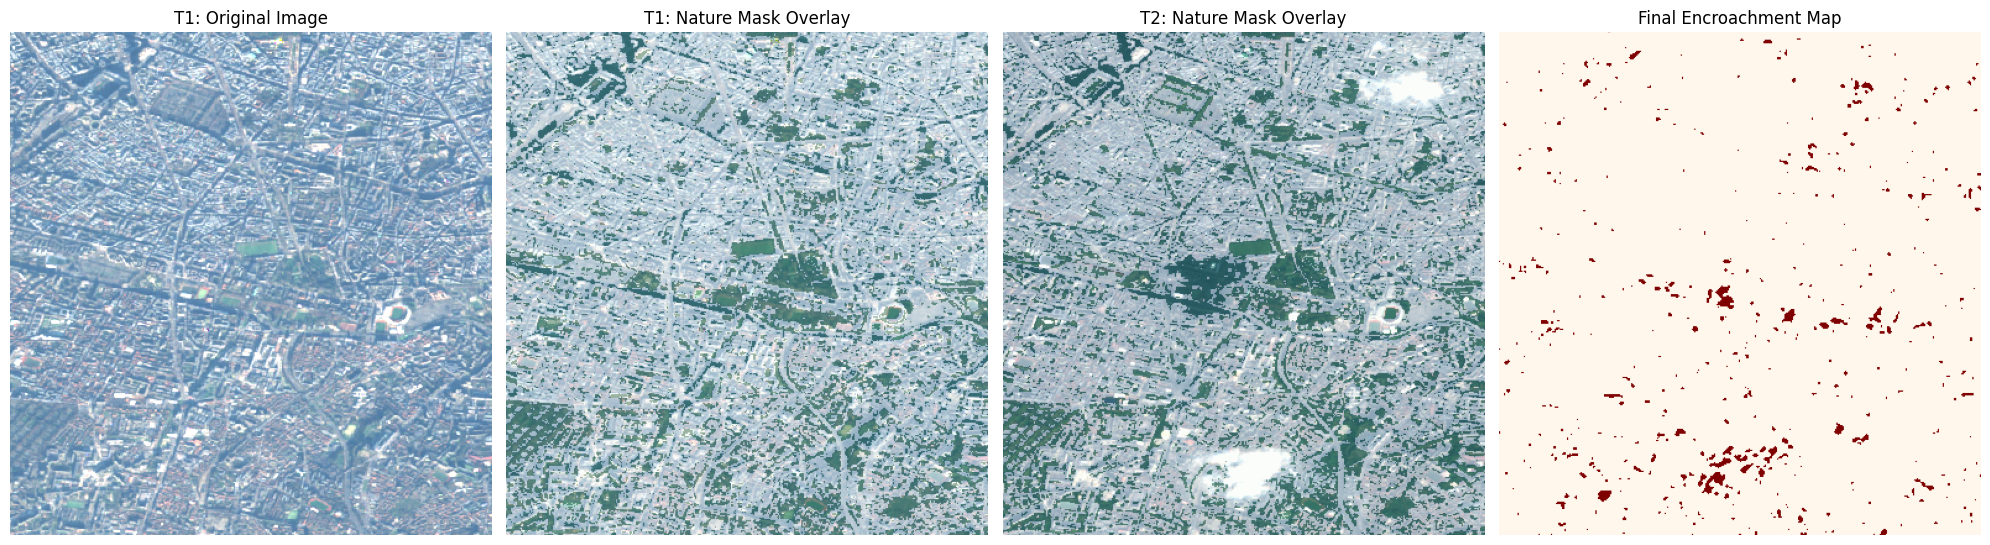

Total Nature Encroachment detected: 2.03% of the area.


In [44]:
import numpy as np
import matplotlib.pyplot as plt
import os
import scipy.ndimage as ndimage
import rasterio

# ============================================================
# 1. LOAD DATA WITH ROBUST SCALING
# ============================================================
def load_oscd_sample(folder_path):
    """
    Loads Blue, Green, Red, and NIR bands and scales them 
    using the 98th percentile to prevent all-black images.
    """
    band_files = ['B02', 'B03', 'B04', 'B08']
    data = []
    for b in band_files:
        path = os.path.join(folder_path, f"{b}.tif")
        if not os.path.exists(path):
            raise FileNotFoundError(f"Could not find {path}")
            
        with rasterio.open(path) as src:
            band = src.read(1).astype(np.float32)
            # Use 98th percentile to scale (ignores sensor noise/bright clouds)
            v_max = np.percentile(band, 98)
            band = np.clip(band, 0, v_max) / (v_max + 1e-6)
            data.append(band)
            
    return np.array(data)

# Update these paths to your Kaggle directories
import os

def _resolve_dataset(*candidates):
    """First existing path wins. Lets the notebook run locally or on Kaggle
    without editing paths (and without needing a /kaggle symlink)."""
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(
        "Dataset not found. Tried:\n  " + "\n  ".join(candidates))

_OSCD_ROOT = _resolve_dataset(
    "oscd-dataset/OSCD",
    "/home/iit-dharwad/sav/oscd-dataset/OSCD",
    "/kaggle/input/datasets/mohamedazizbellaaj/oscd-dataset/OSCD",
)
path_t1 = os.path.join(_OSCD_ROOT, "paris", "imgs_1_rect")
path_t2 = os.path.join(_OSCD_ROOT, "paris", "imgs_2_rect")

t1_stack = load_oscd_sample(path_t1)
t2_stack = load_oscd_sample(path_t2)

# ============================================================
# 2. CALCULATE INDICES & NATURE MASKS
# ============================================================
def get_nature_mask(img_stack):
    """
    Calculates NDVI and NDWI, then creates a mask for Nature 
    (Vegetation + Water) using relative percentiles.
    """
    _B, G, R, NIR = img_stack[0], img_stack[1], img_stack[2], img_stack[3]
    
    # Standard Spectral Indices
    ndvi = (NIR - R) / (NIR + R + 1e-6)
    ndwi = (G - NIR) / (G + NIR + 1e-6)
    
    # We define Nature as the top 20% greenest pixels 
    # and top 5% most 'water-like' pixels in the image.
    thresh_veg = np.percentile(ndvi, 80)
    thresh_wat = np.percentile(ndwi, 95)
    
    mask = (ndvi > thresh_veg) | (ndwi > thresh_wat)
    return mask

is_nat_t1 = get_nature_mask(t1_stack)
is_nat_t2 = get_nature_mask(t2_stack)

# ============================================================
# 3. CHANGE DETECTION & DENOISING
# ============================================================

# Raw Encroachment: Was nature in T1, but is not nature in T2
raw_encroachment = np.logical_and(is_nat_t1 == True, is_nat_t2 == False)

# Median Filter: This removes the 'speckle' noise by looking at 
# a 3x3 neighborhood and removing isolated pixels.
clean_encroachment = ndimage.median_filter(raw_encroachment.astype(float), size=3)

# ============================================================
# 4. VISUALIZATION
# ============================================================
plt.figure(figsize=(20, 8))

# Subplot 1: T1 RGB Reference
plt.subplot(1, 4, 1)
rgb_t1 = np.stack([t1_stack[2], t1_stack[1], t1_stack[0]], axis=-1)
plt.imshow(rgb_t1)
plt.title("T1: Original Image")
plt.axis('off')

# Subplot 2: T1 Nature Mask (Validation)
plt.subplot(1, 4, 2)
plt.imshow(rgb_t1)
plt.imshow(is_nat_t1, cmap='Greens', alpha=0.4) # Transparent overlay
plt.title("T1: Nature Mask Overlay")
plt.axis('off')

# Subplot 3: T2 Nature Mask (Validation)
plt.subplot(1, 4, 3)
rgb_t2 = np.stack([t2_stack[2], t2_stack[1], t2_stack[0]], axis=-1)
plt.imshow(rgb_t2)
plt.imshow(is_nat_t2, cmap='Greens', alpha=0.4)
plt.title("T2: Nature Mask Overlay")
plt.axis('off')

# Subplot 4: Final Encroachment
plt.subplot(1, 4, 4)
plt.imshow(clean_encroachment, cmap='OrRd')
plt.title("Final Encroachment Map")
plt.axis('off')

plt.tight_layout()
plt.show()

# Print statistics
change_percentage = (np.sum(clean_encroachment) / clean_encroachment.size) * 100
print(f"Total Nature Encroachment detected: {change_percentage:.2f}% of the area.")

In [45]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, classification_report
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
import rasterio
from einops import rearrange
from sklearn.metrics import accuracy_score, f1_score, classification_report

# --- 1. CONFIGURATION ---
import os

def _resolve_dataset(*candidates):
    """First existing path wins. Lets the notebook run locally or on Kaggle
    without editing paths (and without needing a /kaggle symlink)."""
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(
        "Dataset not found. Tried:\n  " + "\n  ".join(candidates))

_EUROSAT_ROOT = _resolve_dataset(
    'eurosat-dataset',
    '/home/iit-dharwad/sav/eurosat-dataset',
    '/kaggle/input/datasets/apollo2506/eurosat-dataset',
)

class Config:
    BASE_PATH = f"{_EUROSAT_ROOT}/EuroSAT"
    IMG_DIR   = f"{_EUROSAT_ROOT}/EuroSATallBands"
    TRAIN_CSV = f"{BASE_PATH}/train.csv"
    VAL_CSV = f"{BASE_PATH}/validation.csv"
    TEST_CSV = f"{BASE_PATH}/test.csv"

    IMG_SIZE, PATCH_SIZE, NUM_BANDS = 64, 8, 13
    NUM_CLASSES = 10
    CLASS_NAMES = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway',
                   'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']

    PRETRAIN_BATCH_SIZE, FINETUNE_BATCH_SIZE = 128, 64
    PRETRAIN_LR, FINETUNE_LR = 1.5e-4, 1e-4
    EMBED_DIM, ENCODER_DEPTH, ENCODER_HEADS = 512, 8, 8
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

config = Config()

# --- 2. DATASET LOADER ---
class EuroSATDataset(Dataset):
    def __init__(self, csv_path, img_dir):
        self.df = pd.read_csv(csv_path)
        self.img_dir = img_dir
        self.samples = list(zip(self.df['Filename'], self.df['Label']))

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        filename, label = self.samples[idx]
        tif_filename = filename.replace('.jpg', '.tif')
        img_path = os.path.join(self.img_dir, tif_filename)

        with rasterio.open(img_path) as src:
            image = src.read().astype(np.float32)

        # Same 2/98 percentile clip + min-max as the pretraining dataset.
        # (Plain min-max here put inference data on a different scale than the
        # data the encoder was trained on.)
        out = np.zeros_like(image)
        for i in range(image.shape[0]):
            band = image[i]
            p2, p98 = np.percentile(band, [2, 98])
            band = np.clip(band, p2, p98)
            lo, hi = band.min(), band.max()
            out[i] = (band - lo) / (hi - lo) if hi > lo else band

        return torch.from_numpy(out), torch.tensor(label, dtype=torch.long)

# --- 3. SS-MAE ENCODER ---
class SSMAE(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.patch_embed = nn.Conv2d(config.NUM_BANDS, config.EMBED_DIM, kernel_size=8, stride=8)
        self.pos_embed = nn.Parameter(torch.zeros(1, 64, config.EMBED_DIM))
        self.encoder = nn.ModuleList([
            nn.TransformerEncoderLayer(d_model=config.EMBED_DIM, nhead=8, batch_first=True)
            for _ in range(config.ENCODER_DEPTH)
        ])
        self.norm = nn.LayerNorm(config.EMBED_DIM)

    def forward(self, x):
        x = self.patch_embed(x)
        x = rearrange(x, 'b d h w -> b (h w) d') + self.pos_embed
        for layer in self.encoder: x = layer(x)
        return self.norm(x)

class SSMAEClassifier(nn.Module):
    def __init__(self, encoder, num_classes=10):
        super().__init__()
        self.encoder = encoder
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.encoder(x).mean(dim=1)
        return self.classifier(x)

def load_pretrained_encoder(model, ckpt_path, device):
    """Load the SELF-SUPERVISED encoder weights (not the supervised classifier).

    These cells previously never loaded any checkpoint at all -- they built a
    fresh SSMAE and trained it from scratch, while reporting the result as
    evidence for transfer learning. Loading the fine-tuned *classifier* here
    would be the opposite error (it has seen 100% of the labels), so we load
    the pretrain checkpoint and drop decoder/classifier keys.
    """
    sd = torch.load(ckpt_path, map_location=device)
    tgt = model.state_dict()
    keep = {k: v for k, v in sd.items()
            if k in tgt and tgt[k].shape == v.shape and not k.startswith('decoder')}
    if not keep:
        raise RuntimeError(f"No encoder tensors matched from {ckpt_path}. "
                           f"ckpt keys: {list(sd)[:4]} | model keys: {list(tgt)[:4]}")
    model.load_state_dict(keep, strict=False)
    print(f"✅ Loaded {len(keep)}/{len(tgt)} encoder tensors from "
          f"{os.path.basename(ckpt_path)}")
    return model

PRETRAIN_CKPT = _resolve_dataset(
    os.path.join('checkpoints', 'pretrain', 'ssmae_pretrain_epoch100.pth'),
    '/home/iit-dharwad/sav/checkpoints/pretrain/ssmae_pretrain_epoch100.pth',
    '/kaggle/input/models/krishnasaigollamudi/modelsah/'
    'pytorch/default/1/ssmae_pretrain_epoch100.pth',
)

# --- 4. LABEL EFFICIENCY: PRETRAINED vs SCRATCH ---
def run_experiment(pretrained=True, epochs=5, seed=42):
    tag = "SS-MAE pretrained" if pretrained else "from scratch"
    print(f"🚀 Label-efficiency run (10% labels, {tag})")

    train_ds = EuroSATDataset(config.TRAIN_CSV, config.IMG_DIR)
    test_ds = EuroSATDataset(config.TEST_CSV, config.IMG_DIR)

    rng = np.random.default_rng(seed)
    indices = rng.choice(len(train_ds), int(len(train_ds)*0.1), replace=False).tolist()
    subset_loader = DataLoader(Subset(train_ds, indices),
                               batch_size=config.FINETUNE_BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_ds, batch_size=config.FINETUNE_BATCH_SIZE)

    torch.manual_seed(seed)
    backbone = SSMAE(config)
    if pretrained:
        backbone = load_pretrained_encoder(backbone, PRETRAIN_CKPT, config.DEVICE)
    classifier = SSMAEClassifier(backbone).to(config.DEVICE)

    optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-4)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        classifier.train()
        for imgs, labels in tqdm(subset_loader, desc=f"  epoch {epoch+1}/{epochs}", leave=False):
            optimizer.zero_grad()
            loss = criterion(classifier(imgs.to(config.DEVICE)), labels.to(config.DEVICE))
            loss.backward()
            optimizer.step()

    classifier.eval()
    preds, gts = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            logits = classifier(imgs.to(config.DEVICE))
            preds.extend(logits.argmax(1).cpu().numpy())
            gts.extend(labels.numpy())
    return gts, preds

# Pretrained vs scratch under an identical budget -- that contrast is the
# whole point of the experiment, and the scratch arm was missing.
ARMS_CACHE = os.path.join('checkpoints', 'cache', 'label_efficiency_arms.json')

if have_checkpoint(ARMS_CACHE):
    announce_skip(ARMS_CACHE, 'pretrained-vs-scratch runs (2 training runs)')
    _c = _json.load(open(ARMS_CACHE))
    gts_pt, preds_pt = _c['gts_pt'], _c['preds_pt']
    gts_sc, preds_sc = _c['gts_sc'], _c['preds_sc']
else:
    gts_pt,  preds_pt  = run_experiment(pretrained=True)
    gts_sc,  preds_sc  = run_experiment(pretrained=False)
    _json.dump({'gts_pt': [int(v) for v in gts_pt], 'preds_pt': [int(v) for v in preds_pt],
                'gts_sc': [int(v) for v in gts_sc], 'preds_sc': [int(v) for v in preds_sc]},
               open(ARMS_CACHE, 'w'))
    print(f'cached arm predictions -> {ARMS_CACHE}')

print("\n✅ 10% labels, SS-MAE PRETRAINED encoder:")
print(classification_report(gts_pt, preds_pt, target_names=config.CLASS_NAMES))
print("\n✅ 10% labels, FROM SCRATCH (no pretraining):")
print(classification_report(gts_sc, preds_sc, target_names=config.CLASS_NAMES))
print(f"\nAccuracy  pretrained {accuracy_score(gts_pt, preds_pt)*100:.2f}%  "
      f"vs scratch {accuracy_score(gts_sc, preds_sc)*100:.2f}%")
print(f"Macro F1  pretrained {f1_score(gts_pt, preds_pt, average='macro'):.4f}  "
      f"vs scratch {f1_score(gts_sc, preds_sc, average='macro'):.4f}")

gts, preds = gts_pt, preds_pt


/tmp/ipykernel_1907600/634181632.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location=device)


🚀 Label-efficiency run (10% labels, SS-MAE pretrained)
✅ Loaded 101/101 encoder tensors from ssmae_pretrain_epoch100.pth


🚀 Label-efficiency run (10% labels, from scratch)


cached arm predictions -> checkpoints/cache/label_efficiency_arms.json

✅ 10% labels, SS-MAE PRETRAINED encoder:
                      precision    recall  f1-score   support

          AnnualCrop       0.84      0.77      0.81       300
              Forest       0.81      0.72      0.76       300
HerbaceousVegetation       0.54      0.56      0.55       300
             Highway       0.69      0.24      0.35       250
          Industrial       0.79      0.77      0.78       250
             Pasture       0.49      0.76      0.60       200
       PermanentCrop       0.53      0.60      0.56       250
         Residential       0.73      0.80      0.77       300
               River       0.87      0.90      0.88       250
             SeaLake       0.84      0.96      0.90       300

            accuracy                           0.71      2700
           macro avg       0.71      0.71      0.70      2700
        weighted avg       0.72      0.71      0.70      2700


✅ 10% labels, F

10% LABELS - SS-MAE PRETRAINED
                      precision    recall  f1-score   support

          AnnualCrop       0.84      0.77      0.81       300
              Forest       0.81      0.72      0.76       300
HerbaceousVegetation       0.54      0.56      0.55       300
             Highway       0.69      0.24      0.35       250
          Industrial       0.79      0.77      0.78       250
             Pasture       0.49      0.76      0.60       200
       PermanentCrop       0.53      0.60      0.56       250
         Residential       0.73      0.80      0.77       300
               River       0.87      0.90      0.88       250
             SeaLake       0.84      0.96      0.90       300

            accuracy                           0.71      2700
           macro avg       0.71      0.71      0.70      2700
        weighted avg       0.72      0.71      0.70      2700



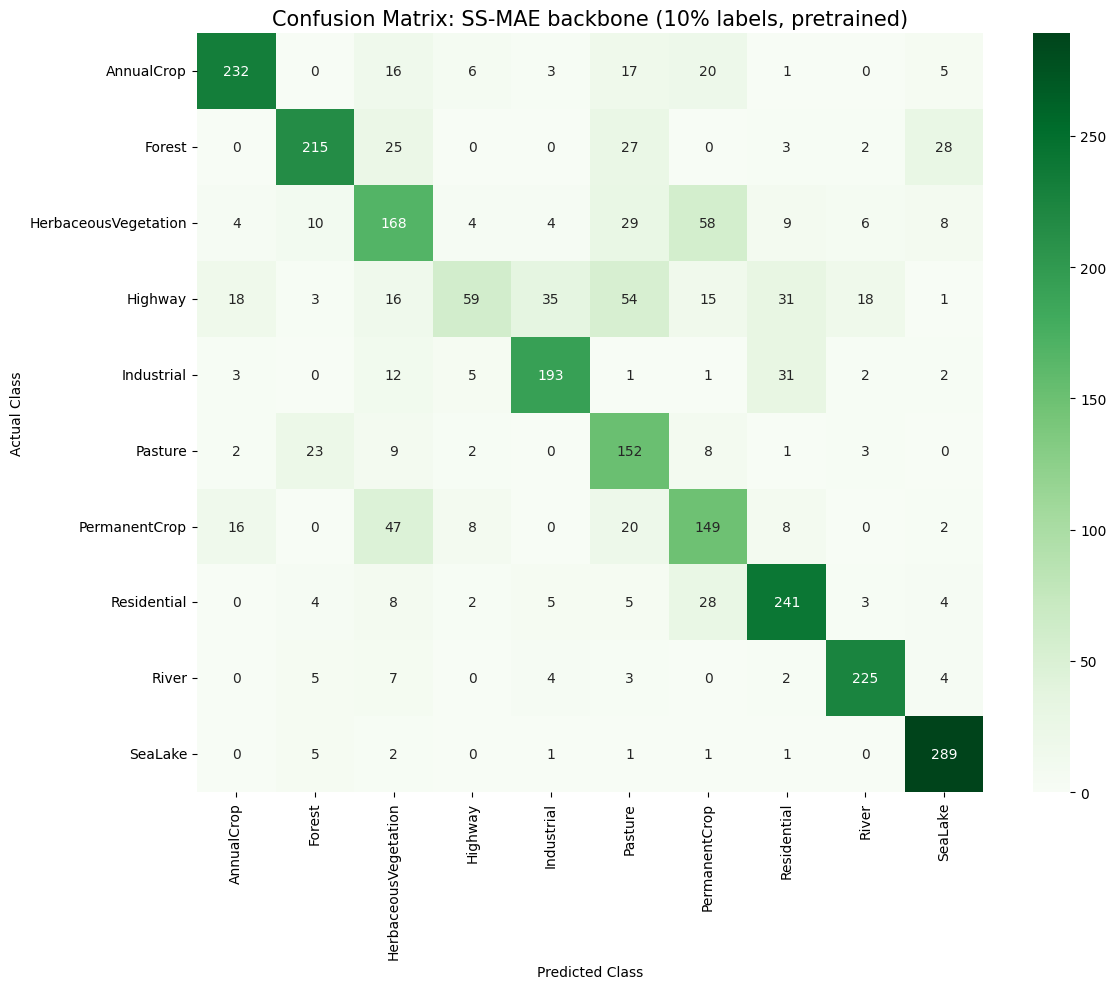

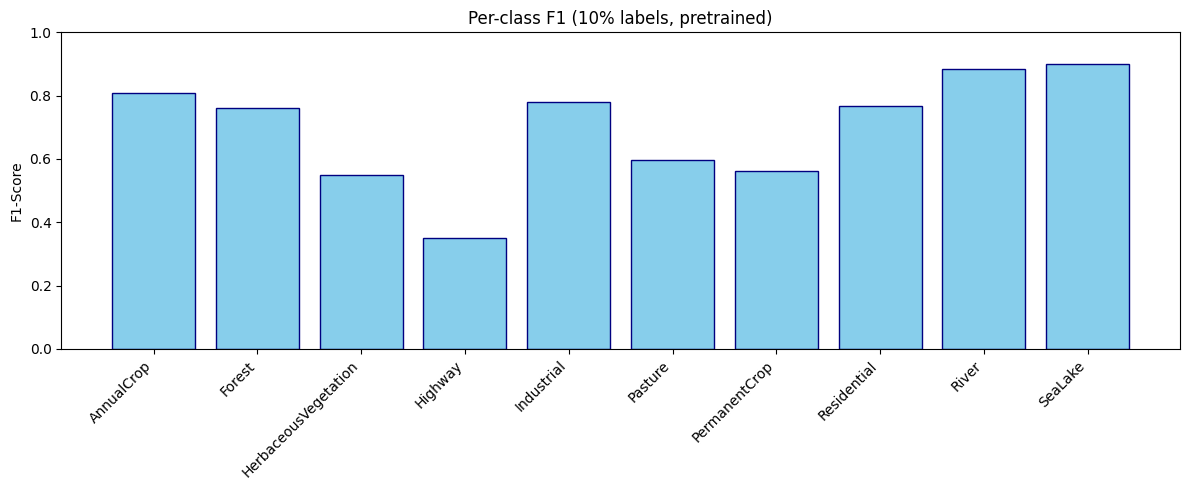

10% LABELS - FROM SCRATCH
                      precision    recall  f1-score   support

          AnnualCrop       0.88      0.77      0.82       300
              Forest       0.86      0.65      0.74       300
HerbaceousVegetation       0.54      0.56      0.55       300
             Highway       0.72      0.27      0.39       250
          Industrial       0.84      0.73      0.78       250
             Pasture       0.46      0.84      0.60       200
       PermanentCrop       0.51      0.62      0.56       250
         Residential       0.73      0.84      0.78       300
               River       0.91      0.82      0.87       250
             SeaLake       0.85      0.97      0.91       300

            accuracy                           0.71      2700
           macro avg       0.73      0.71      0.70      2700
        weighted avg       0.74      0.71      0.71      2700



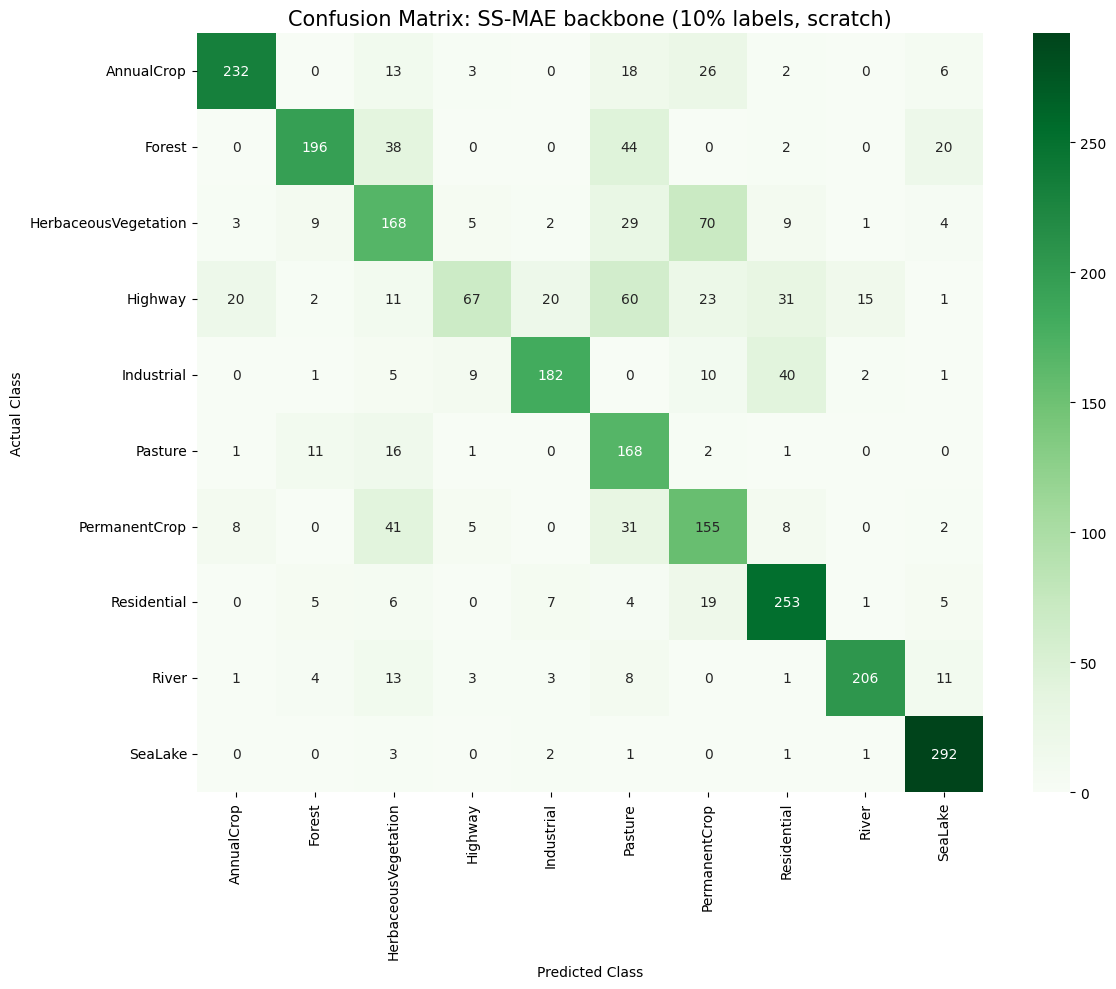

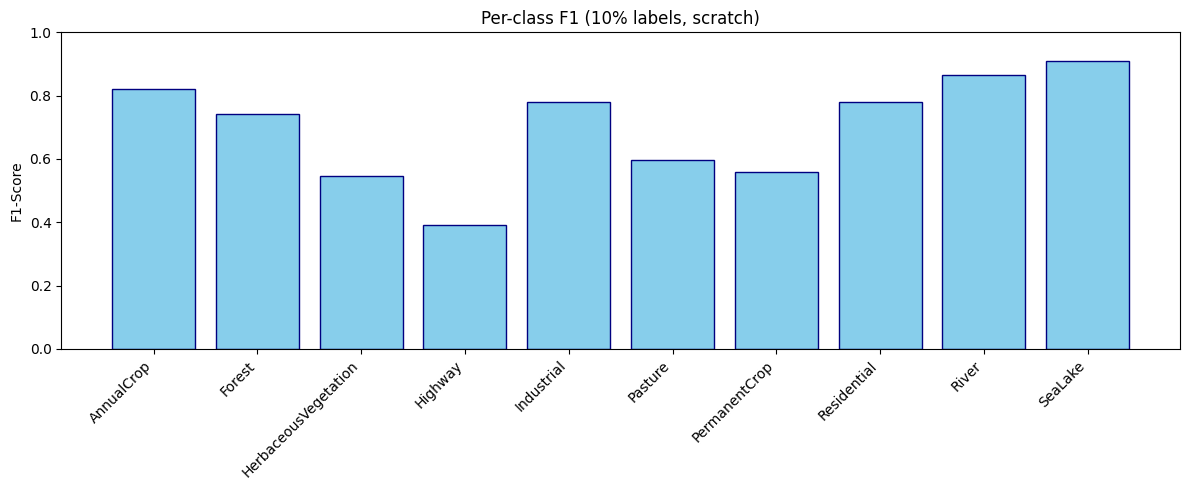

In [46]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
from typing import cast

# This cell reuses the config / dataset / model / experiment defined in the
# cell above rather than redeclaring near-identical copies of them (the two
# copies had drifted apart: this one silently dropped the pretrained-weight
# load and the 5-epoch loop label).
assert 'run_experiment' in globals(), "Run the previous cell first."

# --- VISUALIZATION ---
def plot_results(gts, preds, class_names, title_suffix=""):
    cm = confusion_matrix(gts, preds)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix: SS-MAE backbone{title_suffix}', fontsize=15)
    plt.ylabel('Actual Class')
    plt.xlabel('Predicted Class')
    plt.tight_layout()
    plt.show()

    # cast() is a runtime no-op that pins the static type. sklearn's stub
    # declares classification_report(...) -> str with no overload for
    # output_dict=True (which really returns a dict), so without this the
    # type checker reads report[c] as a str and rejects the 'f1-score' key.
    report = cast(dict, classification_report(gts, preds,
                                              target_names=class_names,
                                              output_dict=True))
    f1_scores = [report[c]['f1-score'] for c in class_names]

    plt.figure(figsize=(12, 5))
    plt.bar(class_names, f1_scores, color='skyblue', edgecolor='navy')
    plt.xticks(rotation=45, ha='right')
    plt.title(f'Per-class F1{title_suffix}')
    plt.ylabel('F1-Score')
    plt.ylim(0, 1.0)
    plt.tight_layout()
    plt.show()

print("="*40)
print("10% LABELS - SS-MAE PRETRAINED")
print("="*40)
print(classification_report(gts_pt, preds_pt, target_names=config.CLASS_NAMES))
plot_results(gts_pt, preds_pt, config.CLASS_NAMES, " (10% labels, pretrained)")

print("="*40)
print("10% LABELS - FROM SCRATCH")
print("="*40)
print(classification_report(gts_sc, preds_sc, target_names=config.CLASS_NAMES))
plot_results(gts_sc, preds_sc, config.CLASS_NAMES, " (10% labels, scratch)")


In [47]:
# ---------------------------------------------------------------------------
# REMOVED - this analysis was not measuring anything.
#
# It built "T1" and "T2" by splitting the test-set prediction list in half and
# zipping the two halves together, so it paired prediction i with prediction
# i+1350 -- two unrelated EuroSAT scenes from different places. Every "Forest →
# Residential transition" it counted was an artefact of that arbitrary pairing;
# the numbers change completely if the test set is shuffled.
#
# Real temporal transitions need co-registered before/after imagery of the SAME
# location. The OSCD cells below do this properly (imgs_1_rect vs imgs_2_rect
# for one city).
# ---------------------------------------------------------------------------
print("Removed: paired unrelated scenes. See the OSCD cells for real T1/T2 analysis.")


Removed: paired unrelated scenes. See the OSCD cells for real T1/T2 analysis.


In [48]:
import os

def _resolve_dataset(*candidates):
    """First existing path wins. Lets the notebook run locally or on Kaggle
    without editing paths (and without needing a /kaggle symlink)."""
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(
        "Dataset not found. Tried:\n  " + "\n  ".join(candidates))

import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import torch.nn.functional as F
import rasterio
from einops import rearrange

# --- 1. CONFIGURATION ---
class Config:
    OSCD_ROOT = _resolve_dataset(
        "oscd-dataset/OSCD",
        "/home/iit-dharwad/sav/oscd-dataset/OSCD",
        "/kaggle/input/datasets/mohamedazizbellaaj/oscd-dataset/OSCD",
    )
    CLASSIFIER_WEIGHTS = _resolve_dataset(
        os.path.join("checkpoints", "classifier", "ssmae_classifier_best.pth"),
        "/home/iit-dharwad/sav/checkpoints/classifier/ssmae_classifier_best.pth",
        "/kaggle/input/models/krishnasaigollamudi/modelsah/pytorch/default/1/ssmae_classifier_best.pth",
    )

    IMG_SIZE, PATCH_SIZE, NUM_BANDS = 64, 8, 13
    NUM_CLASSES = 10
    EMBED_DIM, ENCODER_DEPTH, ENCODER_HEADS = 512, 8, 8
    CLASS_NAMES = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway',
                   'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

config = Config()

# --- 2. MODEL ARCHITECTURE ---
class SSMAE(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.patch_embed = nn.Conv2d(config.NUM_BANDS, 512, kernel_size=8, stride=8)
        self.pos_embed = nn.Parameter(torch.zeros(1, 64, 512))
        self.encoder = nn.ModuleList([
            nn.TransformerEncoderLayer(d_model=512, nhead=8, batch_first=True)
            for _ in range(8)
        ])
        self.norm = nn.LayerNorm(512)

    def forward(self, x):
        x = self.patch_embed(x)
        x = rearrange(x, 'b d h w -> b (h w) d') + self.pos_embed
        for layer in self.encoder: x = layer(x)
        return self.norm(x)

class SSMAEClassifier(nn.Module):
    def __init__(self, encoder, num_classes=10):
        super().__init__()
        self.encoder = encoder
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.encoder(x).mean(dim=1)
        return self.classifier(x)

# --- 3. DATA UTILITIES ---
# Sentinel-2 band order used by EuroSATallBands, i.e. the order the encoder was
# trained on. sorted(glob("B*.tif")) is NOT this order: it sorts B8A after B12,
# so every band from index 8 up was fed to the wrong channel.
BAND_ORDER = ['B01','B02','B03','B04','B05','B06','B07','B08',
              'B8A','B09','B10','B11','B12']

def _stack_bands(folder):
    """Read a Sentinel-2 scene folder into (13, H, W) in BAND_ORDER."""
    available = {}
    for f in os.listdir(folder):
        if not f.endswith('.tif'):
            continue
        stem = f[:-4]
        for b in BAND_ORDER:
            if stem.endswith(b):
                available[b] = os.path.join(folder, f)
    missing = [b for b in BAND_ORDER if b not in available]
    if missing:
        raise FileNotFoundError(f"{folder}: missing bands {missing}")
    bands = []
    for b in BAND_ORDER:
        with rasterio.open(available[b]) as src:
            bands.append(src.read(1).astype(np.float32))
    return np.stack(bands)
def preprocess_patch(patch):  # noqa: F811 - deliberate: this cell is a
    # self-contained entry point and must not depend on the OSCD cell above
    """Per-band normalisation IDENTICAL to EuroSATDataset.normalize_bands used
    during training: 2/98 percentile clip, then min-max to [0,1]. The previous
    plain min-max (and the /10000 variant elsewhere) put inference data on a
    different scale from training data."""
    patch = patch.astype(np.float32)
    out = np.zeros_like(patch)
    for i in range(patch.shape[0]):
        band = patch[i]
        p2, p98 = np.percentile(band, [2, 98])
        band = np.clip(band, p2, p98)
        lo, hi = band.min(), band.max()
        out[i] = (band - lo) / (hi - lo) if hi > lo else band
    return torch.from_numpy(out)
def load_pretrained_classifier(weights_path, config, device):
    """Build SSMAEClassifier and load the checkpoint with an explicit key check.

    strict=False silently tolerates a total mismatch. In the OSCD cells this hid
    the fact that ZERO tensors were being loaded, so every reported number came
    from a randomly initialised network. This asserts that the load actually
    matched something.
    """
    backbone = SSMAE(config)
    model = SSMAEClassifier(backbone)
    sd = torch.load(weights_path, map_location=device)
    tgt = model.state_dict()

    # Accept either flat ("patch_embed.weight") or nested ("encoder.patch_embed.weight")
    remapped = {}
    for k, v in sd.items():
        for cand in (k, f"encoder.{k}", k.replace("encoder.", "", 1)):
            if cand in tgt and tgt[cand].shape == v.shape:
                remapped[cand] = v
                break

    n_enc = sum(1 for k in remapped if k.startswith("encoder."))
    if n_enc == 0:
        raise RuntimeError(
            f"No encoder tensors matched from {weights_path}.\n"
            f"  checkpoint keys (sample): {list(sd)[:4]}\n"
            f"  model keys (sample):      {list(tgt)[:4]}")

    missing, _ = model.load_state_dict(remapped, strict=False)
    print(f"✅ Loaded {len(remapped)}/{len(tgt)} tensors "
          f"({n_enc} encoder) from {os.path.basename(weights_path)}")
    if missing:
        print(f"   ⚠️  {len(missing)} tensors left at init: {missing[:4]}"
              f"{' ...' if len(missing) > 4 else ''}")
    return model.to(device).eval()

def load_city_data(city_path):
    """Both dates of one city, plus the change mask if present."""
    img1 = _stack_bands(os.path.join(city_path, 'imgs_1_rect'))
    img2 = _stack_bands(os.path.join(city_path, 'imgs_2_rect'))
    cm_path = os.path.join(city_path, 'cm', 'cm.png')
    gt_mask = None
    if os.path.exists(cm_path):
        with rasterio.open(cm_path) as src:
            gt_mask = src.read(1)
    return img1, img2, gt_mask

def extract_patch_pairs(img1, img2, patch_size=64):
    """Aligned T1/T2 patch pairs plus their (y, x) origins."""
    _, H, W = img1.shape
    p1, p2, indices = [], [], []
    for y in range(0, H - patch_size, patch_size):
        for x in range(0, W - patch_size, patch_size):
            p1.append(preprocess_patch(img1[:, y:y+patch_size, x:x+patch_size]))
            p2.append(preprocess_patch(img2[:, y:y+patch_size, x:x+patch_size]))
            indices.append((y, x))
    return torch.stack(p1), torch.stack(p2), indices

def load_oscd_city(city_path, time_folder='imgs_1_rect'):
    folder = os.path.join(city_path, time_folder)
    if not os.path.isdir(folder):
        return None
    full_img = _stack_bands(folder)
    _, H, W = full_img.shape
    patches = []
    for y in range(0, H - 64, 64):
        for x in range(0, W - 64, 64):
            patches.append(preprocess_patch(full_img[:, y:y+64, x:x+64]))
    return torch.stack(patches) if patches else None

# --- 4. EXPERIMENT ENGINE ---
def run_paper_results(config):
    model = load_pretrained_classifier(config.CLASSIFIER_WEIGHTS, config, config.DEVICE)

    cities = sorted(d for d in os.listdir(config.OSCD_ROOT)
                    if os.path.isdir(os.path.join(config.OSCD_ROOT, d)))
    results_list = []

    print(f"🕵️ Analyzing OSCD Dataset for Encroachment...")

    for city in tqdm(cities):
        city_path = os.path.join(config.OSCD_ROOT, city)
        t1 = load_oscd_city(city_path, 'imgs_1_rect')
        t2 = load_oscd_city(city_path, 'imgs_2_rect')
        if t1 is None or t2 is None:
            continue

        enc_count = 0
        total = t1.size(0)

        with torch.no_grad():
            for i in range(0, total, 32):
                b1, b2 = t1[i:i+32].to(config.DEVICE), t2[i:i+32].to(config.DEVICE)
                conf1, pred1 = torch.max(F.softmax(model(b1), dim=1), 1)
                conf2, pred2 = torch.max(F.softmax(model(b2), dim=1), 1)

                for j in range(len(pred1)):
                    c1, c2 = config.CLASS_NAMES[int(pred1[j])], config.CLASS_NAMES[int(pred2[j])]
                    if c1 == 'Forest' and c2 in ['Residential', 'Industrial', 'Highway']:
                        if conf1[j] > 0.7 and conf2[j] > 0.7:
                            enc_count += 1

        rate = (enc_count / total) * 100
        results_list.append({'City': city.capitalize(),
                             'Encroachment %': f"{rate:.2f}%",
                             'Detections': enc_count,
                             'Patches': total})

    return pd.DataFrame(results_list)

# --- 5. EXECUTION ---
final_df = run_paper_results(config)
print("\n" + "="*52)
print("📊 OSCD ZERO-SHOT ENCROACHMENT TABLE")
print("="*52)
print(final_df.to_string(index=False))
print("\nNOTE: zero-shot, no OSCD ground truth used. These are unvalidated")
print("predictions -- OSCD's cm.png masks mark change, not land-cover class,")
print("so they cannot confirm a Forest→Urban transition directly.")

final_df.to_csv("oscd_encroachment_report.csv", index=False)


/tmp/ipykernel_1907600/234488339.py:125: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(weights_path, map_location=device)


✅ Loaded 103/103 tensors (101 encoder) from ssmae_classifier_best.pth
🕵️ Analyzing OSCD Dataset for Encroachment...


  0%|          | 0/24 [00:00<?, ?it/s]/home/iit-dharwad/anaconda3/envs/diff/lib/python3.10/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
100%|██████████| 24/24 [00:07<00:00,  3.30it/s]


📊 OSCD ZERO-SHOT ENCROACHMENT TABLE
       City Encroachment %  Detections  Patches
   Abudhabi          0.00%           0      144
Aguasclaras          0.00%           0       56
     Beihai          0.00%           0      168
     Beirut          0.00%           0      288
      Bercy          0.00%           0       30
   Bordeaux          0.00%           0       56
   Brasilia          0.00%           0       42
  Chongqing          0.00%           0       88
  Cupertino          0.00%           0      180
      Dubai          0.00%           0      108
   Hongkong          0.00%           0       80
   Lasvegas          0.00%           0      132
     Milano          0.00%           0       64
Montpellier          0.00%           0       42
     Mumbai          0.00%           0      104
     Nantes          0.00%           0       72
     Norcia          0.00%           0       18
      Paris          0.00%           0       36
       Pisa          0.00%           0      132
   

In [49]:
# Threshold sweep over the OSCD encroachment rule.
# Reuses the model / loaders defined in the cell above instead of redefining
# a second near-identical copy of them.
assert 'load_pretrained_classifier' in globals(), "Run the previous cell first."

import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
import torch.nn.functional as F

model = load_pretrained_classifier(config.CLASSIFIER_WEIGHTS, config, config.DEVICE)

class OSCDAnalyzer:
    def __init__(self, model, config):
        self.model = model
        self.config = config

    def analyze_all_cities(self, threshold=0.7):
        cities = sorted(d for d in os.listdir(self.config.OSCD_ROOT)
                        if os.path.isdir(os.path.join(self.config.OSCD_ROOT, d)))
        city_results = []

        print(f"🕵️ Analyzing {len(cities)} cities with confidence threshold {threshold}...")

        for city in tqdm(cities):
            city_path = os.path.join(self.config.OSCD_ROOT, city)
            t1 = load_oscd_city(city_path, 'imgs_1_rect')
            t2 = load_oscd_city(city_path, 'imgs_2_rect')
            if t1 is None or t2 is None:
                continue

            enc_count = 0
            total = t1.size(0)

            self.model.eval()
            with torch.no_grad():
                for i in range(0, total, 32):
                    b1 = t1[i:i+32].to(self.config.DEVICE)
                    b2 = t2[i:i+32].to(self.config.DEVICE)
                    c1, p1 = torch.max(F.softmax(self.model(b1), dim=1), 1)
                    c2, p2 = torch.max(F.softmax(self.model(b2), dim=1), 1)

                    for j in range(len(p1)):
                        class1 = self.config.CLASS_NAMES[int(p1[j])]
                        class2 = self.config.CLASS_NAMES[int(p2[j])]
                        is_enc = (class1 == 'Forest' and
                                  class2 in ['Residential', 'Industrial', 'Highway'])
                        if is_enc and c1[j] > threshold and c2[j] > threshold:
                            enc_count += 1

            city_results.append({'City': city,
                                 'Encroachment %': round((enc_count / total) * 100, 2),
                                 'Detections': enc_count,
                                 'Patches': total})

        return pd.DataFrame(city_results)

analyzer = OSCDAnalyzer(model, config)

# Report sensitivity to the confidence threshold rather than a single value
all_thresholds = {}
for th in (0.5, 0.6, 0.7, 0.8):
    dfx = analyzer.analyze_all_cities(threshold=th)
    all_thresholds[th] = dfx.set_index('City')['Detections']
    print(f"  threshold {th}: {int(dfx['Detections'].sum())} detections "
          f"over {int(dfx['Patches'].sum())} patches")

results_df = analyzer.analyze_all_cities(threshold=0.6)

print("\n" + "="*52)
print("📈 FINAL EXPERIMENT TABLE (threshold=0.6)")
print("="*52)
print(results_df.to_string(index=False))

print("\n" + "="*52)
print("THRESHOLD SENSITIVITY (detections per city)")
print("="*52)
print(pd.DataFrame(all_thresholds).fillna(0).astype(int).to_string())


/tmp/ipykernel_1907600/234488339.py:125: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(weights_path, map_location=device)


✅ Loaded 103/103 tensors (101 encoder) from ssmae_classifier_best.pth
🕵️ Analyzing 24 cities with confidence threshold 0.5...


  0%|          | 0/24 [00:00<?, ?it/s]/home/iit-dharwad/anaconda3/envs/diff/lib/python3.10/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
100%|██████████| 24/24 [00:06<00:00,  3.49it/s]


  threshold 0.5: 0 detections over 2139 patches
🕵️ Analyzing 24 cities with confidence threshold 0.6...


100%|██████████| 24/24 [00:07<00:00,  3.42it/s]


  threshold 0.6: 0 detections over 2139 patches
🕵️ Analyzing 24 cities with confidence threshold 0.7...


... (2 outputs left out)

100%|██████████| 24/24 [00:07<00:00,  3.42it/s]


  threshold 0.8: 0 detections over 2139 patches
🕵️ Analyzing 24 cities with confidence threshold 0.6...


100%|██████████| 24/24 [00:07<00:00,  3.33it/s]


📈 FINAL EXPERIMENT TABLE (threshold=0.6)
       City  Encroachment %  Detections  Patches
   abudhabi             0.0           0      144
aguasclaras             0.0           0       56
     beihai             0.0           0      168
     beirut             0.0           0      288
      bercy             0.0           0       30
   bordeaux             0.0           0       56
   brasilia             0.0           0       42
  chongqing             0.0           0       88
  cupertino             0.0           0      180
      dubai             0.0           0      108
   hongkong             0.0           0       80
   lasvegas             0.0           0      132
     milano             0.0           0       64
montpellier             0.0           0       42
     mumbai             0.0           0      104
     nantes             0.0           0       72
     norcia             0.0           0       18
      paris             0.0           0       36
       pisa             0.0

In [50]:
# Quick per-city look at the Forest->Urban candidates the analyzer flags.
# Uses the shared loaders defined with the other OSCD data utilities above;
# this cell previously called load_oscd_data()/get_patches(), which no longer
# exist after those helpers were consolidated.
assert 'extract_patch_pairs' in globals(), "Run the OSCD data-utilities cell first."

def visualize_encroachment_samples(analyzer, city_name, num_samples=3, threshold=0.6):
    city_path = os.path.join(config.OSCD_ROOT, city_name.lower())
    img1, img2, _ = load_city_data(city_path)
    t1_patches, t2_patches, indices = extract_patch_pairs(img1, img2)

    detections = []
    analyzer.model.eval()
    with torch.no_grad():
        for i in range(len(t1_patches)):
            b1 = t1_patches[i:i+1].to(config.DEVICE)
            b2 = t2_patches[i:i+1].to(config.DEVICE)
            conf1, p1 = torch.max(F.softmax(analyzer.model(b1), dim=1), 1)
            conf2, p2 = torch.max(F.softmax(analyzer.model(b2), dim=1), 1)
            c1, c2 = config.CLASS_NAMES[int(p1.item())], config.CLASS_NAMES[int(p2.item())]
            if c1 == 'Forest' and c2 in ['Residential', 'Industrial', 'Highway']:
                if conf1.item() > threshold and conf2.item() > threshold:
                    detections.append((i, c1, c2))

    if not detections:
        print(f"No Forest encroachment patches found in {city_name} "
              f"at threshold {threshold}.")
        return

    n = min(num_samples, len(detections))
    fig, axes = plt.subplots(n, 2, figsize=(10, 5 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    # RGB = B04/B03/B02, located via BAND_ORDER rather than hardcoded 3,2,1
    rgb_idx = [BAND_ORDER.index(b) for b in ('B04', 'B03', 'B02')]

    for i, (idx, class1, class2) in enumerate(detections[:n]):
        y, x = indices[idx]
        for col, patches in ((0, t1_patches), (1, t2_patches)):
            rgb = patches[idx][rgb_idx].permute(1, 2, 0).numpy()
            rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-8)
            axes[i, col].imshow(rgb)
            axes[i, col].axis('off')
        axes[i, 0].set_title(f"T1: {class1}  @({y},{x})")
        axes[i, 1].set_title(f"T2: {class2}")

    plt.suptitle(f"Encroachment candidates in {city_name.capitalize()} "
                 f"({len(detections)} found)", fontsize=16)
    plt.tight_layout()
    plt.show()

visualize_encroachment_samples(analyzer, "hongkong")
visualize_encroachment_samples(analyzer, "mumbai")


/home/iit-dharwad/anaconda3/envs/diff/lib/python3.10/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


No Forest encroachment patches found in hongkong at threshold 0.6.
No Forest encroachment patches found in mumbai at threshold 0.6.


In [51]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Reuses config / SSMAE / loaders / preprocessing from the OSCD cells above.
assert 'load_pretrained_classifier' in globals(), "Run the OSCD cells first."

def ndvi_of(patch):
    """NDVI from a normalised patch, using BAND_ORDER positions."""
    red = patch[BAND_ORDER.index('B04')].numpy()
    nir = patch[BAND_ORDER.index('B08')].numpy()
    return (nir - red) / (nir + red + 1e-6)

def create_hero_figure(model, city_name, num_samples=3, threshold=0.6):
    city_path = os.path.join(config.OSCD_ROOT, city_name.lower())
    img1, img2, gt_mask = load_city_data(city_path)
    t1_patches, t2_patches, indices = extract_patch_pairs(img1, img2)

    detections = []
    model.eval()
    with torch.no_grad():
        for i in range(len(t1_patches)):
            b1 = t1_patches[i:i+1].to(config.DEVICE)
            b2 = t2_patches[i:i+1].to(config.DEVICE)
            conf1, p1 = torch.max(F.softmax(model(b1), dim=1), 1)
            conf2, p2 = torch.max(F.softmax(model(b2), dim=1), 1)
            c1 = config.CLASS_NAMES[int(p1.item())]
            c2 = config.CLASS_NAMES[int(p2.item())]
            if c1 == 'Forest' and c2 in ['Residential', 'Industrial', 'Highway']:
                if conf1.item() > threshold and conf2.item() > threshold:
                    detections.append((i, c2, conf1.item(), conf2.item()))

    if not detections:
        print(f"No samples found for {city_name} at threshold {threshold}")
        return

    n = min(num_samples, len(detections))
    fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    def to_rgb(patch):
        rgb = patch[[BAND_ORDER.index('B04'),
                     BAND_ORDER.index('B03'),
                     BAND_ORDER.index('B02')]].permute(1, 2, 0).numpy()
        return (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-8)

    for i, (idx, c2, cf1, cf2) in enumerate(detections[:n]):
        y, x = indices[idx]
        axes[i, 0].imshow(to_rgb(t1_patches[idx]))
        axes[i, 0].set_title(f"T1: Forest (conf {cf1:.2f})  @({y},{x})")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(to_rgb(t2_patches[idx]))
        axes[i, 1].set_title(f"T2: {c2} (conf {cf2:.2f})")
        axes[i, 1].axis('off')

        # Third panel shows the ACTUAL evidence -- NDVI loss between the two
        # dates. The previous version pasted a uniform red rectangle over the
        # whole patch, which localises nothing and only looked like a detection.
        dndvi = ndvi_of(t1_patches[idx]) - ndvi_of(t2_patches[idx])
        im = axes[i, 2].imshow(dndvi, cmap='OrRd', vmin=0, vmax=max(dndvi.max(), 1e-3))
        axes[i, 2].set_title("NDVI loss T1→T2 (vegetation removed)")
        axes[i, 2].axis('off')
        plt.colorbar(im, ax=axes[i, 2], fraction=0.046)

    plt.suptitle(f"Change Detection: {city_name.capitalize()} "
                 f"({len(detections)} candidate patches)", fontsize=18)
    plt.tight_layout(rect=(0.0, 0.03, 1.0, 0.95))
    plt.show()

classifier = load_pretrained_classifier(config.CLASSIFIER_WEIGHTS, config, config.DEVICE)

create_hero_figure(classifier, "mumbai")
create_hero_figure(classifier, "hongkong")


✅ Loaded 103/103 tensors (101 encoder) from ssmae_classifier_best.pth


/tmp/ipykernel_1907600/234488339.py:125: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(weights_path, map_location=device)


No samples found for mumbai at threshold 0.6
No samples found for hongkong at threshold 0.6
